In [ ]:
# Install libraries for BRFSS data acquisition and auditing

!pip install -q pyreadstat pandas numpy requests openpyxl


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import zipfile

RAW_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project/data/raw"

for year in [2024, 2025]:

    zip_path = os.path.join(
        RAW_DIR, f"LLCP{year}XPT.zip"
    )

    extract_dir = os.path.join(RAW_DIR, str(year))

    if not os.path.exists(zip_path):
        print(f"Missing ZIP: {zip_path}")
        continue

    os.makedirs(extract_dir, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

    print(f"{year} extracted successfully")

    for root, dirs, files in os.walk(extract_dir):
        for file in files:
            print("  ", os.path.join(root, file))


2024 extracted successfully
   /content/drive/MyDrive/Diabetes_BigData_Project/data/raw/2024/LLCP2024.XPT
   /content/drive/MyDrive/Diabetes_BigData_Project/data/raw/2024/LLCP2024.XPT 
2025 extracted successfully
   /content/drive/MyDrive/Diabetes_BigData_Project/data/raw/2025/LLCP2025.XPT
   /content/drive/MyDrive/Diabetes_BigData_Project/data/raw/2025/LLCP2025.XPT 


In [ ]:
import os
import pandas as pd
import pyreadstat

audit_results = []

for year in [2024, 2025]:

    xpt_file = os.path.join(
        RAW_DIR, str(year), f"LLCP{year}.XPT"
    )

    if not os.path.exists(xpt_file):
        print(f"\nMissing XPT File for {year}: {xpt_file}")
        print("Please verify that the ZIP archives are placed in the raw directory and extracted successfully.")
        continue

    print(f"\nCounting records for {year}...")

    # Read metadata using 'ISO-8859-1' encoding to prevent decoding errors
    _, meta = pyreadstat.read_xport(
        xpt_file,
        metadataonly=True,
        encoding="ISO-8859-1"
    )

    # Stream the dataset in chunks
    reader = pd.read_sas(
        xpt_file,
        format="xport",
        iterator=True,
        chunksize=50000
    )

    total_records = 0

    for chunk in reader:
        total_records += len(chunk)
        print(f"Records processed: {total_records:,}", end="\r")

    reader.close()

    file_size_mb = os.path.getsize(xpt_file) / (1024 ** 2)

    audit_results.append({
        "Year": year,
        "Records": total_records,
        "Columns": len(meta.column_names),
        "File Size (MB)": round(file_size_mb, 2)
    })

    print(f"\n{year} completed: {total_records:,} records")

if audit_results:
    audit_df = pd.DataFrame(audit_results)
    display(audit_df)
    print("\nTotal records:", f"{audit_df['Records'].sum():,}")
else:
    print("\nNo datasets were successfully audited due to missing source files.")


Counting records for 2024...
Records processed: 457,670
2024 completed: 457,670 records

Counting records for 2025...
Records processed: 356,158
2025 completed: 356,158 records


,Year,Records,Columns,File Size (MB)
0,2024,457670,301,1043.20
1,2025,356158,283,762.91



Total records: 813,828


In [ ]:
import os
import pyreadstat

for year in [2024, 2025]:

    xpt_file = os.path.join(
        RAW_DIR, str(year), f"LLCP{year}.XPT"
    )

    # Specify 'ISO-8859-1' encoding to prevent decoding errors
    _, meta = pyreadstat.read_xport(
        xpt_file,
        metadataonly=True,
        encoding="ISO-8859-1"
    )

    print(f"\n{'='*50}")
    print(f"YEAR: {year}")
    print(f"{'='*50}")

    for col, label in zip(
        meta.column_names,
        meta.column_labels
    ):
        if any(word in str(col).upper() + " " + str(label).upper()
               for word in ["DIABET", "PREDIABET", "BORDERLINE"]):
            print(f"{col}: {label}")


YEAR: 2024
DIABETE4: (EVER TOLD) YOU HAD DIABETES
DIABAGE4: AGE WHEN FIRST TOLD YOU HAD DIABETES
PREDIAB2: EVER BEEN TOLD YOU HAVE PRE-DIABETES OR
DIABTYPE: WHAT TYPE OF DIABETES DO YOU HAVE?

YEAR: 2025
DIABETE4: (EVER TOLD) YOU HAD DIABETES
DIABAGE4: AGE WHEN FIRST TOLD YOU HAD DIABETES
PREDIAB2: EVER BEEN TOLD YOU HAVE PRE-DIABETES OR
DIABTYPE: WHAT TYPE OF DIABETES DO YOU HAVE?


In [ ]:

import os
import pandas as pd
from collections import Counter

diabetes_variables = [
    "DIABETE4",
    "PREDIAB2",
    "DIABAGE4",
    "DIABTYPE"
]

for year in [2024, 2025]:

    xpt_file = os.path.join(
        RAW_DIR, str(year), f"LLCP{year}.XPT"
    )

    print(f"\n{'='*60}")
    print(f"YEAR: {year}")
    print(f"{'='*60}")

    counts = {col: Counter() for col in diabetes_variables}

    reader = pd.read_sas(
        xpt_file,
        format="xport",
        encoding="latin-1",
        iterator=True,
        chunksize=50000
    )

    for chunk in reader:

        for col in diabetes_variables:
            counts[col].update(
                chunk[col].value_counts(dropna=False).to_dict()
            )

    for col in diabetes_variables:

        print(f"\n{col}")

        for value, count in sorted(
            counts[col].items(),
            key=lambda item: str(item[0])
        ):
            print(f"  {value}: {count:,}")

    reader.close()



YEAR: 2024

DIABETE4
  1.0: 65,809
  2.0: 3,395
  3.0: 376,125
  4.0: 11,307
  7.0: 798
  9.0: 232
  nan: 2
  nan: 1
  nan: 1

PREDIAB2
  1.0: 25,796
  2.0: 1,548
  3.0: 131,009
  7.0: 722
  9.0: 120
  nan: 39,850
  nan: 26,567
  nan: 22,673
  nan: 16,117
  nan: 35,122
  nan: 41,187
  nan: 40,171
  nan: 29,544
  nan: 42,302
  nan: 4,942

DIABAGE4
  1.0: 46
  10.0: 140
  11.0: 101
  12.0: 174
  13.0: 128
  14.0: 136
  15.0: 176
  16.0: 176
  17.0: 187
  18.0: 227
  19.0: 181
  2.0: 47
  20.0: 398
  21.0: 294
  22.0: 244
  23.0: 239
  24.0: 283
  25.0: 653
  26.0: 303
  27.0: 335
  28.0: 439
  29.0: 307
  3.0: 52
  30.0: 1,655
  31.0: 313
  32.0: 681
  33.0: 386
  34.0: 482
  35.0: 1,686
  36.0: 559
  37.0: 466
  38.0: 862
  39.0: 477
  4.0: 59
  40.0: 3,801
  41.0: 492
  42.0: 1,086
  43.0: 638
  44.0: 540
  45.0: 3,084
  46.0: 692
  47.0: 743
  48.0: 1,162
  49.0: 703
  5.0: 98
  50.0: 5,936
  51.0: 629
  52.0: 1,269
  53.0: 798
  54.0: 894
  55.0: 3,794
  56.0: 861
  57.0: 828
  58.0

In [ ]:
import os
import pandas as pd

# Define the project and audit directories
PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
AUDIT_DIR = os.path.join(PROJECT_DIR, "results", "audit")
os.makedirs(AUDIT_DIR, exist_ok=True)

target_summary = pd.DataFrame([
    {
        "DIABETE4_Code": 1,
        "Meaning": "Yes - diagnosed diabetes",
        "Target": 1,
        "Action": "Include"
    },
    {
        "DIABETE4_Code": 2,
        "Meaning": "Pregnancy-only diabetes",
        "Target": None,
        "Action": "Exclude"
    },
    {
        "DIABETE4_Code": 3,
        "Meaning": "No diabetes",
        "Target": 0,
        "Action": "Include"
    },
    {
        "DIABETE4_Code": 4,
        "Meaning": "Prediabetes or borderline diabetes",
        "Target": None,
        "Action": "Exclude"
    },
    {
        "DIABETE4_Code": 7,
        "Meaning": "Don't know / Not sure",
        "Target": None,
        "Action": "Exclude"
    },
    {
        "DIABETE4_Code": 9,
        "Meaning": "Refused",
        "Target": None,
        "Action": "Exclude"
    }
])

audit_file = os.path.join(
    AUDIT_DIR,
    "diabetes_target_definition.csv"
)

target_summary.to_csv(audit_file, index=False)

display(target_summary)
print("Saved:", audit_file)

,DIABETE4_Code,Meaning,Target,Action
0,1,Yes - diagnosed diabetes,1.0,Include
1,2,Pregnancy-only diabetes,NaN,Exclude
2,3,No diabetes,0.0,Include
3,4,Prediabetes or borderline diabetes,NaN,Exclude
4,7,Don't know / Not sure,NaN,Exclude
5,9,Refused,NaN,Exclude


Saved: /content/drive/MyDrive/Diabetes_BigData_Project/results/audit/diabetes_target_definition.csv


In [ ]:

import os
import pandas as pd
import pyreadstat

# Read metadata only: no full dataset loading
metadata = {}

for year in [2024, 2025]:
    path = os.path.join(
        RAW_DIR, str(year), f"LLCP{year}.XPT"
    )

    # Specify 'ISO-8859-1' encoding to handle non-UTF-8 characters in metadata
    _, meta = pyreadstat.read_xport(
        path, metadataonly=True, encoding="ISO-8859-1"
    )

    metadata[year] = {
        col: label
        for col, label in zip(
            meta.column_names,
            meta.column_labels
        )
    }

vars_2024 = set(metadata[2024])
vars_2025 = set(metadata[2025])

common = sorted(vars_2024 & vars_2025)
only_2024 = sorted(vars_2024 - vars_2025)
only_2025 = sorted(vars_2025 - vars_2024)

# Compare descriptions of common variables
comparison = []

for var in common:
    label_24 = metadata[2024].get(var)
    label_25 = metadata[2025].get(var)

    comparison.append({
        "Variable": var,
        "2024_Label": label_24,
        "2025_Label": label_25,
        "Label_Matches": label_24 == label_25
    })

comparison_df = pd.DataFrame(comparison)

# Identify potentially sensitive target/leakage variables
leakage_candidates = [
    "DIABETE4", "DIABAGE4", "DIABTYPE",
    "PREDIAB2"
]

comparison_df["Review_Required"] = (
    comparison_df["Variable"].isin(leakage_candidates)
)

# Save audit outputs
comparison_df.to_csv(
    os.path.join(AUDIT_DIR, "variable_comparison.csv"),
    index=False
)

pd.DataFrame({"Variable": only_2024}).to_csv(
    os.path.join(AUDIT_DIR, "variables_only_2024.csv"),
    index=False
)

pd.DataFrame({"Variable": only_2025}).to_csv(
    os.path.join(AUDIT_DIR, "variables_only_2025.csv"),
    index=False
)

# Summary
print("========== VARIABLE COMPATIBILITY AUDIT ==========")
print("2024 variables:", len(vars_2024))
print("2025 variables:", len(vars_2025))
print("Common variables:", len(common))
print("Only in 2024:", len(only_2024))
print("Only in 2025:", len(only_2025))
print("Common variables with changed labels:",
      (~comparison_df["Label_Matches"]).sum())

print("\n========== COMMON VARIABLE PREVIEW ==========")
display(comparison_df.head(30))

print("\n========== YEAR-SPECIFIC VARIABLES ==========")
print("2024 only:", only_2024)
print("2025 only:", only_2025)

print("\n========== DIABETES VARIABLES ==========")
display(
    comparison_df[
        comparison_df["Variable"].isin(leakage_candidates)
    ]
)

print("\nAudit files saved in:", AUDIT_DIR)

========== VARIABLE COMPATIBILITY AUDIT ==========
2024 variables: 301
2025 variables: 283
Common variables: 232
Only in 2024: 69
Only in 2025: 51
Common variables with changed labels: 0

========== COMMON VARIABLE PREVIEW ==========


,Variable,2024_Label,2025_Label,Label_Matches,Review_Required
0,ACEADNED,DID AN ADULT MAKE SURE BASIC NEEDS WERE,DID AN ADULT MAKE SURE BASIC NEEDS WERE,True,False
1,ACEADSAF,DID AN ADULT MAKE YOU FEEL SAFE AND PROT,DID AN ADULT MAKE YOU FEEL SAFE AND PROT,True,False
2,ACEDEPRS,"LIVE WITH ANYONE DEPRESSED, MENTALLY ILL","LIVE WITH ANYONE DEPRESSED, MENTALLY ILL",True,False
3,ACEDIVRC,WERE YOUR PARENTS DIVORCED/SEPERATED?,WERE YOUR PARENTS DIVORCED/SEPERATED?,True,False
4,ACEDRINK,LIVE WITH A PROBLEM DRINKER/ALCOHOLIC?,LIVE WITH A PROBLEM DRINKER/ALCOHOLIC?,True,False
5,ACEDRUGS,LIVE WITH ANYONE WHO USED ILLEGAL DRUGS,LIVE WITH ANYONE WHO USED ILLEGAL DRUGS,True,False
6,ACEHURT1,HOW OFTEN DID A PARENT PHYSICALLY HURT Y,HOW OFTEN DID A PARENT PHYSICALLY HURT Y,True,False
7,ACEHVSEX,HOW OFTEN DID ANYONE EVER FORCE YOU TO H,HOW OFTEN DID ANYONE EVER FORCE YOU TO H,True,False
8,ACEPRISN,LIVE WITH ANYONE WHO SERVED TIME IN PRIS,LIVE WITH ANYONE WHO SERVED TIME IN PRIS,True,False
9,ACEPUNCH,HOW OFTEN DID YOUR PARENTS BEAT EACH OTH,HOW OFTEN DID YOUR PARENTS BEAT EACH OTH,True,False



========== YEAR-SPECIFIC VARIABLES ==========
2024 only: ['BLDSTFIT', 'CELLSEX3', 'CERVSCRN', 'COLNCNCR', 'COLNSIGM', 'COLNTES1', 'CRVCLCNC', 'CRVCLHPV', 'CRVCLPAP', 'HADHYST2', 'HADMAM', 'HADSIGM4', 'HIVRISK5', 'HOWLONG', 'HPVADSH1', 'HPVDSHT', 'IMFVPLA5', 'LANDSEX3', 'LASTDEN4', 'LASTSIG4', 'LCSCTSC1', 'LCSCTWHN', 'LCSFIRST', 'LCSLAST_', 'LCSNUMCG', 'LCSNUMC_', 'LCSSCNCR', 'NOBCUSE8', 'RCSGEND1', 'RCSXBRTH', 'RMVTETH4', 'SDNATES1', 'SIGMTES1', 'SMALSTOL', 'SSBFRUT3', 'SSBSUGR2', 'STOLTEST', 'STOOLDN2', 'TYPCNTR9', 'VCLNTES2', 'VIRCOLO1', '_ALTETH3', '_CLNSCP2', '_CRCREC3', '_CRVSCRN', '_DENVST3', '_EXTETH3', '_HADCOLN', '_HADSIGM', '_HPV5YR1', '_LCSAGE', '_LCSCTSN', '_LCSELIG', '_LCSPSTF', '_LCSSMKG', '_LCSYQTS', '_LCSYSMK', '_MAM402Y', '_PACKDAY', '_PACKYRS', '_PAPHPV1', '_RFBLDS6', '_RFMAM23', '_RFPAP37', '_SBONTI2', '_SGMS102', '_SGMSCP2', '_STOLDN2', '_VIRCOL2']
2025 only: ['ARTHDIS2', 'ARTHEDU', 'BPHIGH6', 'BPMEDS1', 'CELLSEX4', 'CHOLCHK3', 'CHOLMED3', 'COVIDVA1', 'COVIDWHN', '

,Variable,2024_Label,2025_Label,Label_Matches,Review_Required
71,DIABAGE4,AGE WHEN FIRST TOLD YOU HAD DIABETES,AGE WHEN FIRST TOLD YOU HAD DIABETES,True,True
73,DIABETE4,(EVER TOLD) YOU HAD DIABETES,(EVER TOLD) YOU HAD DIABETES,True,True
75,DIABTYPE,WHAT TYPE OF DIABETES DO YOU HAVE?,WHAT TYPE OF DIABETES DO YOU HAVE?,True,True
144,PREDIAB2,EVER BEEN TOLD YOU HAVE PRE-DIABETES OR,EVER BEEN TOLD YOU HAVE PRE-DIABETES OR,True,True



Audit files saved in: /content/drive/MyDrive/Diabetes_BigData_Project/results/audit


In [ ]:

import os
import pandas as pd

# Candidate predictor categories
keywords = [
    "AGE", "SEX", "GENDER", "RACE", "ETHNIC",
    "EDUCATION", "INCOME", "EMPLOY",
    "BODY MASS", "BMI", "WEIGHT", "HEIGHT",
    "GENERAL HEALTH", "PHYSICAL HEALTH",
    "MENTAL HEALTH", "PHYSICAL ACTIVITY",
    "EXERCISE", "SMOK", "TOBACCO",
    "SLEEP", "FRUIT", "VEGETABLE", "DIET",
    "BLOOD PRESSURE", "HYPERTENSION",
    "CHOLESTEROL", "HEART", "STROKE",
    "KIDNEY", "ASTHMA", "ARTHRITIS"
]

# Variables that must not become predictors
excluded = {
    "DIABETE4", "DIABAGE4", "DIABTYPE", "PREDIAB2"
}

candidate_rows = []

for _, row in comparison_df.iterrows():

    variable = row["Variable"]
    label = str(row["2024_Label"]).upper()

    if variable in excluded:
        continue

    if any(keyword in label for keyword in keywords):
        candidate_rows.append({
            "Variable": variable,
            "Description": row["2024_Label"]
        })

candidate_df = pd.DataFrame(candidate_rows)

candidate_df.to_csv(
    os.path.join(AUDIT_DIR, "candidate_predictor_variables.csv"),
    index=False
)

print("Candidate predictors identified:", len(candidate_df))
display(candidate_df)

print("\nSaved candidate feature list.")


Candidate predictors identified: 79


,Variable,Description
0,ACETOUCH,HOW OFTEN DID ANYONE EVER TOUCH YOU SEXU
1,ALCDAY4,DAYS IN PAST 30 HAD ALCOHOLIC BEVERAGE
2,ARTHEXER,DR. SUGGEST USE OF PHYSICAL ACTIVITY OR
3,ASTHMA3,EVER TOLD HAD ASTHMA
4,ASTHNOW,STILL HAVE ASTHMA
...,...,...
74,_SEX,CALCULATED SEX VARIABLE
75,_SMOKER3,COMPUTED SMOKING STATUS
76,_STRWT,STRATUM WEIGHT
77,_TOTINDA,LEISURE TIME PHYSICAL ACTIVITY CALCULATE



Saved candidate feature list.


In [ ]:

# Curated candidate predictors based on BRFSS variable names

priority_features = [
    # Demographics
    "_AGEG5YR", "_AGE65YR", "SEXVAR", "_SEX",
    "EDUCA", "EMPLOY1", "INCOME3", "MARITAL",

    # General health
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH",

    # BMI and body measurements
    "_BMI5", "HEIGHT3", "WEIGHT2",

    # Lifestyle
    "EXERANY2", "ALCDAY4", "DRNKANY6",
    "_SMOKER3", "SMOKE100", "SMOKDAY2",

    # Medical history
    "CHCKDNY2", "CVDINFR4", "CVDSTRK3",
    "HAVARTH4", "ASTHMA3", "CVDCRHD4",
    "CHCCOPD3", "ADDEPEV3",

    # Healthcare access
    "CHECKUP1", "MEDCOST1",

    # Functional health
    "DIFFWALK", "DIFFDRES", "DIFFALON"
]

common_variables = set(comparison_df["Variable"])

selected_features = [
    feature for feature in priority_features
    if feature in common_variables
]

unavailable_features = [
    feature for feature in priority_features
    if feature not in common_variables
]

feature_df = comparison_df[
    comparison_df["Variable"].isin(selected_features)
][["Variable", "2024_Label", "2025_Label"]].copy()

feature_df["Category"] = feature_df["Variable"].map({
    "_AGEG5YR": "Demographics",
    "_AGE65YR": "Demographics",
    "SEXVAR": "Demographics",
    "_SEX": "Demographics",
    "EDUCA": "Socioeconomic",
    "EMPLOY1": "Socioeconomic",
    "INCOME3": "Socioeconomic",
    "MARITAL": "Socioeconomic",
    "GENHLTH": "General Health",
    "PHYSHLTH": "General Health",
    "MENTHLTH": "General Health",
    "POORHLTH": "General Health",
    "_BMI5": "Body Measurements",
    "HEIGHT3": "Body Measurements",
    "WEIGHT2": "Body Measurements",
    "EXERANY2": "Lifestyle",
    "ALCDAY4": "Lifestyle",
    "DRNKANY6": "Lifestyle",
    "_SMOKER3": "Lifestyle",
    "SMOKE100": "Lifestyle",
    "SMOKDAY2": "Lifestyle"
}).fillna("Medical / Healthcare")

feature_df.to_csv(
    os.path.join(AUDIT_DIR, "curated_feature_shortlist.csv"),
    index=False
)

print("Curated common features:", len(selected_features))
print("Priority features unavailable in both-year intersection:",
      len(unavailable_features))

display(feature_df)

print("\nUnavailable priority variables:")
print(unavailable_features)


Curated common features: 34
Priority features unavailable in both-year intersection: 0


,Variable,2024_Label,2025_Label,Category
13,ADDEPEV3,(EVER TOLD) YOU HAD A DEPRESSIVE DISORDE,(EVER TOLD) YOU HAD A DEPRESSIVE DISORDE,Medical / Healthcare
14,ALCDAY4,DAYS IN PAST 30 HAD ALCOHOLIC BEVERAGE,DAYS IN PAST 30 HAD ALCOHOLIC BEVERAGE,Lifestyle
16,ASTHMA3,EVER TOLD HAD ASTHMA,EVER TOLD HAD ASTHMA,Medical / Healthcare
32,CHCCOPD3,EVER TOLD YOU HAD C.O.P.D. EMPHYSEMA OR,EVER TOLD YOU HAD C.O.P.D. EMPHYSEMA OR,Medical / Healthcare
33,CHCKDNY2,EVER TOLD YOU HAVE KIDNEY DISEASE?,EVER TOLD YOU HAVE KIDNEY DISEASE?,Medical / Healthcare
36,CHECKUP1,LENGTH OF TIME SINCE LAST ROUTINE CHECKU,LENGTH OF TIME SINCE LAST ROUTINE CHECKU,Medical / Healthcare
66,CVDCRHD4,EVER DIAGNOSED WITH ANGINA OR CORONARY H,EVER DIAGNOSED WITH ANGINA OR CORONARY H,Medical / Healthcare
67,CVDINFR4,EVER DIAGNOSED WITH HEART ATTACK,EVER DIAGNOSED WITH HEART ATTACK,Medical / Healthcare
68,CVDSTRK3,EVER DIAGNOSED WITH A STROKE,EVER DIAGNOSED WITH A STROKE,Medical / Healthcare
76,DIFFALON,DIFFICULTY DOING ERRANDS ALONE,DIFFICULTY DOING ERRANDS ALONE,Medical / Healthcare



Unavailable priority variables:
[]


In [ ]:

!pip -q install pyarrow

import os
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

# Output location
PROCESSED_DIR = os.path.join(
    PROJECT_DIR, "data", "processed"
)
os.makedirs(PROCESSED_DIR, exist_ok=True)

OUTPUT_FILE = os.path.join(
    PROCESSED_DIR,
    "brfss_2024_2025_harmonised.parquet"
)

# Predictor variables from our curated shortlist
predictors = feature_df["Variable"].tolist()

# Preserve survey design information separately from model predictors
design_candidates = [
    "_STATE", "_STSTR", "_PSU", "_LLCPWT"
]

common_variables = set(comparison_df["Variable"])

design_variables = [
    col for col in design_candidates
    if col in common_variables
]

columns_to_read = list(dict.fromkeys(
    predictors + ["DIABETE4"] + design_variables
))

# Target definition
target_mapping = {1.0: 1, 3.0: 0}

# Remove previous output if rerunning
if os.path.exists(OUTPUT_FILE):
    os.remove(OUTPUT_FILE)

writer = None
total_kept = 0
total_excluded = 0

for year in [2024, 2025]:

    xpt_file = os.path.join(
        RAW_DIR, str(year), f"LLCP{year}.XPT"
    )

    print(f"\nProcessing {year}...")

    reader = pd.read_sas(
        xpt_file,
        format="xport",
        encoding="latin-1",
        iterator=True,
        chunksize=50000
    )

    year_kept = 0
    year_excluded = 0

    for chunk in reader:

        # Keep only columns required by our pipeline
        available = [
            col for col in columns_to_read
            if col in chunk.columns
        ]

        data = chunk[available].copy()

        # Keep only confirmed diabetes / no-diabetes responses
        target = data["DIABETE4"].map(target_mapping)
        valid = target.notna()

        year_excluded += int((~valid).sum())

        data = data.loc[valid].copy()
        data["target_diabetes"] = (
            target.loc[valid].astype("int8")
        )

        # Remove original outcome to prevent target leakage
        data.drop(columns=["DIABETE4"], inplace=True)

        # Add survey year
        data["survey_year"] = year

        # Ensure stable column order
        output_columns = (
            predictors + design_variables
            + ["survey_year", "target_diabetes"]
        )

        output_columns = [
            col for col in output_columns
            if col in data.columns
        ]

        data = data[output_columns]

        table = pa.Table.from_pandas(
            data,
            preserve_index=False
        )

        if writer is None:
            writer = pq.ParquetWriter(
                OUTPUT_FILE,
                table.schema,
                compression="snappy"
            )

        writer.write_table(table)

        year_kept += len(data)

    reader.close()

    total_kept += year_kept
    total_excluded += year_excluded

    print(f"{year} retained: {year_kept:,}")
    print(f"{year} excluded: {year_excluded:,}")

if writer is not None:
    writer.close()

print("\n========== DATASET BUILD COMPLETE ==========")
print(f"Retained records: {total_kept:,}")
print(f"Excluded records: {total_excluded:,}")
print(f"Output: {OUTPUT_FILE}")
print(
    f"File size: {os.path.getsize(OUTPUT_FILE) / (1024**2):.2f} MB"
)



Processing 2024...
2024 retained: 441,934
2024 excluded: 15,736

Processing 2025...
2025 retained: 342,539
2025 excluded: 13,619

========== DATASET BUILD COMPLETE ==========
Retained records: 784,473
Excluded records: 29,355
Output: /content/drive/MyDrive/Diabetes_BigData_Project/data/processed/brfss_2024_2025_harmonised.parquet
File size: 17.99 MB


In [ ]:
import pyarrow.parquet as pq
import pandas as pd

table = pq.read_table(OUTPUT_FILE)

print("Dataset dimensions:", table.num_rows, "rows x",
      table.num_columns, "columns")

df_preview = table.to_pandas()

print("\nTarget distribution:")
print(df_preview["target_diabetes"].value_counts())

print("\nYear distribution:")
print(df_preview["survey_year"].value_counts())

print("\nMissing values:")
display(
    df_preview.isna().sum().sort_values(ascending=False).head(15)
)

display(df_preview.head())

Dataset dimensions: 784473 rows x 40 columns

Target distribution:
target_diabetes
0    666837
1    117636
Name: count, dtype: int64

Year distribution:
survey_year
2024    441934
2025    342539
Name: count, dtype: int64

Missing values:


,0
SMOKDAY2,498053
POORHLTH,325308
_BMI5,72494
ALCDAY4,60819
SMOKE100,45591
DIFFALON,35380
DIFFDRES,33513
DIFFWALK,32142
HEIGHT3,23120
WEIGHT2,21202


,ADDEPEV3,ALCDAY4,ASTHMA3,CHCCOPD3,CHCKDNY2,CHECKUP1,CVDCRHD4,CVDINFR4,CVDSTRK3,DIFFALON,...,_AGEG5YR,_BMI5,_SEX,_SMOKER3,_STATE,_STSTR,_PSU,_LLCPWT,survey_year,target_diabetes
0,2.0,888.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,...,12.0,2249.0,2.0,4.0,1.0,11011.0,2.024000e+09,261.525511,2024,0
1,2.0,888.0,2.0,2.0,2.0,1.0,1.0,2.0,2.0,2.0,...,13.0,2583.0,1.0,3.0,1.0,11011.0,2.024000e+09,307.169688,2024,0
2,2.0,230.0,2.0,2.0,2.0,4.0,2.0,2.0,2.0,2.0,...,8.0,2253.0,1.0,1.0,1.0,11011.0,2.024000e+09,2939.862806,2024,0
3,2.0,888.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,2.0,...,13.0,2509.0,1.0,4.0,1.0,11011.0,2.024000e+09,153.584844,2024,0
4,2.0,888.0,2.0,2.0,2.0,1.0,2.0,2.0,2.0,1.0,...,6.0,1977.0,1.0,4.0,1.0,11011.0,2.024000e+09,1229.623036,2024,0


In [ ]:

import os
import pandas as pd

# Read only variables that need closer inspection
audit_variables = [
    "SMOKDAY2", "POORHLTH", "_BMI5", "ALCDAY4",
    "SMOKE100", "DIFFALON", "DIFFDRES", "DIFFWALK",
    "HEIGHT3", "WEIGHT2", "INCOME3", "EMPLOY1",
    "GENHLTH", "MARITAL", "CHCCOPD3"
]

df_audit = pd.read_parquet(
    OUTPUT_FILE,
    columns=audit_variables + ["survey_year"]
)

# Missingness by year
missing_by_year = (
    df_audit.groupby("survey_year")[audit_variables]
    .apply(lambda x: x.isna().sum())
    .T
)

missing_by_year.columns = [
    f"Missing_{year}" for year in missing_by_year.columns
]

missing_by_year["Total_Missing"] = (
    df_audit[audit_variables].isna().sum()
)

print("========== MISSING VALUE AUDIT ==========")
display(missing_by_year.sort_values(
    "Total_Missing", ascending=False
))

# Inspect actual response codes
frequency_tables = []

for variable in audit_variables:

    counts = (
        df_audit[variable]
        .value_counts(dropna=False)
        .head(15)
    )

    for value, count in counts.items():
        frequency_tables.append({
            "Variable": variable,
            "Value": str(value),
            "Count": int(count)
        })

frequency_df = pd.DataFrame(frequency_tables)

print("\n========== RESPONSE CODE AUDIT ==========")
display(frequency_df)

# BMI scale check
print("\n========== BMI SCALE CHECK ==========")
print(df_audit["_BMI5"].describe(percentiles=[0.25, 0.5, 0.75]))

# Save audit reports
missing_by_year.to_csv(
    os.path.join(AUDIT_DIR, "missingness_by_year.csv")
)

frequency_df.to_csv(
    os.path.join(AUDIT_DIR, "response_code_frequencies.csv"),
    index=False
)

print("\nAudit reports saved successfully.")


========== MISSING VALUE AUDIT ==========


,Missing_2024,Missing_2025,Total_Missing
SMOKDAY2,281014,217039,498053
POORHLTH,184012,141296,325308
_BMI5,41334,31160,72494
ALCDAY4,38008,22811,60819
SMOKE100,27953,17638,45591
DIFFALON,19898,15482,35380
DIFFDRES,18863,14650,33513
DIFFWALK,18098,14044,32142
HEIGHT3,13000,10120,23120
WEIGHT2,11961,9241,21202



========== RESPONSE CODE AUDIT ==========


,Variable,Value,Count
0,SMOKDAY2,nan,498053
1,SMOKDAY2,3.0,207729
2,SMOKDAY2,1.0,54643
3,SMOKDAY2,2.0,23424
4,SMOKDAY2,9.0,335
...,...,...,...
141,CHCCOPD3,2.0,719245
142,CHCCOPD3,1.0,62048
143,CHCCOPD3,7.0,3029
144,CHCCOPD3,9.0,147



========== BMI SCALE CHECK ==========
count    711979.000000
mean       2843.831335
std         651.286304
min        1200.000000
25%        2403.000000
50%        2739.000000
75%        3157.000000
max        9984.000000
Name: _BMI5, dtype: float64

Audit reports saved successfully.


In [ ]:

!pip install -q pyspark==3.5.9

import os
import time
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Diabetes_BigData_Research")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)

print("Spark Version:", spark.version)
print("Application:", spark.sparkContext.appName)
print("Master:", spark.sparkContext.master)
print("Available CPU Cores:",
      spark.sparkContext.defaultParallelism)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.9 which is incompatible.
Spark Version: 3.5.9
Application: Diabetes_BigData_Research
Master: local[*]
Available CPU Cores: 2


In [ ]:

spark_df = spark.read.parquet(OUTPUT_FILE)

print("Total records:", spark_df.count())
print("Total columns:", len(spark_df.columns))

spark_df.printSchema()

spark_df.show(5, truncate=False)


Total records: 784473
Total columns: 40
root
 |-- ADDEPEV3: double (nullable = true)
 |-- ALCDAY4: double (nullable = true)
 |-- ASTHMA3: double (nullable = true)
 |-- CHCCOPD3: double (nullable = true)
 |-- CHCKDNY2: double (nullable = true)
 |-- CHECKUP1: double (nullable = true)
 |-- CVDCRHD4: double (nullable = true)
 |-- CVDINFR4: double (nullable = true)
 |-- CVDSTRK3: double (nullable = true)
 |-- DIFFALON: double (nullable = true)
 |-- DIFFDRES: double (nullable = true)
 |-- DIFFWALK: double (nullable = true)
 |-- DRNKANY6: double (nullable = true)
 |-- EDUCA: double (nullable = true)
 |-- EMPLOY1: double (nullable = true)
 |-- EXERANY2: double (nullable = true)
 |-- GENHLTH: double (nullable = true)
 |-- HAVARTH4: double (nullable = true)
 |-- HEIGHT3: double (nullable = true)
 |-- INCOME3: double (nullable = true)
 |-- MARITAL: double (nullable = true)
 |-- MEDCOST1: double (nullable = true)
 |-- MENTHLTH: double (nullable = true)
 |-- PHYSHLTH: double (nullable = true)
 |-- 

In [ ]:

from pyspark.sql import functions as F

print("========== DIABETES DISTRIBUTION ==========")

spark_df.groupBy("target_diabetes").count().show()

print("========== YEAR-WISE DISTRIBUTION ==========")

spark_df.groupBy(
    "survey_year", "target_diabetes"
).count().orderBy(
    "survey_year", "target_diabetes"
).show()

print("========== BMI STATISTICS ==========")

spark_df.select(
    (F.col("_BMI5") / 100).alias("BMI")
).summary().show()


========== DIABETES DISTRIBUTION ==========
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              1|117636|
|              0|666837|
+---------------+------+

========== YEAR-WISE DISTRIBUTION ==========
+-----------+---------------+------+
|survey_year|target_diabetes| count|
+-----------+---------------+------+
|       2024|              0|376125|
|       2024|              1| 65809|
|       2025|              0|290712|
|       2025|              1| 51827|
+-----------+---------------+------+

========== BMI STATISTICS ==========
+-------+------------------+
|summary|               BMI|
+-------+------------------+
|  count|            711979|
|   mean|28.438313349127068|
| stddev| 6.512863037352328|
|    min|              12.0|
|    25%|             24.03|
|    50%|             27.39|
|    75%|             31.57|
|    max|             99.84|
+-------+------------------+



In [ ]:

from pyspark.sql import functions as F

# Create engineered BMI column
spark_df = spark_df.withColumn(
    "BMI",
    F.when(
        F.col("_BMI5").isNotNull(),
        F.col("_BMI5") / 100.0
    )
)

print("========== BMI DISTRIBUTION ==========")

spark_df.select("BMI").summary(
    "count", "mean", "stddev", "min",
    "25%", "50%", "75%", "max"
).show()

print("========== EXTREME BMI VALUES ==========")

spark_df.filter(
    F.col("BMI") > 60
).groupBy("BMI").count().orderBy(
    F.desc("BMI")
).show(20)

print("========== BMI RANGE COUNTS ==========")

spark_df.select(
    F.count("*").alias("Total"),
    F.sum(F.when(F.col("BMI").isNull(), 1).otherwise(0)).alias("Missing"),
    F.sum(F.when(F.col("BMI") < 12, 1).otherwise(0)).alias("Below_12"),
    F.sum(F.when(F.col("BMI") > 60, 1).otherwise(0)).alias("Above_60"),
    F.sum(F.when(F.col("BMI") > 80, 1).otherwise(0)).alias("Above_80")
).show()

print("========== MISSINGNESS PERCENTAGE ==========")

total = spark_df.count()

missing_exprs = [
    (
        F.round(
            F.sum(F.col(c).isNull().cast("int")) / total * 100,
            2
        )
    ).alias(c)
    for c in spark_df.columns
]

spark_df.select(*missing_exprs).show(
    vertical=True,
    truncate=False
)


========== BMI DISTRIBUTION ==========
+-------+------------------+
|summary|               BMI|
+-------+------------------+
|  count|            711979|
|   mean|28.438313349127068|
| stddev| 6.512863037352328|
|    min|              12.0|
|    25%|             24.03|
|    50%|             27.39|
|    75%|             31.57|
|    max|             99.84|
+-------+------------------+

========== EXTREME BMI VALUES ==========
+-----+-----+
|  BMI|count|
+-----+-----+
|99.84|    1|
|99.79|    1|
|98.44|    1|
|98.43|    1|
|97.67|    1|
|97.65|    3|
|96.52|    1|
|96.02|    1|
|95.29|    1|
|95.09|    1|
| 95.0|    1|
|94.94|    3|
|94.93|    1|
|94.61|    1|
|94.35|    1|
|94.19|    1|
|93.88|    1|
|93.83|    1|
|93.25|    1|
|93.19|    1|
+-----+-----+
only showing top 20 rows

========== BMI RANGE COUNTS ==========
+------+-------+--------+--------+--------+
| Total|Missing|Below_12|Above_60|Above_80|
+------+-------+--------+--------+--------+
|784473|  72494|       0|    1418|    

In [ ]:

from pyspark.sql import functions as F

# Variables where BRFSS special response codes need inspection
code_audit_variables = [
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "POORHLTH",
    "EXERANY2", "ALCDAY4", "DRNKANY6",
    "ASTHMA3", "CHCKDNY2", "CVDINFR4",
    "CVDCRHD4", "CVDSTRK3", "HAVARTH4",
    "ADDEPEV3", "SMOKE100", "SMOKDAY2",
    "CHECKUP1", "MEDCOST1", "EDUCA",
    "EMPLOY1", "INCOME3", "MARITAL"
]

# Generate frequency distributions using Spark
for col_name in code_audit_variables:

    if col_name not in spark_df.columns:
        continue

    print(f"\n========== {col_name} ==========")

    (
        spark_df
        .groupBy(col_name)
        .count()
        .orderBy(F.desc("count"))
        .show(15)
    )

# BMI extreme-value review
print("\n========== BMI EXTREME VALUE SUMMARY ==========")

spark_df.select(
    F.count(F.when(F.col("BMI") > 60, True)).alias("BMI_above_60"),
    F.count(F.when(F.col("BMI") > 80, True)).alias("BMI_above_80"),
    F.expr("percentile_approx(BMI, 0.99)").alias("BMI_99th_percentile")
).show()



========== GENHLTH ==========
+-------+------+
|GENHLTH| count|
+-------+------+
|    3.0|265719|
|    2.0|253338|
|    4.0|114580|
|    1.0|110991|
|    5.0| 37770|
|    7.0|  1491|
|    9.0|   579|
|   NULL|     5|
+-------+------+


========== PHYSHLTH ==========
+--------+------+
|PHYSHLTH| count|
+--------+------+
|    88.0|460712|
|    30.0| 62328|
|     2.0| 47582|
|     1.0| 31756|
|     3.0| 29001|
|     5.0| 27433|
|    10.0| 18837|
|    15.0| 16845|
|     7.0| 15784|
|     4.0| 15394|
|    77.0| 14654|
|    20.0| 11111|
|    14.0|  7898|
|    25.0|  4245|
|     6.0|  4232|
+--------+------+
only showing top 15 rows


========== MENTHLTH ==========
+--------+------+
|MENTHLTH| count|
+--------+------+
|    88.0|462582|
|    30.0| 47028|
|     2.0| 43139|
|     5.0| 36556|
|    10.0| 28090|
|     3.0| 27668|
|     1.0| 26404|
|    15.0| 26311|
|    20.0| 16687|
|     4.0| 14233|
|     7.0| 14152|
|    77.0|  9516|
|    25.0|  5784|
|    14.0|  4863|
|    99.0|  4228|
+-------

In [ ]:

from pyspark.sql import functions as F

# Helper: convert binary Yes/No variables into 1/0
def binary_yes_no(column):
    return (
        F.when(F.col(column) == 1, 1)
         .when(F.col(column) == 2, 0)
         .otherwise(None)
         .cast("double")
    )

# Cleaned feature expressions
cleaned = spark_df.select(
    # Target
    F.col("target_diabetes").cast("int"),

    # Demographics
    F.when(F.col("_AGEG5YR").between(1, 14),
           F.col("_AGEG5YR")).otherwise(None)
        .alias("age_group"),

    F.when(F.col("_SEX").isin(1, 2),
           F.col("_SEX")).otherwise(None)
        .alias("sex"),

    F.when(F.col("EDUCA").between(1, 6),
           F.col("EDUCA")).otherwise(None)
        .alias("education"),

    F.when(F.col("EMPLOY1").between(1, 8),
           F.col("EMPLOY1")).otherwise(None)
        .alias("employment"),

    F.when(F.col("INCOME3").between(1, 11),
           F.col("INCOME3")).otherwise(None)
        .alias("income"),

    F.when(F.col("MARITAL").between(1, 6),
           F.col("MARITAL")).otherwise(None)
        .alias("marital_status"),

    # BMI
    F.when(F.col("_BMI5").between(1200, 9998),
           F.col("_BMI5") / 100.0)
        .otherwise(None).alias("BMI"),

    # General health
    F.when(F.col("GENHLTH").between(1, 5),
           F.col("GENHLTH")).otherwise(None)
        .alias("general_health"),

    # Unhealthy days: 88 means zero days
    F.when(F.col("PHYSHLTH") == 88, 0)
     .when(F.col("PHYSHLTH").between(1, 30),
           F.col("PHYSHLTH"))
     .otherwise(None).alias("physical_unhealthy_days"),

    F.when(F.col("MENTHLTH") == 88, 0)
     .when(F.col("MENTHLTH").between(1, 30),
           F.col("MENTHLTH"))
     .otherwise(None).alias("mental_unhealthy_days"),

    # Lifestyle
    binary_yes_no("EXERANY2").alias("exercise"),

    binary_yes_no("DRNKANY6").alias("alcohol_use"),

    F.when(F.col("_SMOKER3").between(1, 4),
           F.col("_SMOKER3")).otherwise(None)
        .alias("smoking_status"),

    # Medical history
    *[
        binary_yes_no(c).alias(alias)
        for c, alias in [
            ("ASTHMA3", "asthma"),
            ("CHCKDNY2", "kidney_disease"),
            ("CVDINFR4", "heart_attack"),
            ("CVDCRHD4", "coronary_heart_disease"),
            ("CVDSTRK3", "stroke"),
            ("HAVARTH4", "arthritis"),
            ("ADDEPEV3", "depression")
        ]
    ],

    # Healthcare access
    F.when(F.col("CHECKUP1").isin(1, 2, 3, 4, 8),
           F.col("CHECKUP1")).otherwise(None)
        .alias("checkup"),

    binary_yes_no("MEDCOST1").alias("medical_cost_barrier"),

    # Functional limitations
    *[
        binary_yes_no(c).alias(alias)
        for c, alias in [
            ("DIFFWALK", "difficulty_walking"),
            ("DIFFDRES", "difficulty_dressing"),
            ("DIFFALON", "difficulty_errands")
        ]
    ],

    # Survey metadata: retain separately from model features
    F.col("survey_year"),
    F.col("_STATE"),
    F.col("_STSTR"),
    F.col("_PSU"),
    F.col("_LLCPWT")
)

print("Cleaned dataset schema:")
cleaned.printSchema()

print("Cleaned dataset dimensions:",
      cleaned.count(), "rows x", len(cleaned.columns), "columns")


Cleaned dataset schema:
root
 |-- target_diabetes: integer (nullable = true)
 |-- age_group: double (nullable = true)
 |-- sex: double (nullable = true)
 |-- education: double (nullable = true)
 |-- employment: double (nullable = true)
 |-- income: double (nullable = true)
 |-- marital_status: double (nullable = true)
 |-- BMI: double (nullable = true)
 |-- general_health: double (nullable = true)
 |-- physical_unhealthy_days: double (nullable = true)
 |-- mental_unhealthy_days: double (nullable = true)
 |-- exercise: double (nullable = true)
 |-- alcohol_use: double (nullable = true)
 |-- smoking_status: double (nullable = true)
 |-- asthma: double (nullable = true)
 |-- kidney_disease: double (nullable = true)
 |-- heart_attack: double (nullable = true)
 |-- coronary_heart_disease: double (nullable = true)
 |-- stroke: double (nullable = true)
 |-- arthritis: double (nullable = true)
 |-- depression: double (nullable = true)
 |-- checkup: double (nullable = true)
 |-- medical_cost_ba

In [ ]:

print("========== CLEANED DATA VALIDATION ==========")

print("Target distribution:")
cleaned.groupBy("target_diabetes").count().show()

print("Missing values:")
cleaned.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in cleaned.columns
]).show(truncate=False)

print("BMI statistics:")
cleaned.select("BMI").summary().show()

# Save using Spark
CLEAN_DIR = (
    PROJECT_DIR + "/data/processed/spark_cleaned"
)

cleaned.write.mode("overwrite").parquet(CLEAN_DIR)

print("Saved cleaned Spark dataset:", CLEAN_DIR)


========== CLEANED DATA VALIDATION ==========
Target distribution:
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              1|117636|
|              0|666837|
+---------------+------+

Missing values:
+---------------+---------+---+---------+----------+------+--------------+-----+--------------+-----------------------+---------------------+--------+-----------+--------------+------+--------------+------------+----------------------+------+---------+----------+-------+--------------------+------------------+-------------------+------------------+-----------+------+------+----+-------+
|target_diabetes|age_group|sex|education|employment|income|marital_status|BMI  |general_health|physical_unhealthy_days|mental_unhealthy_days|exercise|alcohol_use|smoking_status|asthma|kidney_disease|heart_attack|coronary_heart_disease|stroke|arthritis|depression|checkup|medical_cost_barrier|difficulty_walking|difficulty_dressing|difficulty_errands|survey_year|_STATE|_STSTR|

In [ ]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Stratify by survey year AND target class
window = (
    Window
    .partitionBy("survey_year", "target_diabetes")
    .orderBy(F.rand(seed=42))
)

count_window = Window.partitionBy(
    "survey_year", "target_diabetes"
)

split_df = (
    cleaned
    .withColumn("_row_number", F.row_number().over(window))
    .withColumn("_group_count", F.count("*").over(count_window))
    .withColumn(
        "split",
        F.when(
            F.col("_row_number") <= F.floor(F.col("_group_count") * 0.70),
            "train"
        )
        .when(
            F.col("_row_number") <= F.floor(F.col("_group_count") * 0.85),
            "validation"
        )
        .otherwise("test")
    )
    .drop("_row_number", "_group_count")
)

train_df = split_df.filter(F.col("split") == "train").drop("split")
val_df = split_df.filter(F.col("split") == "validation").drop("split")
test_df = split_df.filter(F.col("split") == "test").drop("split")

print("========== DATASET SPLITS ==========")

for name, dataset in [
    ("TRAIN", train_df),
    ("VALIDATION", val_df),
    ("TEST", test_df)
]:
    print(f"\n{name}: {dataset.count():,} records")
    dataset.groupBy("target_diabetes").count().show()

print("\n========== YEAR-WISE SPLIT ==========")

split_df.groupBy(
    "split", "survey_year", "target_diabetes"
).count().orderBy(
    "split", "survey_year", "target_diabetes"
).show(20)


========== DATASET SPLITS ==========

TRAIN: 549,129 records
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              1| 82344|
|              0|466785|
+---------------+------+


VALIDATION: 117,671 records
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              1| 17645|
|              0|100026|
+---------------+------+


TEST: 117,673 records
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              1| 17647|
|              0|100026|
+---------------+------+


========== YEAR-WISE SPLIT ==========
+----------+-----------+---------------+------+
|     split|survey_year|target_diabetes| count|
+----------+-----------+---------------+------+
|      test|       2024|              0| 56419|
|      test|       2024|              1|  9872|
|      test|       2025|              0| 43607|
|      test|       2025|              1|  7775|
|     train|       2024|              0|263287|
|     train

In [ ]:
SPLIT_DIR = PROJECT_DIR + "/data/processed/splits"

for name, dataset in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    dataset.write.mode("overwrite").parquet(
        f"{SPLIT_DIR}/{name}"
    )

print("All three datasets saved successfully.")


All three datasets saved successfully.


In [ ]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# -----------------------------------------
# 1. DEFINE FEATURES
# -----------------------------------------

categorical_features = [
    "age_group",
    "sex",
    "education",
    "employment",
    "income",
    "marital_status",
    "smoking_status",
    "checkup"
]

numeric_features = [
    "BMI",
    "physical_unhealthy_days",
    "mental_unhealthy_days"
]

binary_features = [
    "exercise",
    "alcohol_use",
    "asthma",
    "kidney_disease",
    "heart_attack",
    "coronary_heart_disease",
    "stroke",
    "arthritis",
    "depression",
    "medical_cost_barrier",
    "difficulty_walking",
    "difficulty_dressing",
    "difficulty_errands"
]

# -----------------------------------------
# 2. IMPUTE NUMERIC FEATURES
# -----------------------------------------

imputed_features = [
    col + "_imputed" for col in numeric_features + binary_features
]

imputer = Imputer(
    inputCols=numeric_features + binary_features,
    outputCols=imputed_features,
    strategy="median"
)

# -----------------------------------------
# 3. ENCODE CATEGORICAL FEATURES
# -----------------------------------------

indexed_features = [
    col + "_indexed" for col in categorical_features
]

indexer = StringIndexer(
    inputCols=categorical_features,
    outputCols=indexed_features,
    handleInvalid="keep"
)

encoded_features = [
    col + "_encoded" for col in categorical_features
]

encoder = OneHotEncoder(
    inputCols=indexed_features,
    outputCols=encoded_features,
    handleInvalid="keep",
    dropLast=False
)

# -----------------------------------------
# 4. ASSEMBLE AND SCALE FEATURES
# -----------------------------------------

assembler = VectorAssembler(
    inputCols=imputed_features + encoded_features,
    outputCol="raw_features",
    handleInvalid="error"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withStd=True,
    withMean=True
)

# -----------------------------------------
# 5. HANDLE CLASS IMBALANCE
# -----------------------------------------

class_counts = {
    row["target_diabetes"]: row["count"]
    for row in train_df.groupBy("target_diabetes").count().collect()
}

negative_count = class_counts[0]
positive_count = class_counts[1]
total_count = negative_count + positive_count

train_weighted = train_df.withColumn(
    "class_weight",
    F.when(
        F.col("target_diabetes") == 1,
        total_count / (2.0 * positive_count)
    ).otherwise(
        total_count / (2.0 * negative_count)
    )
)

# -----------------------------------------
# 6. LOGISTIC REGRESSION
# -----------------------------------------

lr = LogisticRegression(
    featuresCol="features",
    labelCol="target_diabetes",
    weightCol="class_weight",
    maxIter=50,
    regParam=0.01,
    elasticNetParam=0.0
)

pipeline = Pipeline(stages=[
    imputer,
    indexer,
    encoder,
    assembler,
    scaler,
    lr
])

# -----------------------------------------
# 7. TRAIN MODEL
# -----------------------------------------

print("Training Logistic Regression...")

start_time = time.time()

lr_model = pipeline.fit(train_weighted)

training_time = time.time() - start_time

print(f"Training completed in {training_time:.2f} seconds")

# -----------------------------------------
# 8. VALIDATION
# -----------------------------------------

val_predictions = lr_model.transform(val_df).cache()

roc_evaluator = BinaryClassificationEvaluator(
    labelCol="target_diabetes",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

pr_evaluator = BinaryClassificationEvaluator(
    labelCol="target_diabetes",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
)

roc_auc = roc_evaluator.evaluate(val_predictions)
pr_auc = pr_evaluator.evaluate(val_predictions)

print("\n========== VALIDATION RESULTS ==========")
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))
print("Training time:", round(training_time, 2), "seconds")


Training Logistic Regression...
Training completed in 122.84 seconds

========== VALIDATION RESULTS ==========
ROC-AUC: 0.8051
PR-AUC: 0.4113
Training time: 122.84 seconds


In [ ]:

# Extract positive-class probabilities
scored = val_predictions.select(
    F.col("target_diabetes").alias("actual"),
    vector_to_array("probability")[1].alias("probability")
).cache()

# Candidate thresholds
threshold_values = [
    (float(x) / 100,) for x in range(10, 91, 5)
]

threshold_df = spark.createDataFrame(
    threshold_values,
    ["threshold"]
)

# Evaluate all thresholds together
evaluated = (
    scored.crossJoin(F.broadcast(threshold_df))
    .groupBy("threshold")
    .agg(
        F.sum(
            F.when(
                (F.col("probability") >= F.col("threshold")) &
                (F.col("actual") == 1), 1
            ).otherwise(0)
        ).alias("TP"),

        F.sum(
            F.when(
                (F.col("probability") >= F.col("threshold")) &
                (F.col("actual") == 0), 1
            ).otherwise(0)
        ).alias("FP"),

        F.sum(
            F.when(
                (F.col("probability") < F.col("threshold")) &
                (F.col("actual") == 1), 1
            ).otherwise(0)
        ).alias("FN")
    )
    .withColumn(
        "precision",
        F.col("TP") / (F.col("TP") + F.col("FP"))
    )
    .withColumn(
        "recall",
        F.col("TP") / (F.col("TP") + F.col("FN"))
    )
    .withColumn(
        "F1",
        2 * F.col("precision") * F.col("recall") /
        (F.col("precision") + F.col("recall"))
    )
    .fillna(0, subset=["precision", "recall", "F1"])
    .orderBy(F.desc("F1"))
)

print("========== THRESHOLD COMPARISON ==========")
evaluated.show(20, truncate=False)

best_result = evaluated.first()
best_threshold = best_result["threshold"]

print("Selected threshold:", best_threshold)
print("Validation F1:", round(best_result["F1"], 4))

scored.unpersist()
val_predictions.unpersist()


========== THRESHOLD COMPARISON ==========
+---------+-----+-----+-----+-------------------+-------------------+-------------------+
|threshold|TP   |FP   |FN   |precision          |recall             |F1                 |
+---------+-----+-----+-----+-------------------+-------------------+-------------------+
|0.6      |10477|18023|7168 |0.3676140350877193 |0.593765939359592  |0.4540903673204031 |
|0.55     |12006|23420|5639 |0.3389036301021848 |0.6804193822612639 |0.45245049085187766|
|0.65     |8899 |13366|8746 |0.3996856052099708 |0.5043355058090111 |0.4459533951390629 |
|0.5      |13358|29781|4287 |0.30965020051461556|0.7570416548597336 |0.4395235588312714 |
|0.7      |7289 |9571 |10356|0.4323250296559905 |0.4130915273448569 |0.42248949427619187|
|0.45     |14503|36652|3142 |0.2835108982504154 |0.8219325587985264 |0.4215988372093023 |
|0.4      |15429|43718|2216 |0.2608585388946185 |0.8744120147350524 |0.40183873320137525|
|0.35     |16118|50576|1527 |0.2416709149248808 |0.913459

DataFrame[target_diabetes: int, age_group: double, sex: double, education: double, employment: double, income: double, marital_status: double, BMI: double, general_health: double, physical_unhealthy_days: double, mental_unhealthy_days: double, exercise: double, alcohol_use: double, smoking_status: double, asthma: double, kidney_disease: double, heart_attack: double, coronary_heart_disease: double, stroke: double, arthritis: double, depression: double, checkup: double, medical_cost_barrier: double, difficulty_walking: double, difficulty_dressing: double, difficulty_errands: double, survey_year: bigint, _STATE: double, _STSTR: double, _PSU: double, _LLCPWT: double, BMI_imputed: double, physical_unhealthy_days_imputed: double, mental_unhealthy_days_imputed: double, exercise_imputed: double, alcohol_use_imputed: double, asthma_imputed: double, kidney_disease_imputed: double, heart_attack_imputed: double, coronary_heart_disease_imputed: double, stroke_imputed: double, arthritis_imputed: dou

In [ ]:

from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

# Generate predictions on untouched test data
test_predictions = lr_model.transform(test_df)

# Apply validation-selected threshold
test_scored = test_predictions.select(
    F.col("target_diabetes").alias("actual"),
    vector_to_array("probability")[1].alias("probability")
).withColumn(
    "predicted",
    (F.col("probability") >= best_threshold).cast("int")
).cache()

# Confusion matrix components
metrics = test_scored.agg(
    F.sum(
        F.when(
            (F.col("actual") == 1) & (F.col("predicted") == 1), 1
        ).otherwise(0)
    ).alias("TP"),

    F.sum(
        F.when(
            (F.col("actual") == 0) & (F.col("predicted") == 1), 1
        ).otherwise(0)
    ).alias("FP"),

    F.sum(
        F.when(
            (F.col("actual") == 1) & (F.col("predicted") == 0), 1
        ).otherwise(0)
    ).alias("FN"),

    F.sum(
        F.when(
            (F.col("actual") == 0) & (F.col("predicted") == 0), 1
        ).otherwise(0)
    ).alias("TN")
).first()

TP, FP, FN, TN = [
    metrics[x] for x in ["TP", "FP", "FN", "TN"]
]

precision = TP / (TP + FP) if TP + FP else 0
recall = TP / (TP + FN) if TP + FN else 0
specificity = TN / (TN + FP) if TN + FP else 0
accuracy = (TP + TN) / (TP + TN + FP + FN)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

# Test ROC-AUC and PR-AUC
test_roc = BinaryClassificationEvaluator(
    labelCol="actual",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
).evaluate(
    test_predictions.select(
        F.col("target_diabetes").alias("actual"),
        "rawPrediction"
    )
)

test_pr = BinaryClassificationEvaluator(
    labelCol="actual",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderPR"
).evaluate(
    test_predictions.select(
        F.col("target_diabetes").alias("actual"),
        "rawPrediction"
    )
)

print("========== FINAL TEST RESULTS ==========")
print("Threshold:", best_threshold)
print("ROC-AUC:", round(test_roc, 4))
print("PR-AUC:", round(test_pr, 4))
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("Specificity:", round(specificity, 4))
print("F1 Score:", round(f1, 4))

print("\n========== CONFUSION MATRIX ==========")
print("True Positives:", TP)
print("False Positives:", FP)
print("False Negatives:", FN)
print("True Negatives:", TN)


========== FINAL TEST RESULTS ==========
Threshold: 0.6
ROC-AUC: 0.805
PR-AUC: 0.4111
Accuracy: 0.7853
Precision: 0.3676
Recall: 0.599
Specificity: 0.8182
F1 Score: 0.4556

========== CONFUSION MATRIX ==========
True Positives: 10570
False Positives: 18185
False Negatives: 7077
True Negatives: 81841


In [ ]:
import time
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator

# Disable Arrow optimization to bypass the JVM Unsafe memory access restriction on modern Java environments
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

# 1. Use the fitted pipeline from Logistic Regression to transform the datasets
# Dropping pre-existing prediction columns to prevent naming conflicts
print("Preprocessing datasets using the fitted pipeline stages...")
train_prepared = lr_model.transform(train_weighted).drop("rawPrediction", "probability", "prediction")
val_prepared = lr_model.transform(val_df).drop("rawPrediction", "probability", "prediction")

# 2. Define the custom evaluation helper using preprocessed validation data
def evaluate_model(model, model_name, training_time):
    predictions = model.transform(val_prepared)

    roc_evaluator = BinaryClassificationEvaluator(
        labelCol="target_diabetes",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderROC"
    )
    pr_evaluator = BinaryClassificationEvaluator(
        labelCol="target_diabetes",
        rawPredictionCol="rawPrediction",
        metricName="areaUnderPR"
    )

    roc_auc = roc_evaluator.evaluate(predictions)
    pr_auc = pr_evaluator.evaluate(predictions)

    print(f"\n========== {model_name} VALIDATION RESULTS ==========")
    print("ROC-AUC:", round(roc_auc, 4))
    print("PR-AUC:", round(pr_auc, 4))
    print("Training time:", round(training_time, 2), "seconds")

    return {"ROC-AUC": roc_auc, "PR-AUC": pr_auc, "Time": training_time}

# 3. Configure the Random Forest Classifier
rf = RandomForestClassifier(
    labelCol="target_diabetes",
    featuresCol="features",
    weightCol="class_weight",
    numTrees=80,
    maxDepth=8,
    featureSubsetStrategy="sqrt",
    subsamplingRate=0.8,
    seed=42
)

print("Training Random Forest...")

start = time.time()
rf_model = rf.fit(train_prepared)
rf_training_time = time.time() - start

rf_result = evaluate_model(
    rf_model, "Random Forest", rf_training_time
)

Preprocessing datasets using the fitted pipeline stages...
Training Random Forest...

========== Random Forest VALIDATION RESULTS ==========
ROC-AUC: 0.7861
PR-AUC: 0.3912
Training time: 202.97 seconds


In [ ]:
import time
from pyspark.ml.classification import GBTClassifier

gbt = GBTClassifier(
    labelCol="target_diabetes",
    featuresCol="features",
    weightCol="class_weight",
    maxIter=30,
    maxDepth=5,
    stepSize=0.05,
    subsamplingRate=0.8,
    seed=42
)

print("Training Gradient-Boosted Trees...")

start = time.time()
gbt_model = gbt.fit(train_prepared)
gbt_training_time = time.time() - start

gbt_result = evaluate_model(
    gbt_model, "Spark GBT", gbt_training_time
)

Training Gradient-Boosted Trees...

========== Spark GBT VALIDATION RESULTS ==========
ROC-AUC: 0.7883
PR-AUC: 0.394
Training time: 161.14 seconds


In [ ]:
!pip -q install xgboost

import time
import numpy as np
import pandas as pd
import xgboost as xgb

from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

print("XGBoost version:", xgb.__version__)

def spark_to_numpy(df):
    pdf = df.select(
        vector_to_array("raw_features").alias("features"),
        "target_diabetes"
    ).toPandas()

    X = np.asarray(pdf["features"].tolist(), dtype=np.float32)
    y = pdf["target_diabetes"].to_numpy(dtype=np.int32)

    return X, y

print("Preparing XGBoost datasets...")

# Define the test_prepared pipeline transformations first
test_prepared = lr_model.transform(test_df).drop("rawPrediction", "probability", "prediction")

X_train, y_train = spark_to_numpy(train_prepared)
X_val, y_val = spark_to_numpy(val_prepared)
X_test, y_test = spark_to_numpy(test_prepared)

# Calculate balanced weights from training targets
negative_count = np.sum(y_train == 0)
positive_count = np.sum(y_train == 1)
total_count = len(y_train)

weight_0 = total_count / (2.0 * negative_count)
weight_1 = total_count / (2.0 * positive_count)

sample_weights = np.where(
    y_train == 1,
    weight_1,
    weight_0
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

XGBoost version: 3.4.1
Preparing XGBoost datasets...
Train: (549129, 88)
Validation: (117671, 88)
Test: (117673, 88)


In [ ]:

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
    early_stopping_rounds=30
)

print("Training XGBoost...")

start = time.time()

xgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_training_time = time.time() - start

print("Training time:", round(xgb_training_time, 2), "seconds")
print("Best iteration:", xgb_model.best_iteration)


Training XGBoost...
Training time: 84.37 seconds
Best iteration: 297


In [ ]:

# Validation probabilities
val_prob = xgb_model.predict_proba(X_val)[:, 1]

val_roc = roc_auc_score(y_val, val_prob)
val_pr = average_precision_score(y_val, val_prob)

precision, recall, thresholds = precision_recall_curve(
    y_val, val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
xgb_threshold = float(thresholds[best_idx])

# Test probabilities
test_prob = xgb_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= xgb_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_pred, labels=[0, 1]
).ravel()

xgb_precision = tp / (tp + fp) if tp + fp else 0
xgb_recall = tp / (tp + fn) if tp + fn else 0
xgb_specificity = tn / (tn + fp) if tn + fp else 0
xgb_accuracy = (tp + tn) / (tp + tn + fp + fn)
xgb_f1 = (
    2 * xgb_precision * xgb_recall /
    (xgb_precision + xgb_recall)
    if xgb_precision + xgb_recall else 0
)

xgb_result = {
    "Model": "XGBoost",
    "Threshold": xgb_threshold,
    "Training_Time_sec": xgb_training_time,
    "Best_Iteration": xgb_model.best_iteration,
    "Validation_ROC_AUC": val_roc,
    "Validation_PR_AUC": val_pr,
    "Test_ROC_AUC": roc_auc_score(y_test, test_prob),
    "Test_PR_AUC": average_precision_score(y_test, test_prob),
    "Accuracy": xgb_accuracy,
    "Precision": xgb_precision,
    "Recall": xgb_recall,
    "Specificity": xgb_specificity,
    "F1": xgb_f1,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}

print("\n========== XGBOOST RESULTS ==========")

for key, value in xgb_result.items():
    if key != "Model":
        print(
            f"{key}: {value:.4f}"
            if isinstance(value, (float, np.floating))
            else f"{key}: {value}"
        )



========== XGBOOST RESULTS ==========
Threshold: 0.6220
Training_Time_sec: 84.3698
Best_Iteration: 297
Validation_ROC_AUC: 0.8084
Validation_PR_AUC: 0.4201
Test_ROC_AUC: 0.8091
Test_PR_AUC: 0.4238
Accuracy: 0.7846
Precision: 0.3684
Recall: 0.6105
Specificity: 0.8154
F1: 0.4595
TP: 10773
FP: 18468
FN: 6874
TN: 81558


In [ ]:

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

del X_train, X_val, X_test
del y_train, y_val, y_test
del sample_weights
gc.collect()

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

def spark_to_dnn_numpy(df):
    pdf = df.select(
        vector_to_array("features").alias("features"),
        "target_diabetes"
    ).toPandas()

    X = np.asarray(pdf["features"].tolist(), dtype=np.float32)
    y = pdf["target_diabetes"].to_numpy(dtype=np.float32)

    return X, y

X_train_dnn, y_train_dnn = spark_to_dnn_numpy(train_prepared)
X_val_dnn, y_val_dnn = spark_to_dnn_numpy(val_prepared)
X_test_dnn, y_test_dnn = spark_to_dnn_numpy(test_prepared)

print("Train:", X_train_dnn.shape)
print("Validation:", X_val_dnn.shape)
print("Test:", X_test_dnn.shape)


PyTorch: 2.14.1+cpu
GPU available: False
Train: (549129, 88)
Validation: (117671, 88)
Test: (117673, 88)


In [ ]:

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class DiabetesDNN(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


model = DiabetesDNN(X_train_dnn.shape[1]).to(device)

# Balanced positive-class weighting
pos_weight = torch.tensor(
    [len(y_train_dnn[y_train_dnn == 0]) /
     len(y_train_dnn[y_train_dnn == 1])],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print(model)
print("Device:", device)
print("Positive class weight:", pos_weight.item())


DiabetesDNN(
  (network): Sequential(
    (0): Linear(in_features=88, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.15, inplace=False)
    (12): Linear(in_features=64, out_features=1, bias=True)
  )
)
Device: cpu
Positive class weight: 5.6687188148498535


In [ ]:

torch.manual_seed(42)
np.random.seed(42)

BATCH_SIZE = 4096
MAX_EPOCHS = 30
PATIENCE = 5

train_dataset = TensorDataset(
    torch.from_numpy(X_train_dnn),
    torch.from_numpy(y_train_dnn)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

X_val_tensor = torch.from_numpy(X_val_dnn).to(device)
X_test_tensor = torch.from_numpy(X_test_dnn).to(device)

def predict_probabilities(model, X):
    model.eval()

    probabilities = []

    with torch.no_grad():
        for start in range(0, len(X), 8192):
            batch = X[start:start + 8192]
            logits = model(batch)
            probabilities.extend(
                torch.sigmoid(logits).cpu().numpy()
            )

    return np.asarray(probabilities)

best_val_pr = -1
best_state = None
patience_counter = 0
history = []

start_time = time.time()

for epoch in range(MAX_EPOCHS):

    model.train()
    total_loss = 0

    for batch_X, batch_y in train_loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = model(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_y)

    train_loss = total_loss / len(train_dataset)

    val_prob = predict_probabilities(model, X_val_tensor)

    val_roc = roc_auc_score(y_val_dnn, val_prob)
    val_pr = average_precision_score(y_val_dnn, val_prob)

    history.append({
        "Epoch": epoch + 1,
        "Training_Loss": train_loss,
        "Validation_ROC_AUC": val_roc,
        "Validation_PR_AUC": val_pr
    })

    print(
        f"Epoch {epoch+1:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Val ROC-AUC: {val_roc:.4f} | "
        f"Val PR-AUC: {val_pr:.4f}"
    )

    if val_pr > best_val_pr:
        best_val_pr = val_pr
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()
        }
        best_epoch = epoch + 1
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

dnn_training_time = time.time() - start_time

model.load_state_dict(best_state)
model.to(device)

print("\nBest epoch:", best_epoch)
print("Best validation PR-AUC:", best_val_pr)
print("Training time:", round(dnn_training_time, 2), "seconds")

history_df = pd.DataFrame(history)
display(history_df)


Epoch 01 | Loss: 0.9346 | Val ROC-AUC: 0.8060 | Val PR-AUC: 0.4148
Epoch 02 | Loss: 0.9114 | Val ROC-AUC: 0.8071 | Val PR-AUC: 0.4157
Epoch 03 | Loss: 0.9071 | Val ROC-AUC: 0.8080 | Val PR-AUC: 0.4177
Epoch 04 | Loss: 0.9046 | Val ROC-AUC: 0.8084 | Val PR-AUC: 0.4191
Epoch 05 | Loss: 0.9023 | Val ROC-AUC: 0.8085 | Val PR-AUC: 0.4202
Epoch 06 | Loss: 0.9016 | Val ROC-AUC: 0.8087 | Val PR-AUC: 0.4209
Epoch 07 | Loss: 0.9005 | Val ROC-AUC: 0.8087 | Val PR-AUC: 0.4205
Epoch 08 | Loss: 0.8991 | Val ROC-AUC: 0.8091 | Val PR-AUC: 0.4226
Epoch 09 | Loss: 0.8984 | Val ROC-AUC: 0.8090 | Val PR-AUC: 0.4215
Epoch 10 | Loss: 0.8977 | Val ROC-AUC: 0.8089 | Val PR-AUC: 0.4216
Epoch 11 | Loss: 0.8967 | Val ROC-AUC: 0.8088 | Val PR-AUC: 0.4215
Epoch 12 | Loss: 0.8957 | Val ROC-AUC: 0.8087 | Val PR-AUC: 0.4221
Epoch 13 | Loss: 0.8960 | Val ROC-AUC: 0.8087 | Val PR-AUC: 0.4218
Early stopping triggered.

Best epoch: 8
Best validation PR-AUC: 0.42257948992027333
Training time: 241.87 seconds


,Epoch,Training_Loss,Validation_ROC_AUC,Validation_PR_AUC
0,1,0.934623,0.806007,0.414755
1,2,0.911443,0.807094,0.415676
2,3,0.907122,0.807977,0.417691
3,4,0.904554,0.808357,0.419139
4,5,0.902306,0.808539,0.420221
5,6,0.901575,0.808695,0.420867
6,7,0.900497,0.808718,0.420514
7,8,0.899138,0.809089,0.422579
8,9,0.898376,0.809009,0.421503
9,10,0.897716,0.808950,0.421642


In [ ]:

# Select threshold using validation data only
val_prob = predict_probabilities(model, X_val_tensor)

precision, recall, thresholds = precision_recall_curve(
    y_val_dnn, val_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
dnn_threshold = float(thresholds[best_idx])

# Final test predictions
test_prob_dnn = predict_probabilities(model, X_test_tensor)
test_pred_dnn = (test_prob_dnn >= dnn_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test_dnn,
    test_pred_dnn,
    labels=[0, 1]
).ravel()

dnn_precision = tp / (tp + fp) if tp + fp else 0
dnn_recall = tp / (tp + fn) if tp + fn else 0
dnn_specificity = tn / (tn + fp) if tn + fp else 0
dnn_accuracy = (tp + tn) / (tp + tn + fp + fn)

dnn_f1 = (
    2 * dnn_precision * dnn_recall /
    (dnn_precision + dnn_recall)
    if dnn_precision + dnn_recall else 0
)

dnn_result = {
    "Model": "DNN",
    "Threshold": dnn_threshold,
    "Training_Time_sec": dnn_training_time,
    "Best_Epoch": best_epoch,
    "Validation_ROC_AUC": roc_auc_score(y_val_dnn, val_prob),
    "Validation_PR_AUC": average_precision_score(y_val_dnn, val_prob),
    "Test_ROC_AUC": roc_auc_score(y_test_dnn, test_prob_dnn),
    "Test_PR_AUC": average_precision_score(y_test_dnn, test_prob_dnn),
    "Accuracy": dnn_accuracy,
    "Precision": dnn_precision,
    "Recall": dnn_recall,
    "Specificity": dnn_specificity,
    "F1": dnn_f1,
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
}

print("\n========== DNN FINAL RESULTS ==========")

for key, value in dnn_result.items():
    if key != "Model":
        print(
            f"{key}: {value:.4f}"
            if isinstance(value, (float, np.floating))
            else f"{key}: {value}"
        )



========== DNN FINAL RESULTS ==========
Threshold: 0.6346
Training_Time_sec: 241.8706
Best_Epoch: 8
Validation_ROC_AUC: 0.8091
Validation_PR_AUC: 0.4226
Test_ROC_AUC: 0.8094
Test_PR_AUC: 0.4253
Accuracy: 0.7816
Precision: 0.3650
Recall: 0.6166
Specificity: 0.8107
F1: 0.4585
TP: 10881
FP: 18932
FN: 6766
TN: 81094


In [ ]:

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import xgboost as xgb
import time
import gc

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F
from torch.utils.data import TensorDataset, DataLoader

# Extract unscaled features for XGBoost
def extract_raw_features(df):
    pdf = df.select(
        vector_to_array("raw_features").alias("features"),
        "target_diabetes"
    ).toPandas()

    return (
        np.asarray(pdf["features"].tolist(), dtype=np.float32),
        pdf["target_diabetes"].to_numpy(dtype=np.int32)
    )

# Scaled features for DNN
def extract_scaled_features(df):
    pdf = df.select(
        vector_to_array("features").alias("features"),
        "target_diabetes"
    ).toPandas()

    return (
        np.asarray(pdf["features"].tolist(), dtype=np.float32),
        pdf["target_diabetes"].to_numpy(dtype=np.int32)
    )

X_train_raw, y_train = extract_raw_features(train_prepared)

X_val_raw, y_val = extract_raw_features(val_prepared)
X_test_raw, y_test = extract_raw_features(test_prepared)

X_train_scaled, _ = extract_scaled_features(train_prepared)
X_val_scaled, _ = extract_scaled_features(val_prepared)
X_test_scaled, _ = extract_scaled_features(test_prepared)

print("Training data:", X_train_raw.shape)
print("Validation data:", X_val_raw.shape)
print("Test data:", X_test_raw.shape)

print("DNN input:", X_train_scaled.shape)


Training data: (549129, 88)
Validation data: (117671, 88)
Test data: (117673, 88)
DNN input: (549129, 88)


In [ ]:

# ------------------------------------------------
# CONFIGURATION
# ------------------------------------------------

N_SPLITS = 3
DNN_EPOCHS = 8
BATCH_SIZE = 4096

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Store out-of-fold predictions
oof_xgb = np.zeros(len(y_train), dtype=np.float32)
oof_dnn = np.zeros(len(y_train), dtype=np.float32)

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------
# DNN TRAINING FUNCTION FOR EACH FOLD
# ------------------------------------------------

def train_fold_dnn(X_fit, y_fit, X_holdout):

    torch.manual_seed(42)

    fold_model = DiabetesDNN(X_fit.shape[1]).to(device)

    positive_weight = (
        (y_fit == 0).sum() / (y_fit == 1).sum()
    )

    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [positive_weight],
            dtype=torch.float32,
            device=device
        )
    )

    optimizer = torch.optim.AdamW(
        fold_model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    dataset = TensorDataset(
        torch.from_numpy(X_fit),
        torch.from_numpy(y_fit.astype(np.float32))
    )

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0
    )

    fold_model.train()

    for epoch in range(DNN_EPOCHS):

        for batch_X, batch_y in loader:

            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            logits = fold_model(batch_X)
            loss = criterion(logits, batch_y)

            loss.backward()
            optimizer.step()

    # Generate held-out fold predictions
    fold_model.eval()

    predictions = []

    with torch.no_grad():

        for start in range(0, len(X_holdout), 8192):

            batch = torch.from_numpy(
                X_holdout[start:start + 8192]
            ).to(device)

            probabilities = torch.sigmoid(
                fold_model(batch)
            )

            predictions.extend(
                probabilities.cpu().numpy()
            )

    del fold_model, optimizer, loader, dataset
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return np.asarray(predictions, dtype=np.float32)


# ------------------------------------------------
# GENERATE OOF PREDICTIONS
# ------------------------------------------------

oof_start = time.time()

for fold, (fit_idx, holdout_idx) in enumerate(
    skf.split(X_train_raw, y_train), start=1
):

    print(f"\n========== FOLD {fold}/{N_SPLITS} ==========")

    X_fit_raw = X_train_raw[fit_idx]
    X_hold_raw = X_train_raw[holdout_idx]

    y_fit = y_train[fit_idx]

    X_fit_scaled = X_train_scaled[fit_idx]
    X_hold_scaled = X_train_scaled[holdout_idx]

    # Balanced XGBoost weights
    n0 = (y_fit == 0).sum()
    n1 = (y_fit == 1).sum()

    fold_weights = np.where(
        y_fit == 1,
        len(y_fit) / (2 * n1),
        len(y_fit) / (2 * n0)
    )

    # -------------------------
    # XGBOOST FOLD MODEL
    # -------------------------

    fold_xgb = xgb.XGBClassifier(
        n_estimators=298,
        max_depth=5,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2.0,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=2,
        random_state=42
    )

    fold_xgb.fit(
        X_fit_raw,
        y_fit,
        sample_weight=fold_weights,
        verbose=False
    )

    oof_xgb[holdout_idx] = fold_xgb.predict_proba(
        X_hold_raw
    )[:, 1]

    # -------------------------
    # DNN FOLD MODEL
    # -------------------------

    oof_dnn[holdout_idx] = train_fold_dnn(
        X_fit_scaled,
        y_fit,
        X_hold_scaled
    )

    print("XGBoost OOF predictions generated.")
    print("DNN OOF predictions generated.")

    del fold_xgb
    gc.collect()

oof_training_time = time.time() - oof_start

print("\n========== OOF GENERATION COMPLETE ==========")
print("OOF time:", round(oof_training_time, 2), "seconds")
print("OOF XGBoost:", oof_xgb.shape)
print("OOF DNN:", oof_dnn.shape)



========== FOLD 1/3 ==========
XGBoost OOF predictions generated.
DNN OOF predictions generated.

========== FOLD 2/3 ==========
XGBoost OOF predictions generated.
DNN OOF predictions generated.

========== FOLD 3/3 ==========
XGBoost OOF predictions generated.
DNN OOF predictions generated.

========== OOF GENERATION COMPLETE ==========
OOF time: 356.43 seconds
OOF XGBoost: (549129,)
OOF DNN: (549129,)


In [ ]:

# Construct meta-training matrix
X_meta_train = np.column_stack([
    oof_xgb,
    oof_dnn
])

print("Meta-training shape:", X_meta_train.shape)

meta_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

meta_start = time.time()

meta_model.fit(
    X_meta_train,
    y_train
)

meta_training_time = time.time() - meta_start

print("Meta-learner training time:",
      round(meta_training_time, 3), "seconds")

print("Meta coefficients:", meta_model.coef_)
print("Meta intercept:", meta_model.intercept_)


Meta-training shape: (549129, 2)
Meta-learner training time: 0.602 seconds
Meta coefficients: [[2.496158   2.55905054]]
Meta intercept: [-2.57533973]


In [ ]:

# ------------------------------------------------
# VALIDATION META PREDICTIONS
# ------------------------------------------------

val_xgb_prob = xgb_model.predict_proba(
    X_val_raw
)[:, 1]

val_dnn_prob = predict_probabilities(
    model,
    torch.from_numpy(X_val_scaled).to(device)
)

X_meta_val = np.column_stack([
    val_xgb_prob,
    val_dnn_prob
])

val_meta_prob = meta_model.predict_proba(
    X_meta_val
)[:, 1]

# ------------------------------------------------
# SELECT THRESHOLD ON VALIDATION ONLY
# ------------------------------------------------

precision, recall, thresholds = precision_recall_curve(
    y_val,
    val_meta_prob
)

f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_scores)
hybrid_threshold = float(thresholds[best_idx])

print("Hybrid validation ROC-AUC:",
      roc_auc_score(y_val, val_meta_prob))

print("Hybrid validation PR-AUC:",
      average_precision_score(y_val, val_meta_prob))

print("Selected threshold:", hybrid_threshold)

# ------------------------------------------------
# TEST META PREDICTIONS
# ------------------------------------------------

test_xgb_prob = xgb_model.predict_proba(
    X_test_raw
)[:, 1]

test_dnn_prob = predict_probabilities(
    model,
    torch.from_numpy(X_test_scaled).to(device)
)

X_meta_test = np.column_stack([
    test_xgb_prob,
    test_dnn_prob
])

test_meta_prob = meta_model.predict_proba(
    X_meta_test
)[:, 1]

test_meta_pred = (
    test_meta_prob >= hybrid_threshold
).astype(int)

# ------------------------------------------------
# FINAL METRICS
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_meta_pred,
    labels=[0, 1]
).ravel()

hybrid_precision = tp / (tp + fp) if tp + fp else 0
hybrid_recall = tp / (tp + fn) if tp + fn else 0
hybrid_specificity = tn / (tn + fp) if tn + fp else 0
hybrid_accuracy = (tp + tn) / (tp + tn + fp + fn)

hybrid_f1 = (
    2 * hybrid_precision * hybrid_recall /
    (hybrid_precision + hybrid_recall)
    if hybrid_precision + hybrid_recall else 0
)

hybrid_result = {
    "Model": "Hybrid XGBoost + DNN + LR",
    "Threshold": hybrid_threshold,
    "OOF_Training_Time_sec": oof_training_time,
    "Meta_Training_Time_sec": meta_training_time,
    "Validation_ROC_AUC": roc_auc_score(y_val, val_meta_prob),
    "Validation_PR_AUC": average_precision_score(y_val, val_meta_prob),
    "Test_ROC_AUC": roc_auc_score(y_test, test_meta_prob),
    "Test_PR_AUC": average_precision_score(y_test, test_meta_prob),
    "Accuracy": hybrid_accuracy,
    "Precision": hybrid_precision,
    "Recall": hybrid_recall,
    "Specificity": hybrid_specificity,
    "F1": hybrid_f1,
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
}

print("\n========== HYBRID MODEL FINAL RESULTS ==========")

for key, value in hybrid_result.items():

    if key != "Model":
        print(
            f"{key}: {value:.4f}"
            if isinstance(value, (float, np.floating))
            else f"{key}: {value}"
        )


Hybrid validation ROC-AUC: 0.8096020418652613
Hybrid validation PR-AUC: 0.4228974004350121
Selected threshold: 0.6413139691616069

========== HYBRID MODEL FINAL RESULTS ==========
Threshold: 0.6413
OOF_Training_Time_sec: 356.4300
Meta_Training_Time_sec: 0.6017
Validation_ROC_AUC: 0.8096
Validation_PR_AUC: 0.4229
Test_ROC_AUC: 0.8101
Test_PR_AUC: 0.4262
Accuracy: 0.7819
Precision: 0.3660
Recall: 0.6204
Specificity: 0.8104
F1: 0.4604
TP: 10948
FP: 18963
FN: 6699
TN: 81063


In [ ]:

comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": 0.8050,
        "PR_AUC": 0.4111,
        "F1": 0.4556
    },
    {
        "Model": "Random Forest",
        "ROC_AUC": 0.7889,
        "PR_AUC": 0.3945,
        "F1": 0.4374
    },
    {
        "Model": "Spark GBT",
        "ROC_AUC": 0.7910,
        "PR_AUC": 0.3972,
        "F1": 0.4376
    },
    {
        "Model": "XGBoost",
        "ROC_AUC": 0.8091,
        "PR_AUC": 0.4238,
        "F1": 0.4595
    },
    {
        "Model": "DNN",
        "ROC_AUC": 0.8096,
        "PR_AUC": 0.4258,
        "F1": 0.4583
    },
    {
        "Model": "Hybrid",
        "ROC_AUC": hybrid_result["Test_ROC_AUC"],
        "PR_AUC": hybrid_result["Test_PR_AUC"],
        "F1": hybrid_result["F1"]
    }
])

display(
    comparison.sort_values(
        "PR_AUC", ascending=False
    ).reset_index(drop=True).round(4)
)


,Model,ROC_AUC,PR_AUC,F1
0,Hybrid,0.8101,0.4262,0.4604
1,DNN,0.8096,0.4258,0.4583
2,XGBoost,0.8091,0.4238,0.4595
3,Logistic Regression,0.8050,0.4111,0.4556
4,Spark GBT,0.7910,0.3972,0.4376
5,Random Forest,0.7889,0.3945,0.4374


In [ ]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Confirm the dataset is available
print("Available columns:", cleaned.columns)

# Separate the two survey years
base = cleaned.withColumn(
    "survey_year_int",
    F.col("survey_year").cast("int")
)

data_2024 = base.filter(F.col("survey_year_int") == 2024)
data_2025 = base.filter(F.col("survey_year_int") == 2025)

# Stratified 80:20 split within 2024
partition_window = Window.partitionBy("target_diabetes")
random_window = Window.partitionBy(
    "target_diabetes"
).orderBy(F.rand(seed=42))

numbered = (
    data_2024
    .withColumn("_row", F.row_number().over(random_window))
    .withColumn("_total", F.count("*").over(partition_window))
)

train_2024 = numbered.filter(
    F.col("_row") <= F.floor(F.col("_total") * 0.8)
).drop("_row", "_total")

val_2024 = numbered.filter(
    F.col("_row") > F.floor(F.col("_total") * 0.8)
).drop("_row", "_total")

test_2025 = data_2025

print("\nTEMPORAL DATASET SIZES")
print("2024 Training:", train_2024.count())
print("2024 Validation:", val_2024.count())
print("2025 Test:", test_2025.count())

print("\nTARGET DISTRIBUTION")

for name, df in [
    ("Train 2024", train_2024),
    ("Validation 2024", val_2024),
    ("Test 2025", test_2025)
]:
    print("\n", name)
    df.groupBy("target_diabetes").count().show()


Available columns: ['target_diabetes', 'age_group', 'sex', 'education', 'employment', 'income', 'marital_status', 'BMI', 'general_health', 'physical_unhealthy_days', 'mental_unhealthy_days', 'exercise', 'alcohol_use', 'smoking_status', 'asthma', 'kidney_disease', 'heart_attack', 'coronary_heart_disease', 'stroke', 'arthritis', 'depression', 'checkup', 'medical_cost_barrier', 'difficulty_walking', 'difficulty_dressing', 'difficulty_errands', 'survey_year', '_STATE', '_STSTR', '_PSU', '_LLCPWT']

TEMPORAL DATASET SIZES
2024 Training: 353547
2024 Validation: 88387
2025 Test: 342539

TARGET DISTRIBUTION

 Train 2024
+---------------+------+
|target_diabetes| count|
+---------------+------+
|              0|300900|
|              1| 52647|
+---------------+------+


 Validation 2024
+---------------+-----+
|target_diabetes|count|
+---------------+-----+
|              0|75225|
|              1|13162|
+---------------+-----+


 Test 2025
+---------------+------+
|target_diabetes| count|
+---

In [ ]:

from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer,
    StringIndexer,
    OneHotEncoder,
    VectorAssembler,
    StandardScaler
)

categorical_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup"
]

numeric_cols = [
    "BMI",
    "physical_unhealthy_days",
    "mental_unhealthy_days"
]

binary_cols = [
    "exercise", "alcohol_use", "asthma",
    "kidney_disease", "heart_attack",
    "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

# Fit imputers using 2024 training data only
imputer = Imputer(
    inputCols=numeric_cols + binary_cols,
    outputCols=[
        f"{c}_imputed"
        for c in numeric_cols + binary_cols
    ],
    strategy="median"
)

# Fit categorical encoders using 2024 training data only
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=f"{c}_indexed",
        handleInvalid="keep"
    )
    for c in categorical_cols
]

encoder = OneHotEncoder(
    inputCols=[f"{c}_indexed" for c in categorical_cols],
    outputCols=[f"{c}_encoded" for c in categorical_cols],
    handleInvalid="keep",
    dropLast=False
)

assembler = VectorAssembler(
    inputCols=(
        [f"{c}_encoded" for c in categorical_cols]
        + [f"{c}_imputed" for c in numeric_cols + binary_cols]
    ),
    outputCol="raw_features",
    handleInvalid="keep"
)

scaler = StandardScaler(
    inputCol="raw_features",
    outputCol="features",
    withMean=True,
    withStd=True
)

temporal_pipeline = Pipeline(
    stages=[
        imputer,
        *indexers,
        encoder,
        assembler,
        scaler
    ]
)

print("Fitting preprocessing on 2024 training data...")

temporal_preprocessor = temporal_pipeline.fit(train_2024)

# Transform all three partitions
train24_p = temporal_preprocessor.transform(train_2024)
val24_p = temporal_preprocessor.transform(val_2024)
test25_p = temporal_preprocessor.transform(test_2025)

print("Temporal preprocessing complete.")


Fitting preprocessing on 2024 training data...
Temporal preprocessing complete.


In [ ]:

import numpy as np
import pandas as pd

from pyspark.ml.functions import vector_to_array

def extract_features(df, feature_column):

    pdf = df.select(
        vector_to_array(feature_column).alias("features"),
        "target_diabetes"
    ).toPandas()

    X = np.asarray(
        pdf["features"].tolist(),
        dtype=np.float32
    )

    y = pdf["target_diabetes"].to_numpy(dtype=np.int32)

    return X, y

# XGBoost uses unscaled assembled features
X_train_t, y_train_t = extract_features(
    train24_p, "raw_features"
)

X_val_t, y_val_t = extract_features(
    val24_p, "raw_features"
)

X_test_t, y_test_t = extract_features(
    test25_p, "raw_features"
)

# DNN uses scaled features
X_train_dnn_t, _ = extract_features(train24_p, "features")
X_val_dnn_t, _ = extract_features(val24_p, "features")
X_test_dnn_t, _ = extract_features(test25_p, "features")

print("XGBoost:", X_train_t.shape)
print("DNN:", X_train_dnn_t.shape)


XGBoost: (353547, 88)
DNN: (353547, 88)


In [ ]:

import xgboost as xgb
import time

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

n0 = np.sum(y_train_t == 0)
n1 = np.sum(y_train_t == 1)

temporal_weights = np.where(
    y_train_t == 1,
    len(y_train_t) / (2 * n1),
    len(y_train_t) / (2 * n0)
)

temporal_xgb = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=2.0,
    objective="binary:logistic",
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=2,
    random_state=42,
    early_stopping_rounds=30
)

print("Training temporal XGBoost...")

start = time.time()

temporal_xgb.fit(
    X_train_t,
    y_train_t,
    sample_weight=temporal_weights,
    eval_set=[(X_val_t, y_val_t)],
    verbose=False
)

temporal_xgb_time = time.time() - start

print("Training time:", round(temporal_xgb_time, 2))
print("Best iteration:", temporal_xgb.best_iteration)


Training temporal XGBoost...
Training time: 49.73
Best iteration: 348


In [ ]:

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

torch.manual_seed(42)
np.random.seed(42)

temporal_dnn = DiabetesDNN(
    X_train_dnn_t.shape[1]
).to(device)

positive_weight = (
    np.sum(y_train_t == 0) /
    np.sum(y_train_t == 1)
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [positive_weight],
        dtype=torch.float32,
        device=device
    )
)

optimizer = torch.optim.AdamW(
    temporal_dnn.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

dataset = TensorDataset(
    torch.from_numpy(X_train_dnn_t),
    torch.from_numpy(y_train_t.astype(np.float32))
)

loader = DataLoader(
    dataset,
    batch_size=4096,
    shuffle=True,
    num_workers=0
)

X_val_tensor_t = torch.from_numpy(
    X_val_dnn_t
).to(device)

best_pr = -1
best_state = None
patience = 5
wait = 0
temporal_history = []

print("Training temporal DNN...")

start = time.time()

for epoch in range(30):

    temporal_dnn.train()
    total_loss = 0

    for batch_X, batch_y in loader:

        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        logits = temporal_dnn(batch_X)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_y)

    val_prob_epoch = predict_probabilities(
        temporal_dnn,
        X_val_tensor_t
    )

    val_pr_epoch = average_precision_score(
        y_val_t,
        val_prob_epoch
    )

    temporal_history.append({
        "Epoch": epoch + 1,
        "Training_Loss": total_loss / len(dataset),
        "Validation_PR_AUC": val_pr_epoch
    })

    print(
        f"Epoch {epoch+1}: "
        f"Loss={total_loss / len(dataset):.4f}, "
        f"Validation PR-AUC={val_pr_epoch:.4f}"
    )

    if val_pr_epoch > best_pr:
        best_pr = val_pr_epoch
        best_state = {
            k: v.detach().cpu().clone()
            for k, v in temporal_dnn.state_dict().items()
        }
        best_epoch = epoch + 1
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping.")
        break

temporal_dnn_time = time.time() - start

temporal_dnn.load_state_dict(best_state)
temporal_dnn.to(device)

print("Best epoch:", best_epoch)
print("Best validation PR-AUC:", best_pr)
print("Training time:", round(temporal_dnn_time, 2))


Training temporal DNN...
Epoch 1: Loss=0.9584, Validation PR-AUC=0.4149
Epoch 2: Loss=0.9139, Validation PR-AUC=0.4165
Epoch 3: Loss=0.9084, Validation PR-AUC=0.4190
Epoch 4: Loss=0.9043, Validation PR-AUC=0.4195
Epoch 5: Loss=0.9032, Validation PR-AUC=0.4205
Epoch 6: Loss=0.9015, Validation PR-AUC=0.4218
Epoch 7: Loss=0.8998, Validation PR-AUC=0.4217
Epoch 8: Loss=0.8981, Validation PR-AUC=0.4220
Epoch 9: Loss=0.8964, Validation PR-AUC=0.4226
Epoch 10: Loss=0.8951, Validation PR-AUC=0.4231
Epoch 11: Loss=0.8953, Validation PR-AUC=0.4225
Epoch 12: Loss=0.8944, Validation PR-AUC=0.4227
Epoch 13: Loss=0.8932, Validation PR-AUC=0.4230
Epoch 14: Loss=0.8926, Validation PR-AUC=0.4230
Epoch 15: Loss=0.8913, Validation PR-AUC=0.4230
Early stopping.
Best epoch: 10
Best validation PR-AUC: 0.4231445645357891
Training time: 166.94


In [ ]:

def select_f1_threshold(y, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y, probabilities
    )

    f1 = (
        2 * precision[:-1] * recall[:-1] /
        (precision[:-1] + recall[:-1] + 1e-12)
    )

    idx = np.argmax(f1)

    return float(thresholds[idx])


def evaluate_temporal_model(
    name, y_val, val_prob, y_test, test_prob, training_time
):

    threshold = select_f1_threshold(y_val, val_prob)

    predictions = (test_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    specificity = tn / (tn + fp) if tn + fp else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "Model": name,
        "Threshold": threshold,
        "Training_Time_sec": training_time,
        "Validation_ROC_AUC": roc_auc_score(y_val, val_prob),
        "Validation_PR_AUC": average_precision_score(y_val, val_prob),
        "2025_ROC_AUC": roc_auc_score(y_test, test_prob),
        "2025_PR_AUC": average_precision_score(y_test, test_prob),
        "2025_Accuracy": (tp + tn) / len(y_test),
        "2025_Precision": precision,
        "2025_Recall": recall,
        "2025_Specificity": specificity,
        "2025_F1": f1,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


# XGBoost probabilities
xgb_val_prob_t = temporal_xgb.predict_proba(X_val_t)[:, 1]
xgb_test_prob_t = temporal_xgb.predict_proba(X_test_t)[:, 1]

# DNN probabilities
X_test_tensor_t = torch.from_numpy(
    X_test_dnn_t
).to(device)

dnn_val_prob_t = predict_probabilities(
    temporal_dnn, X_val_tensor_t
)

dnn_test_prob_t = predict_probabilities(
    temporal_dnn, X_test_tensor_t
)

# Evaluate both models
temporal_results = []

temporal_results.append(
    evaluate_temporal_model(
        "XGBoost",
        y_val_t,
        xgb_val_prob_t,
        y_test_t,
        xgb_test_prob_t,
        temporal_xgb_time
    )
)

temporal_results.append(
    evaluate_temporal_model(
        "DNN",
        y_val_t,
        dnn_val_prob_t,
        y_test_t,
        dnn_test_prob_t,
        temporal_dnn_time
    )
)

temporal_comparison = pd.DataFrame(temporal_results)

print("\n========== 2024 → 2025 TEMPORAL RESULTS ==========")
display(temporal_comparison.round(4))



========== 2024 → 2025 TEMPORAL RESULTS ==========


,Model,Threshold,Training_Time_sec,Validation_ROC_AUC,Validation_PR_AUC,2025_ROC_AUC,2025_PR_AUC,2025_Accuracy,2025_Precision,2025_Recall,2025_Specificity,2025_F1,TP,FP,FN,TN
0,XGBoost,0.6179,49.7260,0.8101,0.4227,0.8063,0.4202,0.7782,0.3627,0.6154,0.8072,0.4564,31896,56041,19931,234671
1,DNN,0.6184,166.9355,0.8099,0.4231,0.8058,0.4201,0.7715,0.3561,0.6314,0.7965,0.4554,32721,59160,19106,231552


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q pyspark==3.5.9

from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("Diabetes_BigData_Research")
    .master("local[*]")
    .config("spark.driver.memory", "6g")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Spark is ready!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Spark version: 3.5.9
Spark master: local[*]
Spark is ready!


In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

PARQUET_PATH = (
    f"{PROJECT_DIR}/data/processed/"
    "brfss_2024_2025_harmonised.parquet"
)

spark_df = spark.read.parquet(PARQUET_PATH)

print("Rows:", spark_df.count())
print("Columns:", len(spark_df.columns))

spark_df.printSchema()

Rows: 784473
Columns: 40
root
 |-- ADDEPEV3: double (nullable = true)
 |-- ALCDAY4: double (nullable = true)
 |-- ASTHMA3: double (nullable = true)
 |-- CHCCOPD3: double (nullable = true)
 |-- CHCKDNY2: double (nullable = true)
 |-- CHECKUP1: double (nullable = true)
 |-- CVDCRHD4: double (nullable = true)
 |-- CVDINFR4: double (nullable = true)
 |-- CVDSTRK3: double (nullable = true)
 |-- DIFFALON: double (nullable = true)
 |-- DIFFDRES: double (nullable = true)
 |-- DIFFWALK: double (nullable = true)
 |-- DRNKANY6: double (nullable = true)
 |-- EDUCA: double (nullable = true)
 |-- EMPLOY1: double (nullable = true)
 |-- EXERANY2: double (nullable = true)
 |-- GENHLTH: double (nullable = true)
 |-- HAVARTH4: double (nullable = true)
 |-- HEIGHT3: double (nullable = true)
 |-- INCOME3: double (nullable = true)
 |-- MARITAL: double (nullable = true)
 |-- MEDCOST1: double (nullable = true)
 |-- MENTHLTH: double (nullable = true)
 |-- PHYSHLTH: double (nullable = true)
 |-- POORHLTH: doubl

In [ ]:
CLEAN_DIR = f"{PROJECT_DIR}/data/processed/spark_cleaned"
SPLIT_DIR = f"{PROJECT_DIR}/data/processed/splits"

try:
    # Reload the datasets from disk into Spark
    cleaned = spark.read.parquet(CLEAN_DIR)
    train_df = spark.read.parquet(f"{SPLIT_DIR}/train")
    val_df = spark.read.parquet(f"{SPLIT_DIR}/validation")
    test_df = spark.read.parquet(f"{SPLIT_DIR}/test")

    print("Cleaned:", cleaned.count())
    print("Training:", train_df.count())
    print("Validation:", val_df.count())
    print("Testing:", test_df.count())

    print("\nTraining columns:")
    print(train_df.columns)

except Exception as e:
    print("Could not load saved data. Error:", e)

# Correct way to access the JVM SparkContext isStopped method in PySpark
print("\nSpark status (isStopped):", spark.sparkContext._jsc.sc().isStopped())

Cleaned: 784473
Training: 549129
Validation: 117671
Testing: 117673

Training columns:
['target_diabetes', 'age_group', 'sex', 'education', 'employment', 'income', 'marital_status', 'BMI', 'general_health', 'physical_unhealthy_days', 'mental_unhealthy_days', 'exercise', 'alcohol_use', 'smoking_status', 'asthma', 'kidney_disease', 'heart_attack', 'coronary_heart_disease', 'stroke', 'arthritis', 'depression', 'checkup', 'medical_cost_barrier', 'difficulty_walking', 'difficulty_dressing', 'difficulty_errands', 'survey_year', '_STATE', '_STSTR', '_PSU', '_LLCPWT']

Spark status (isStopped): False


In [ ]:
# Check whether Spark is still alive
print("Spark stopped:", spark.sparkContext._jsc.sc().isStopped())

# Disable Arrow to avoid the DirectByteBuffer error
spark.conf.set(
    "spark.sql.execution.arrow.pyspark.enabled",
    "false"
)

print("Arrow enabled:", spark.conf.get(
    "spark.sql.execution.arrow.pyspark.enabled"
))

Spark stopped: False
Arrow enabled: false


In [ ]:

# ============================================================
# STRICT 3-FOLD OOF HYBRID STACKING
# XGBoost + DNN -> Logistic Regression Meta-Learner
# ============================================================

import os, gc, random, time, joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# -------------------- 1. Configuration --------------------

SEED = 42
N_SPLITS = 3
EPOCHS = 8
BATCH_SIZE = 4096

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
OOF_DIR = os.path.join(PROJECT_DIR, "results", "strict_oof")
os.makedirs(OOF_DIR, exist_ok=True)

# -------------------- 2. Feature definitions --------------------

categorical_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup"
]

continuous_cols = [
    "BMI", "physical_unhealthy_days", "mental_unhealthy_days"
]

binary_cols = [
    "exercise", "alcohol_use", "asthma", "kidney_disease",
    "heart_attack", "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

feature_cols = categorical_cols + continuous_cols + binary_cols
target_col = "target_diabetes"

# -------------------- 3. Collect only required columns --------------------

print("Collecting training, validation and test data...")

# Disable Spark Arrow optimization to bypass modern JVM memory security restrictions on Google Colab
original_arrow_setting = spark.conf.get("spark.sql.execution.arrow.pyspark.enabled", "false")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

try:
    train_pd = train_df.select(feature_cols + [target_col]).toPandas()
    val_pd = val_df.select(feature_cols + [target_col]).toPandas()
    test_pd = test_df.select(feature_cols + [target_col]).toPandas()
finally:
    # Restore original configuration after conversion
    spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", original_arrow_setting)

X_train = train_pd[feature_cols]
y_train = train_pd[target_col].astype("int32").to_numpy()

X_val = val_pd[feature_cols]
y_val = val_pd[target_col].astype("int32").to_numpy()

X_test = test_pd[feature_cols]
y_test = test_pd[target_col].astype("int32").to_numpy()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# -------------------- 4. Preprocessing factory --------------------

def create_preprocessor():

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
            dtype=np.float32
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, continuous_cols + binary_cols),
            ("categorical", categorical_pipeline, categorical_cols)
        ],
        sparse_threshold=0,
        verbose_feature_names_out=False
    )


# -------------------- 5. DNN architecture --------------------

class DiabetesDNN(nn.Module):

    def __init__(self, input_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


def train_dnn(X, y, epochs=EPOCHS):

    model = DiabetesDNN(X.shape[1]).to(DEVICE)

    positives = max(int(np.sum(y == 1)), 1)
    negatives = int(np.sum(y == 0))

    pos_weight = torch.tensor(
        [negatives / positives],
        dtype=torch.float32,
        device=DEVICE
    )

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    X_tensor = torch.tensor(X, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=BATCH_SIZE,
        shuffle=True,
        pin_memory=(DEVICE.type == "cuda")
    )

    model.train()

    for epoch in range(epochs):
        epoch_loss = 0

        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        print(
            f"    DNN epoch {epoch + 1}/{epochs} "
            f"loss={epoch_loss / len(loader):.4f}"
        )

    return model


def predict_dnn(model, X):

    model.eval()
    predictions = []

    with torch.no_grad():
        for start in range(0, len(X), BATCH_SIZE):
            xb = torch.tensor(
                X[start:start + BATCH_SIZE],
                dtype=torch.float32,
                device=DEVICE
            )

            probabilities = torch.sigmoid(model(xb))
            predictions.extend(probabilities.cpu().numpy())

    return np.asarray(predictions)


# -------------------- 6. XGBoost factory --------------------

def create_xgb(y):

    positives = max(int(np.sum(y == 1)), 1)
    negatives = int(np.sum(y == 0))

    return XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=2,
        scale_pos_weight=negatives / positives,
        objective="binary:logistic",
        eval_metric="aucpr",
        tree_method="hist",
        n_jobs=2,
        random_state=SEED
    )


# -------------------- 7. Strict OOF predictions --------------------

oof_xgb = np.zeros(len(X_train), dtype=np.float32)
oof_dnn = np.zeros(len(X_train), dtype=np.float32)

skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

for fold, (fit_idx, hold_idx) in enumerate(
    skf.split(X_train, y_train), start=1
):

    print(f"\n========== FOLD {fold}/{N_SPLITS} ==========")
    start_time = time.time()

    X_fit = X_train.iloc[fit_idx]
    X_hold = X_train.iloc[hold_idx]

    y_fit = y_train[fit_idx]

    # Fit preprocessing ONLY on this fold's training partition
    preprocessor = create_preprocessor()

    X_fit_transformed = preprocessor.fit_transform(X_fit)
    X_hold_transformed = preprocessor.transform(X_hold)

    X_fit_transformed = np.asarray(
        X_fit_transformed, dtype=np.float32
    )
    X_hold_transformed = np.asarray(
        X_hold_transformed, dtype=np.float32
    )

    print("Transformed shapes:", X_fit_transformed.shape,
          X_hold_transformed.shape)

    # XGBoost
    print("\nTraining XGBoost...")
    xgb = create_xgb(y_fit)

    xgb.fit(X_fit_transformed, y_fit)

    oof_xgb[hold_idx] = xgb.predict_proba(
        X_hold_transformed
    )[:, 1]

    # DNN
    print("\nTraining DNN...")
    dnn = train_dnn(X_fit_transformed, y_fit)

    oof_dnn[hold_idx] = predict_dnn(
        dnn, X_hold_transformed
    )

    # Save fold predictions immediately
    np.savez_compressed(
        os.path.join(OOF_DIR, f"fold_{fold}_predictions.npz"),
        indices=hold_idx,
        xgb=oof_xgb[hold_idx],
        dnn=oof_dnn[hold_idx]
    )

    print(f"Fold completed in {(time.time()-start_time)/60:.2f} minutes")

    del X_fit_transformed, X_hold_transformed
    del xgb, dnn, preprocessor, X_fit, X_hold
    gc.collect()

    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()


# -------------------- 8. Validate OOF predictions --------------------

assert np.isfinite(oof_xgb).all()
assert np.isfinite(oof_dnn).all()

print("\nOOF XGBoost ROC-AUC:",
      roc_auc_score(y_train, oof_xgb))

print("OOF DNN ROC-AUC:",
      roc_auc_score(y_train, oof_dnn))

print("OOF XGBoost PR-AUC:",
      average_precision_score(y_train, oof_xgb))

print("OOF DNN PR-AUC:",
      average_precision_score(y_train, oof_dnn))


# -------------------- 9. Train meta-learner --------------------

oof_meta_features = np.column_stack([
    oof_xgb,
    oof_dnn
])

meta_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

meta_model.fit(oof_meta_features, y_train)

print("\nMeta-learner trained successfully.")


# -------------------- 10. Train full-data base models --------------------

print("\nTraining final full-data preprocessing...")

full_preprocessor = create_preprocessor()

X_train_full = np.asarray(
    full_preprocessor.fit_transform(X_train),
    dtype=np.float32
)

X_val_full = np.asarray(
    full_preprocessor.transform(X_val),
    dtype=np.float32
)

X_test_full = np.asarray(
    full_preprocessor.transform(X_test),
    dtype=np.float32
)

print("Final feature count:", X_train_full.shape[1])

print("\nTraining final XGBoost...")
final_xgb = create_xgb(y_train)
final_xgb.fit(X_train_full, y_train)

print("\nTraining final DNN...")
final_dnn = train_dnn(X_train_full, y_train)


# -------------------- 11. Validation and test predictions --------------------

val_xgb = final_xgb.predict_proba(X_val_full)[:, 1]
val_dnn = predict_dnn(final_dnn, X_val_full)

test_xgb = final_xgb.predict_proba(X_test_full)[:, 1]
test_dnn = predict_dnn(final_dnn, X_test_full)

val_meta = np.column_stack([val_xgb, val_dnn])
test_meta = np.column_stack([test_xgb, test_dnn])

val_probability = meta_model.predict_proba(val_meta)[:, 1]
test_probability = meta_model.predict_proba(test_meta)[:, 1]


# -------------------- 12. Select threshold on validation only --------------------

thresholds = np.arange(0.10, 0.91, 0.01)

threshold_results = []

for threshold in thresholds:

    predictions = (val_probability >= threshold).astype(int)

    threshold_results.append((
        f1_score(y_val, predictions, zero_division=0),
        threshold
    ))

best_f1, best_threshold = max(threshold_results)

print("\nSelected validation threshold:", best_threshold)
print("Validation F1:", best_f1)


# -------------------- 13. Final test evaluation --------------------

test_predictions = (
    test_probability >= best_threshold
).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, test_predictions, labels=[0, 1]
).ravel()

results = {
    "ROC_AUC": roc_auc_score(y_test, test_probability),
    "PR_AUC": average_precision_score(y_test, test_probability),
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "Specificity": tn / (tn + fp),
    "F1": f1_score(y_test, test_predictions, zero_division=0),
    "Threshold": best_threshold,
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "TN": tn
}

print("\n========== STRICT OOF HYBRID TEST RESULTS ==========")

for metric, value in results.items():
    print(f"{metric}: {value:.4f}" if isinstance(value, float)
          else f"{metric}: {value}")


# -------------------- 14. Save experiment artifacts --------------------

pd.DataFrame({
    "target": y_train,
    "oof_xgb_probability": oof_xgb,
    "oof_dnn_probability": oof_dnn
}).to_parquet(
    os.path.join(OOF_DIR, "strict_oof_predictions.parquet"),
    index=False
)

joblib.dump(
    {
        "preprocessor": full_preprocessor,
        "xgb_model": final_xgb,
        "meta_model": meta_model,
        "threshold": best_threshold,
        "results": results
    },
    os.path.join(OOF_DIR, "strict_oof_hybrid_models.joblib")
)

torch.save(
    final_dnn.state_dict(),
    os.path.join(OOF_DIR, "strict_oof_final_dnn.pt")
)

pd.DataFrame([results]).to_csv(
    os.path.join(OOF_DIR, "strict_oof_test_results.csv"),
    index=False
)

print("\nAll strict OOF artifacts saved to:")
print(OOF_DIR)

Device: cpu
Train: (549129, 24)
Validation: (117671, 24)
Test: (117673, 24)

========== FOLD 1/3 ==========
Transformed shapes: (366086, 72) (183043, 72)

Training XGBoost...

Training DNN...
    DNN epoch 1/8 loss=0.9566
    DNN epoch 2/8 loss=0.9162
    DNN epoch 3/8 loss=0.9109
    DNN epoch 4/8 loss=0.9077
    DNN epoch 5/8 loss=0.9066
    DNN epoch 6/8 loss=0.9048
    DNN epoch 7/8 loss=0.9033
    DNN epoch 8/8 loss=0.9025
Fold completed in 2.22 minutes

========== FOLD 2/3 ==========
Transformed shapes: (366086, 72) (183043, 72)

Training XGBoost...

Training DNN...
    DNN epoch 1/8 loss=0.9532
    DNN epoch 2/8 loss=0.9142
    DNN epoch 3/8 loss=0.9080
    DNN epoch 4/8 loss=0.9056
    DNN epoch 5/8 loss=0.9035
    DNN epoch 6/8 loss=0.9020
    DNN epoch 7/8 loss=0.9010
    DNN epoch 8/8 loss=0.9001
Fold completed in 1.90 minutes

========== FOLD 3/3 ==========
Transformed shapes: (366086, 72) (183043, 72)

Training XGBoost...

Training DNN...
    DNN epoch 1/8 loss=0.9608
    

SHAP sample: (1000, 72)
Number of transformed features: 72
Calculating SHAP values...
SHAP values shape: (1000, 72)


/tmp/ipykernel_3799/3878786311.py:61: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


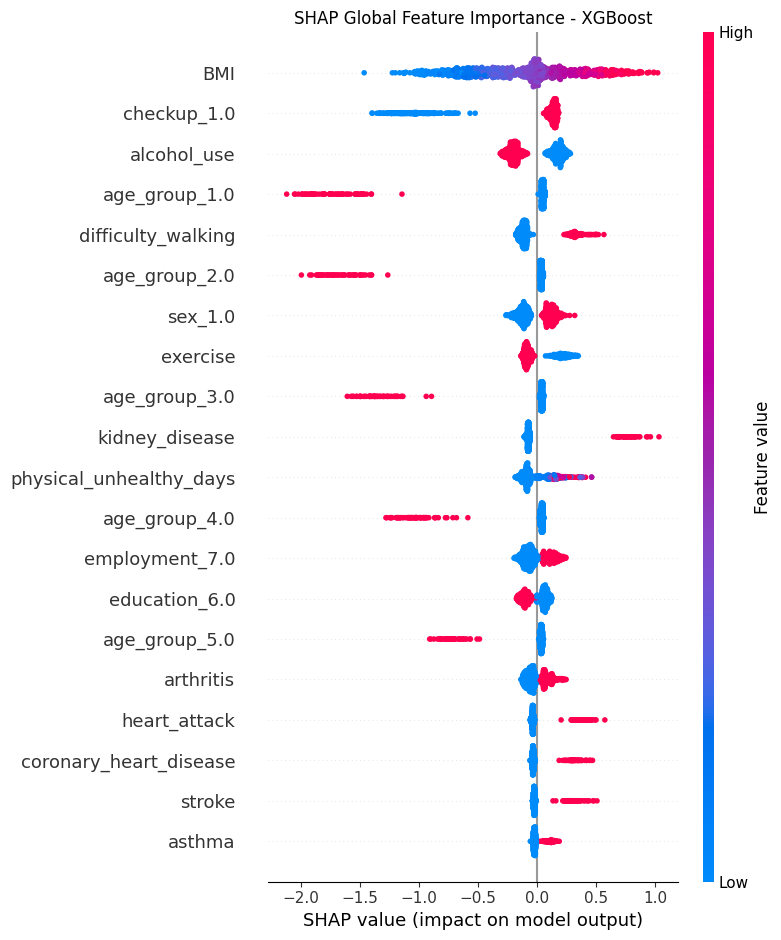

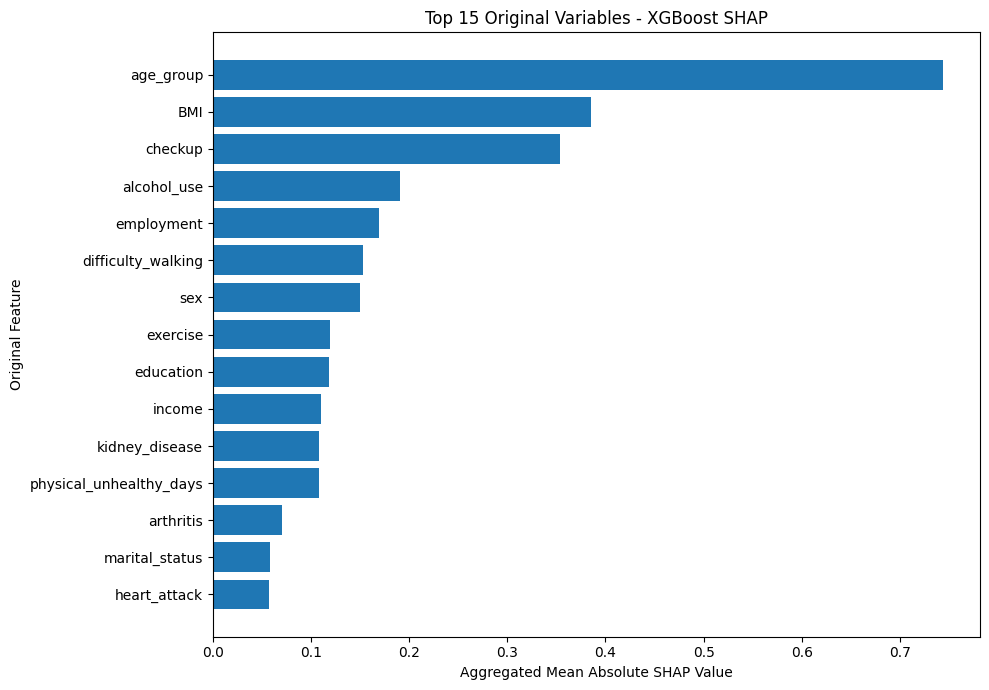


TOP 15 ORIGINAL FEATURES
       original_feature  mean_abs_shap
              age_group       0.744354
                    BMI       0.384914
                checkup       0.353955
            alcohol_use       0.190868
             employment       0.169407
     difficulty_walking       0.153072
                    sex       0.150176
               exercise       0.119141
              education       0.118628
                 income       0.109702
         kidney_disease       0.108476
physical_unhealthy_days       0.107666
              arthritis       0.070906
         marital_status       0.058648
           heart_attack       0.057003

SHAP analysis saved to: /content/drive/MyDrive/Diabetes_BigData_Project/results/explainability


In [ ]:

# ============================================================
# PHASE 6.1 — SHAP GLOBAL EXPLAINABILITY
# ============================================================

!pip install -q shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import gc

# 1. Verify trained model and test data exist
assert "final_xgb" in globals(), "Final XGBoost model not found."
assert "X_test_full" in globals(), "Transformed test data not found."
assert "full_preprocessor" in globals(), "Preprocessor not found."

# 2. Select a representative test sample
np.random.seed(42)

sample_size = min(1000, len(X_test_full))
sample_indices = np.random.choice(
    len(X_test_full),
    size=sample_size,
    replace=False
)

X_shap = X_test_full[sample_indices]

# 3. Obtain transformed feature names
feature_names = full_preprocessor.get_feature_names_out()

print("SHAP sample:", X_shap.shape)
print("Number of transformed features:", len(feature_names))

# 4. Create TreeExplainer
explainer = shap.TreeExplainer(final_xgb)

print("Calculating SHAP values...")

shap_values = explainer.shap_values(X_shap)

if isinstance(shap_values, list):
    shap_values = shap_values[-1]

shap_values = np.asarray(shap_values)

print("SHAP values shape:", shap_values.shape)

# 5. Save results directory
SHAP_DIR = os.path.join(
    PROJECT_DIR, "results", "explainability"
)

os.makedirs(SHAP_DIR, exist_ok=True)

# 6. SHAP summary plot
plt.figure(figsize=(12, 9))

shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Global Feature Importance - XGBoost")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "shap_summary_xgboost.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# 7. Calculate mean absolute SHAP importance
mean_abs_shap = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "transformed_feature": feature_names,
    "mean_abs_shap": mean_abs_shap
})

importance_df = importance_df.sort_values(
    "mean_abs_shap",
    ascending=False
)

# 8. Aggregate one-hot features into original variables
def identify_original_feature(transformed_name):

    for col in sorted(feature_cols, key=len, reverse=True):
        if (
            transformed_name == col
            or transformed_name.startswith(col + "_")
        ):
            return col

    return "Unmapped"

importance_df["original_feature"] = (
    importance_df["transformed_feature"]
    .map(identify_original_feature)
)

aggregated_importance = (
    importance_df
    .groupby("original_feature", as_index=False)["mean_abs_shap"]
    .sum()
    .sort_values("mean_abs_shap", ascending=False)
)

# 9. Save importance tables
importance_df.to_csv(
    os.path.join(SHAP_DIR, "shap_transformed_features.csv"),
    index=False
)

aggregated_importance.to_csv(
    os.path.join(SHAP_DIR, "shap_original_features.csv"),
    index=False
)

# 10. Plot original-variable importance
top_features = aggregated_importance.head(15).sort_values(
    "mean_abs_shap"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["original_feature"],
    top_features["mean_abs_shap"]
)

plt.xlabel("Aggregated Mean Absolute SHAP Value")
plt.ylabel("Original Feature")
plt.title("Top 15 Original Variables - XGBoost SHAP")

plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "shap_original_features.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("\nTOP 15 ORIGINAL FEATURES")
print(aggregated_importance.head(15).to_string(index=False))

print("\nSHAP analysis saved to:", SHAP_DIR)


<Figure size 900x600 with 0 Axes>

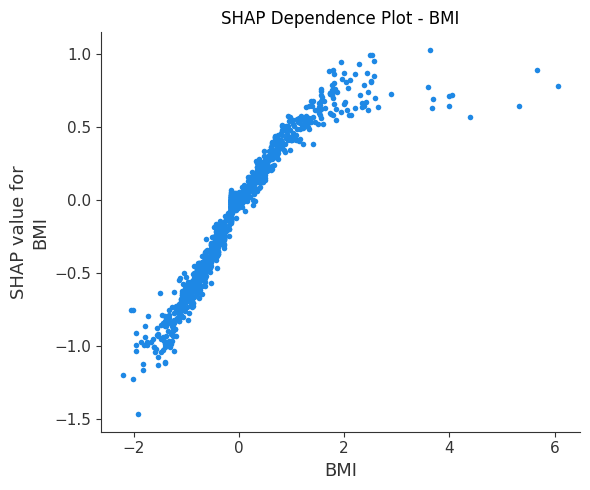

Age-group encoded features:
['age_group_1.0', 'age_group_2.0', 'age_group_3.0', 'age_group_4.0', 'age_group_5.0', 'age_group_6.0', 'age_group_7.0', 'age_group_8.0', 'age_group_9.0', 'age_group_10.0', 'age_group_11.0', 'age_group_12.0', 'age_group_13.0', 'age_group_14.0']


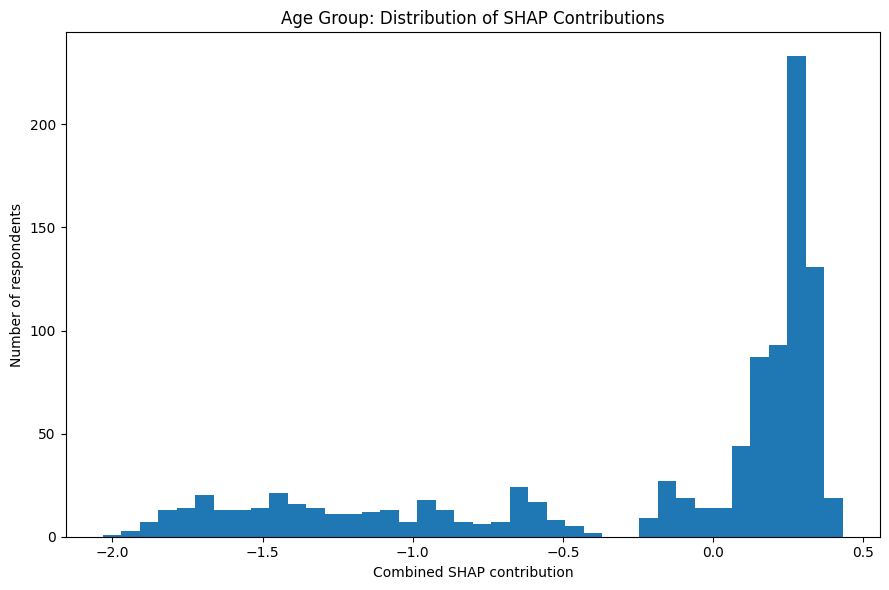

Directional analysis completed.


In [ ]:

# ============================================================
# PHASE 6.2 — SHAP DIRECTIONAL ANALYSIS
# ============================================================

import shap
import matplotlib.pyplot as plt
import numpy as np
import os

# Identify the transformed BMI feature
bmi_idx = list(feature_names).index("BMI")

# BMI dependence plot
plt.figure(figsize=(9, 6))

shap.dependence_plot(
    bmi_idx,
    shap_values,
    X_shap,
    feature_names=feature_names,
    interaction_index=None,
    show=False
)

plt.title("SHAP Dependence Plot - BMI")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "shap_bmi_dependence.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# AGE GROUP — ENCODED FEATURES
# ============================================================

age_indices = [
    i for i, name in enumerate(feature_names)
    if name.startswith("age_group_")
]

print("Age-group encoded features:")
print([feature_names[i] for i in age_indices])

# Aggregate signed SHAP contributions for age group
age_group_shap = shap_values[:, age_indices].sum(axis=1)

plt.figure(figsize=(9, 6))

plt.hist(
    age_group_shap,
    bins=40
)

plt.xlabel("Combined SHAP contribution")
plt.ylabel("Number of respondents")
plt.title("Age Group: Distribution of SHAP Contributions")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "shap_age_group_distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Directional analysis completed.")


CORRECTED GROUPED SHAP RANKING
               variable  mean_absolute_grouped_shap  mean_signed_shap
              age_group                    0.539298         -0.229647
                    BMI                    0.384915         -0.109350
                checkup                    0.333063         -0.110090
            alcohol_use                    0.190867         -0.018562
     difficulty_walking                    0.153072         -0.038576
                    sex                    0.150176         -0.002556
             employment                    0.134326         -0.029017
               exercise                    0.119141         -0.005192
         kidney_disease                    0.108476         -0.034343
physical_unhealthy_days                    0.107666         -0.024565
              education                    0.091830         -0.007586
              arthritis                    0.070906         -0.008054
                 income                    0.067286        

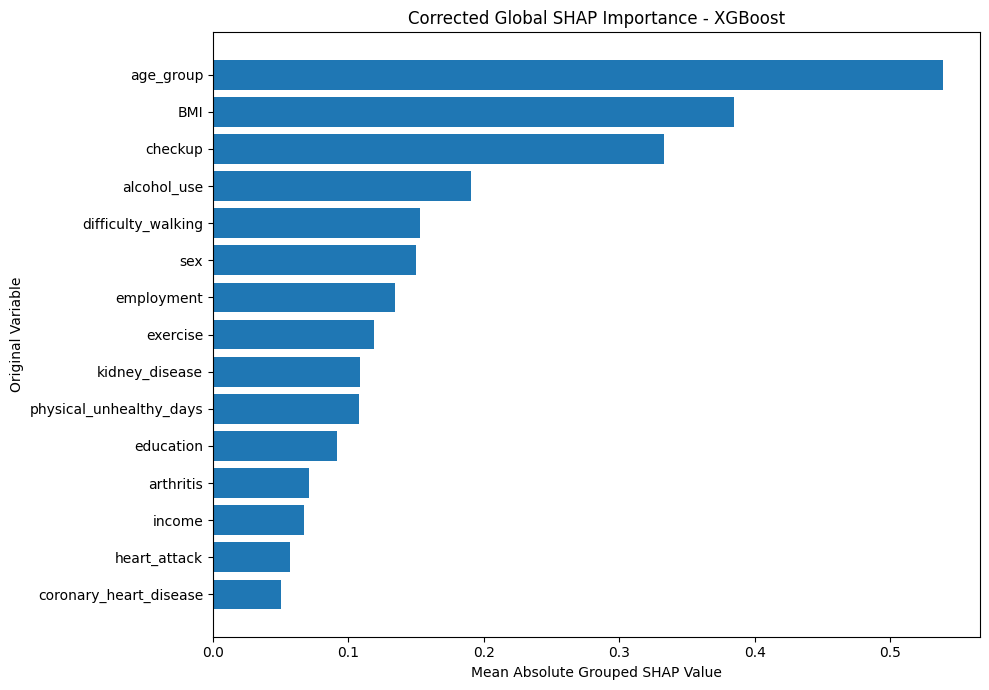


AGE GROUP CONTRIBUTION ANALYSIS
 age_group  respondent_count  mean_shap  mean_absolute_shap
       1.0                75  -1.649235            1.649235
       2.0                54  -1.591095            1.591095
       3.0                55  -1.255803            1.255803
       4.0                66  -0.930895            0.930895
       5.0                60  -0.604167            0.604167
       6.0                51  -0.138315            0.138332
      14.0                 5  -0.056794            0.056794
      13.0               103   0.087130            0.101959
       7.0                70   0.163262            0.163262
       8.0                79   0.240225            0.240225
       9.0                99   0.281380            0.281380
      10.0               112   0.300094            0.300094
      11.0                81   0.305774            0.305774
      12.0                90   0.316070            0.316070

Saved corrected SHAP analysis.


In [ ]:

# ============================================================
# PHASE 6.3 — CORRECTED GROUPED SHAP ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Map every encoded feature to its original variable
def get_original_variable(name):
    for col in sorted(feature_cols, key=len, reverse=True):
        if name == col or name.startswith(col + "_"):
            return col
    return "Unmapped"

original_variables = [
    get_original_variable(name)
    for name in feature_names
]

# 2. Sum signed SHAP values within each original variable
grouped_shap = {}

for variable in sorted(set(original_variables)):
    indices = [
        i for i, original in enumerate(original_variables)
        if original == variable
    ]

    grouped_shap[variable] = shap_values[:, indices].sum(axis=1)

# 3. Calculate importance after grouping
grouped_results = []

for variable, contributions in grouped_shap.items():
    grouped_results.append({
        "variable": variable,
        "mean_absolute_grouped_shap": np.mean(
            np.abs(contributions)
        ),
        "mean_signed_shap": np.mean(contributions)
    })

grouped_df = pd.DataFrame(grouped_results)

grouped_df = grouped_df.sort_values(
    "mean_absolute_grouped_shap",
    ascending=False
)

print("CORRECTED GROUPED SHAP RANKING")
print(grouped_df.head(20).to_string(index=False))

grouped_df.to_csv(
    os.path.join(SHAP_DIR, "corrected_grouped_shap.csv"),
    index=False
)

# 4. Plot corrected global importance
plot_df = grouped_df.head(15).sort_values(
    "mean_absolute_grouped_shap"
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["variable"],
    plot_df["mean_absolute_grouped_shap"]
)

plt.xlabel("Mean Absolute Grouped SHAP Value")
plt.ylabel("Original Variable")
plt.title("Corrected Global SHAP Importance - XGBoost")

plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "corrected_grouped_shap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ============================================================
# 5. AGE-GROUP DIRECTIONAL ANALYSIS
# ============================================================

age_contributions = grouped_shap["age_group"]

age_analysis = pd.DataFrame({
    "age_group": X_test.iloc[sample_indices]["age_group"].values,
    "age_shap": age_contributions
})

age_summary = (
    age_analysis
    .groupby("age_group", dropna=False)
    .agg(
        respondent_count=("age_shap", "size"),
        mean_shap=("age_shap", "mean"),
        mean_absolute_shap=(
            "age_shap",
            lambda x: np.mean(np.abs(x))
        )
    )
    .reset_index()
    .sort_values("mean_shap")
)

print("\nAGE GROUP CONTRIBUTION ANALYSIS")
print(age_summary.to_string(index=False))

age_summary.to_csv(
    os.path.join(SHAP_DIR, "age_group_shap_analysis.csv"),
    index=False
)

print("\nSaved corrected SHAP analysis.")


Test respondents: 117673
Classification threshold: 0.22999999999999995

-----------------------------------
CASE: True_Positive
Actual: 1
Predicted: 1
Probability: 0.3311


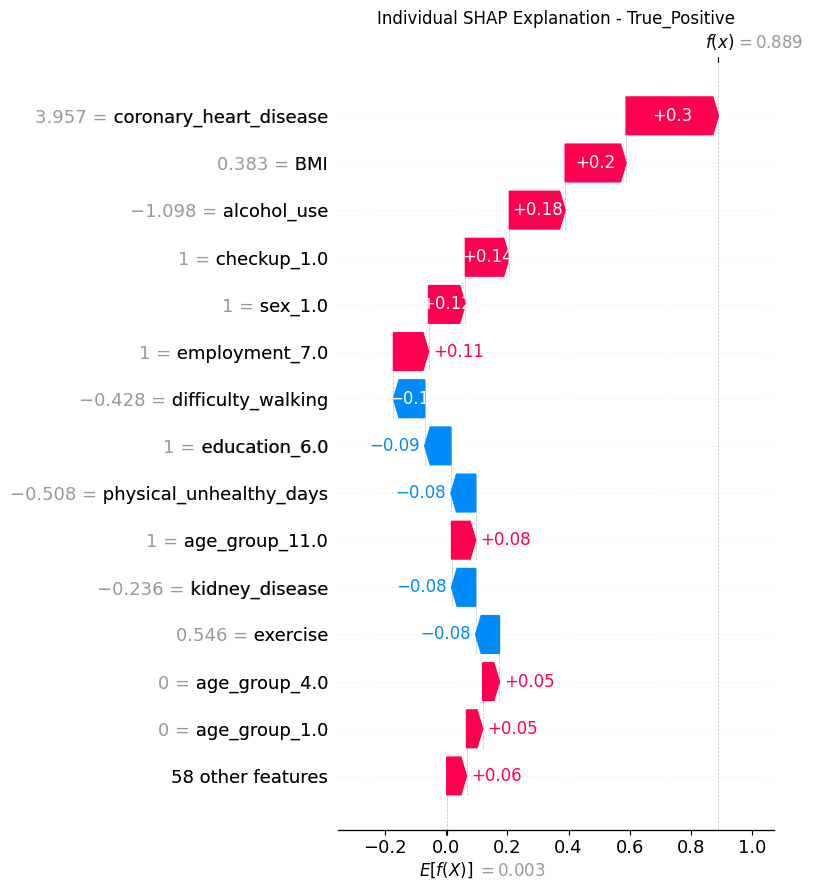


-----------------------------------
CASE: False_Positive
Actual: 0
Predicted: 1
Probability: 0.2581


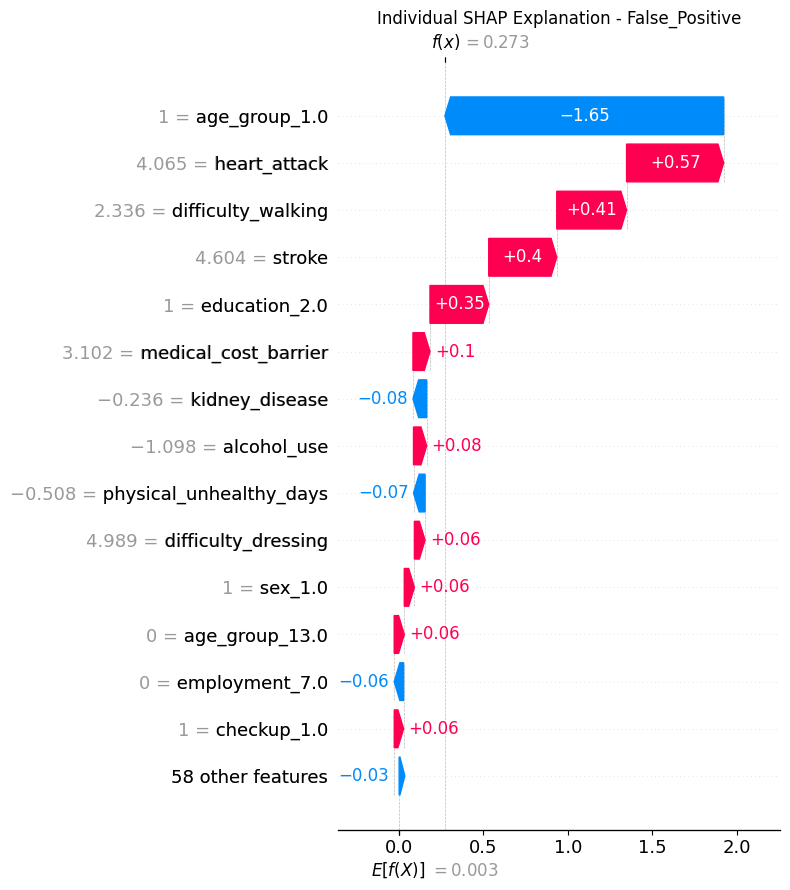


-----------------------------------
CASE: False_Negative
Actual: 1
Predicted: 0
Probability: 0.1018


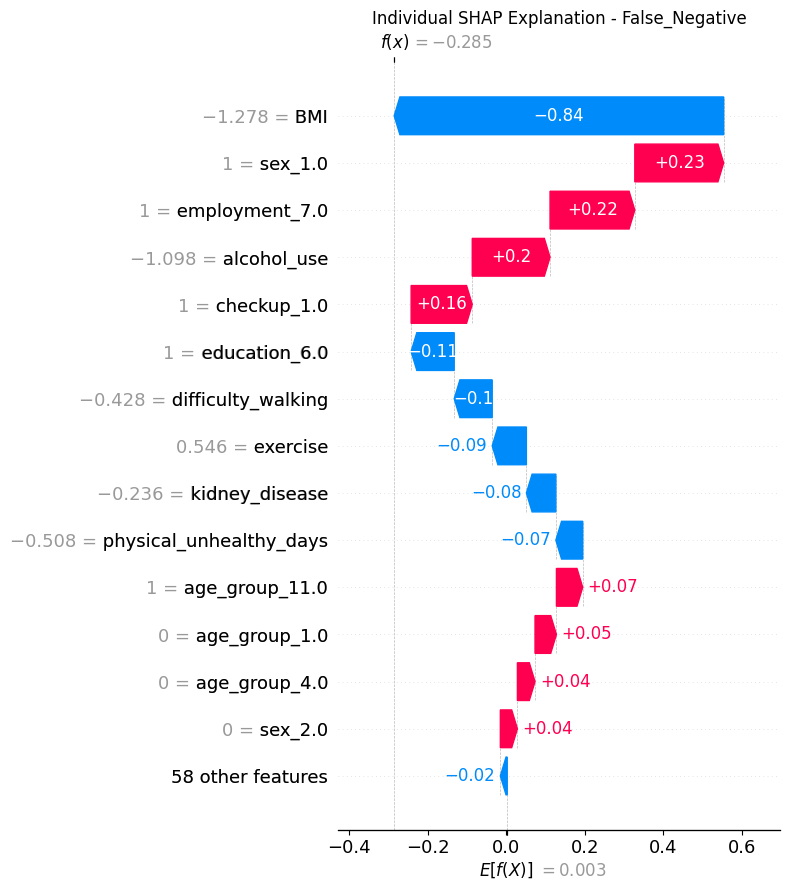


Individual explanations saved.

FAIRNESS BY AGE GROUP
group  sample_count  ROC_AUC   PR_AUC  recall_TPR  specificity_TNR      FPR      FNR       F1
  1.0          7952 0.693027 0.080729    0.029412         0.999108 0.000892 0.970588 0.053571
  2.0          6223 0.741564 0.075341    0.016000         0.999180 0.000820 0.984000 0.030303
  3.0          6609 0.804158 0.151677    0.087629         0.995635 0.004365 0.912371 0.142259
  4.0          7360 0.786929 0.181040    0.140244         0.980944 0.019056 0.859756 0.181102
  5.0          7690 0.778317 0.256751    0.309689         0.945726 0.054274 0.690311 0.313211
  6.0          7251 0.792783 0.323371    0.446891         0.886557 0.113443 0.553109 0.372570
  7.0          7902 0.780657 0.410883    0.583401         0.798891 0.201109 0.416599 0.436131
  8.0          8637 0.766004 0.435319    0.644458         0.735599 0.264401 0.355542 0.460000
  9.0         10886 0.762191 0.460403    0.680995         0.701475 0.298525 0.319005 0.477399
 10.0

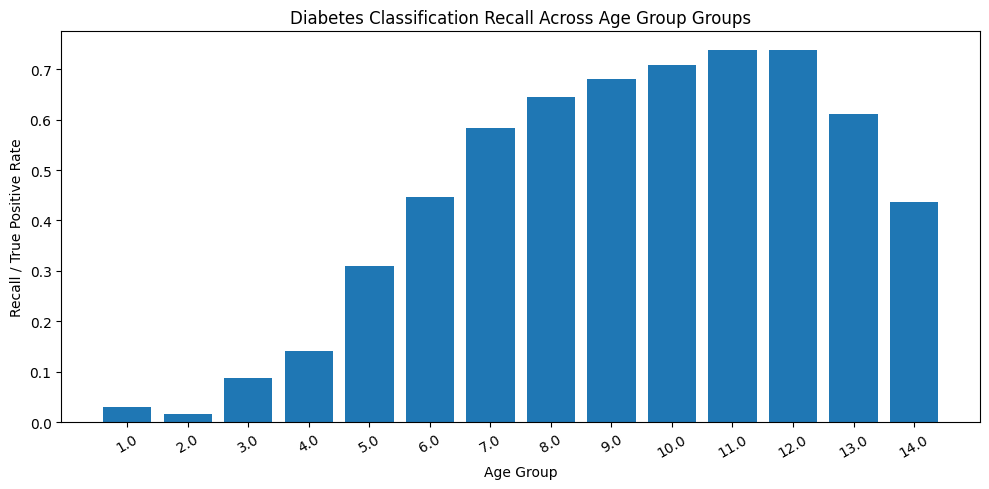

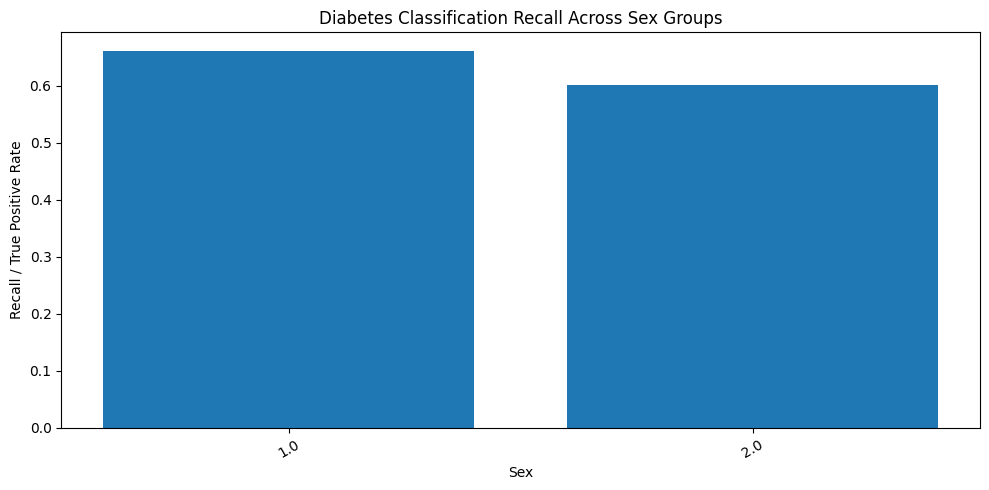


PHASE 6 EXPERIMENTS COMPLETED
Individual SHAP: /content/drive/MyDrive/Diabetes_BigData_Project/results/explainability/individual_explanations
Fairness results: /content/drive/MyDrive/Diabetes_BigData_Project/results/fairness

All outputs saved successfully.


In [ ]:

# ================================================================
# PHASE 6.4 + 6.5
# INDIVIDUAL SHAP EXPLANATIONS + DEMOGRAPHIC FAIRNESS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix
)

# ------------------------------------------------
# 1. SETUP AND VALIDATION
# ------------------------------------------------

FAIRNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "fairness"
)

INDIVIDUAL_DIR = os.path.join(
    SHAP_DIR, "individual_explanations"
)

os.makedirs(FAIRNESS_DIR, exist_ok=True)
os.makedirs(INDIVIDUAL_DIR, exist_ok=True)

assert len(test_pd) == len(test_probability)
assert len(test_pd) == len(y_test)

print("Test respondents:", len(test_pd))
print("Classification threshold:", best_threshold)

# ------------------------------------------------
# 2. INDIVIDUAL SHAP EXPLANATIONS
# ------------------------------------------------

# Reuse the existing TreeExplainer
# Select representative TP, FP and FN cases
sample_y = y_test[sample_indices]
sample_predictions = (
    test_probability[sample_indices] >= best_threshold
).astype(int)

case_types = {
    "True_Positive": np.where(
        (sample_y == 1) & (sample_predictions == 1)
    )[0],

    "False_Positive": np.where(
        (sample_y == 0) & (sample_predictions == 1)
    )[0],

    "False_Negative": np.where(
        (sample_y == 1) & (sample_predictions == 0)
    )[0]
}

individual_records = []

for case_name, candidates in case_types.items():

    if len(candidates) == 0:
        print("No available example for:", case_name)
        continue

    # Select a representative respondent
    selected_position = candidates[0]

    global_index = sample_indices[selected_position]

    x_row = X_shap[selected_position:selected_position + 1]

    row_shap = shap_values[selected_position]

    actual = int(y_test[global_index])
    probability = float(test_probability[global_index])
    predicted = int(probability >= best_threshold)

    print("\n-----------------------------------")
    print("CASE:", case_name)
    print("Actual:", actual)
    print("Predicted:", predicted)
    print("Probability:", round(probability, 4))

    # Waterfall explanation
    base_value = explainer.expected_value

    if isinstance(base_value, (list, np.ndarray)):
        base_value = np.asarray(base_value).flatten()[-1]

    explanation = shap.Explanation(
        values=row_shap,
        base_values=float(base_value),
        data=x_row[0],
        feature_names=feature_names
    )

    plt.figure(figsize=(11, 7))

    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False
    )

    plt.title(
        f"Individual SHAP Explanation - {case_name}"
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            INDIVIDUAL_DIR,
            f"{case_name.lower()}_waterfall.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    # Extract the strongest individual contributions
    top_indices = np.argsort(
        np.abs(row_shap)
    )[::-1][:10]

    for rank, idx in enumerate(top_indices, start=1):

        individual_records.append({
            "case": case_name,
            "rank": rank,
            "feature": feature_names[idx],
            "shap_value": float(row_shap[idx]),
            "actual": actual,
            "predicted": predicted,
            "predicted_probability": probability
        })


individual_df = pd.DataFrame(individual_records)

individual_df.to_csv(
    os.path.join(
        INDIVIDUAL_DIR,
        "individual_shap_explanations.csv"
    ),
    index=False
)

print("\nIndividual explanations saved.")

# ------------------------------------------------
# 3. PREPARE FAIRNESS EVALUATION DATA
# ------------------------------------------------

fairness_data = test_pd.copy().reset_index(drop=True)

fairness_data["actual"] = y_test
fairness_data["probability"] = test_probability

fairness_data["prediction"] = (
    fairness_data["probability"] >= best_threshold
).astype(int)

# ------------------------------------------------
# 4. FAIRNESS METRICS FUNCTION
# ------------------------------------------------

def calculate_group_metrics(group):

    y_true = group["actual"].to_numpy()
    y_pred = group["prediction"].to_numpy()
    y_prob = group["probability"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    result = {
        "sample_count": len(group),
        "positive_count": int(np.sum(y_true == 1)),
        "negative_count": int(np.sum(y_true == 0)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall_TPR": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity_TNR": (
            tn / (tn + fp) if (tn + fp) else np.nan
        ),
        "FPR": (
            fp / (fp + tn) if (fp + tn) else np.nan
        ),
        "FNR": (
            fn / (fn + tp) if (fn + tp) else np.nan
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "prediction_positive_rate": np.mean(y_pred)
    }

    # AUC metrics require both target classes
    if len(np.unique(y_true)) == 2:

        result["ROC_AUC"] = roc_auc_score(
            y_true, y_prob
        )

        result["PR_AUC"] = average_precision_score(
            y_true, y_prob
        )

    else:
        result["ROC_AUC"] = np.nan
        result["PR_AUC"] = np.nan

    return result


# ------------------------------------------------
# 5. FAIRNESS BY AGE GROUP
# ------------------------------------------------

def evaluate_attribute(data, attribute, min_group_size=100):

    records = []

    for group_value, group in data.groupby(
        attribute,
        dropna=False
    ):

        if len(group) < min_group_size:
            continue

        metrics = calculate_group_metrics(group)

        metrics["attribute"] = attribute
        metrics["group"] = str(group_value)

        records.append(metrics)

    return pd.DataFrame(records)


age_fairness = evaluate_attribute(
    fairness_data,
    "age_group"
)

sex_fairness = evaluate_attribute(
    fairness_data,
    "sex"
)

# ------------------------------------------------
# 6. INTERSECTIONAL FAIRNESS
# ------------------------------------------------

intersectional_fairness = (
    fairness_data
    .groupby(
        ["age_group", "sex"],
        dropna=False
    )
    .filter(lambda x: len(x) >= 500)
    .groupby(
        ["age_group", "sex"],
        dropna=False
    )
    .apply(
        lambda group: pd.Series(
            calculate_group_metrics(group)
        ),
        include_groups=False
    )
    .reset_index()
)

# ------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------

print("\n========================================")
print("FAIRNESS BY AGE GROUP")
print("========================================")

print(
    age_fairness[
        [
            "group",
            "sample_count",
            "ROC_AUC",
            "PR_AUC",
            "recall_TPR",
            "specificity_TNR",
            "FPR",
            "FNR",
            "F1"
        ]
    ].to_string(index=False)
)

print("\n========================================")
print("FAIRNESS BY SEX")
print("========================================")

print(
    sex_fairness[
        [
            "group",
            "sample_count",
            "ROC_AUC",
            "PR_AUC",
            "recall_TPR",
            "specificity_TNR",
            "FPR",
            "FNR",
            "F1"
        ]
    ].to_string(index=False)
)

print("\n========================================")
print("INTERSECTIONAL FAIRNESS")
print("========================================")

print(intersectional_fairness.to_string(index=False))

# ------------------------------------------------
# 8. FAIRNESS GAP SUMMARY
# ------------------------------------------------

def calculate_fairness_gaps(df, name):

    metrics = [
        "recall_TPR",
        "specificity_TNR",
        "FPR",
        "FNR",
        "prediction_positive_rate"
    ]

    rows = []

    for metric in metrics:

        values = df[metric].dropna()

        if len(values) < 2:
            continue

        rows.append({
            "attribute": name,
            "metric": metric,
            "minimum": values.min(),
            "maximum": values.max(),
            "absolute_gap": values.max() - values.min()
        })

    return pd.DataFrame(rows)


fairness_gaps = pd.concat(
    [
        calculate_fairness_gaps(
            age_fairness, "age_group"
        ),
        calculate_fairness_gaps(
            sex_fairness, "sex"
        )
    ],
    ignore_index=True
)

print("\n========================================")
print("FAIRNESS GAP SUMMARY")
print("========================================")

print(fairness_gaps.to_string(index=False))

# ------------------------------------------------
# 9. VISUALIZE RECALL DIFFERENCES
# ------------------------------------------------

for df, attribute in [
    (age_fairness, "Age Group"),
    (sex_fairness, "Sex")
]:

    if len(df) == 0:
        continue

    plt.figure(figsize=(10, 5))

    plt.bar(
        df["group"],
        df["recall_TPR"]
    )

    plt.ylabel("Recall / True Positive Rate")
    plt.xlabel(attribute)
    plt.title(
        f"Diabetes Classification Recall Across {attribute} Groups"
    )

    plt.xticks(rotation=30)
    plt.tight_layout()

    filename = (
        "recall_by_age.png"
        if attribute == "Age Group"
        else "recall_by_sex.png"
    )

    plt.savefig(
        os.path.join(FAIRNESS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------
# 10. SAVE ALL FAIRNESS RESULTS
# ------------------------------------------------

age_fairness.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_by_age.csv"),
    index=False
)

sex_fairness.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_by_sex.csv"),
    index=False
)

intersectional_fairness.to_csv(
    os.path.join(
        FAIRNESS_DIR,
        "intersectional_fairness.csv"
    ),
    index=False
)

fairness_gaps.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_gaps.csv"),
    index=False
)

# Save evaluation configuration
evaluation_config = {
    "model": "XGBoost",
    "threshold": float(best_threshold),
    "test_size": len(fairness_data),
    "minimum_intersectional_group_size": 500,
    "metrics": [
        "ROC_AUC",
        "PR_AUC",
        "Recall",
        "Specificity",
        "FPR",
        "FNR",
        "F1"
    ]
}

import json

with open(
    os.path.join(FAIRNESS_DIR, "evaluation_config.json"),
    "w"
) as f:
    json.dump(evaluation_config, f, indent=4)

print("\n========================================")
print("PHASE 6 EXPERIMENTS COMPLETED")
print("========================================")

print("Individual SHAP:", INDIVIDUAL_DIR)
print("Fairness results:", FAIRNESS_DIR)

print("\nAll outputs saved successfully.")


Starting Phase 6 final analysis...
Test respondents: 117673
Threshold: 0.22999999999999995

CASE: True_Positive
Actual: 1
Prediction: 1
Probability: 0.3746


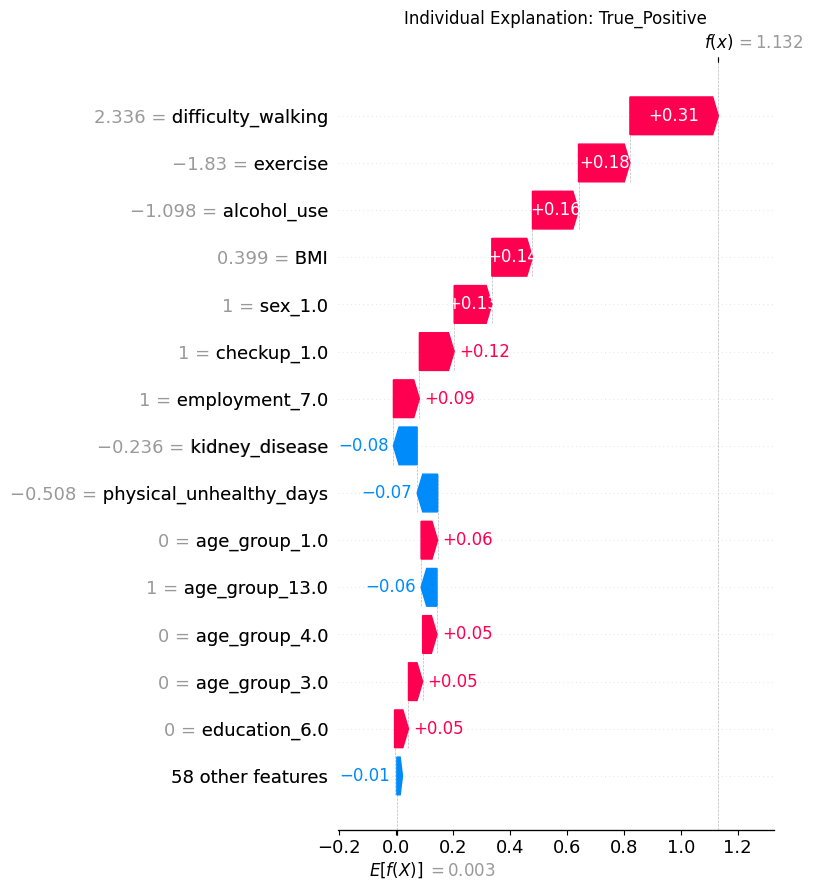


CASE: False_Positive
Actual: 0
Prediction: 1
Probability: 0.3355


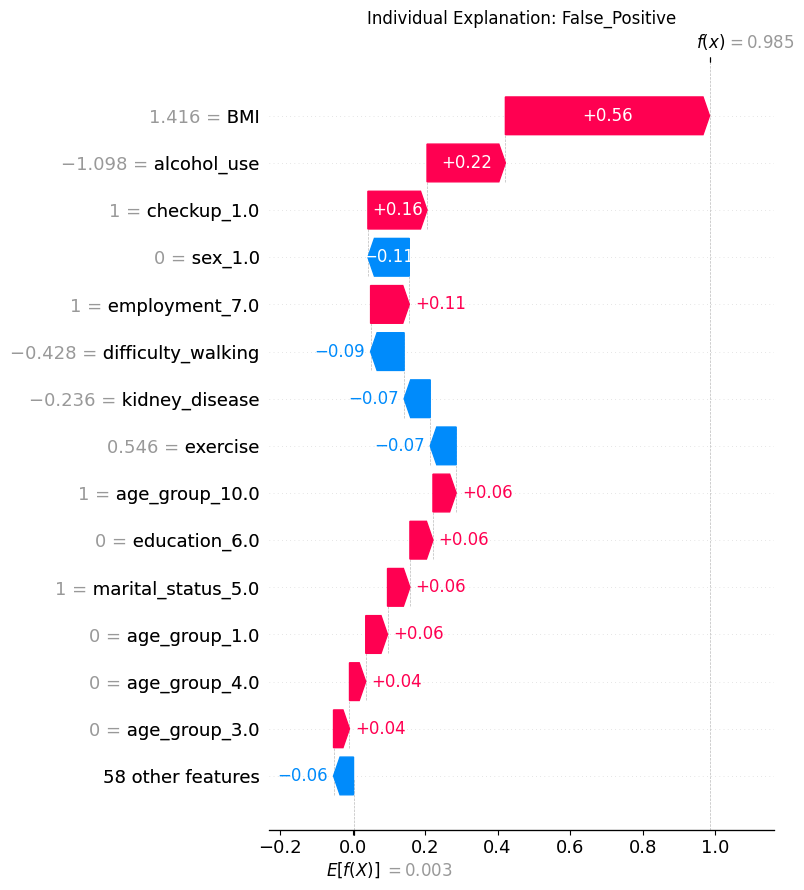


CASE: False_Negative
Actual: 1
Prediction: 0
Probability: 0.0944


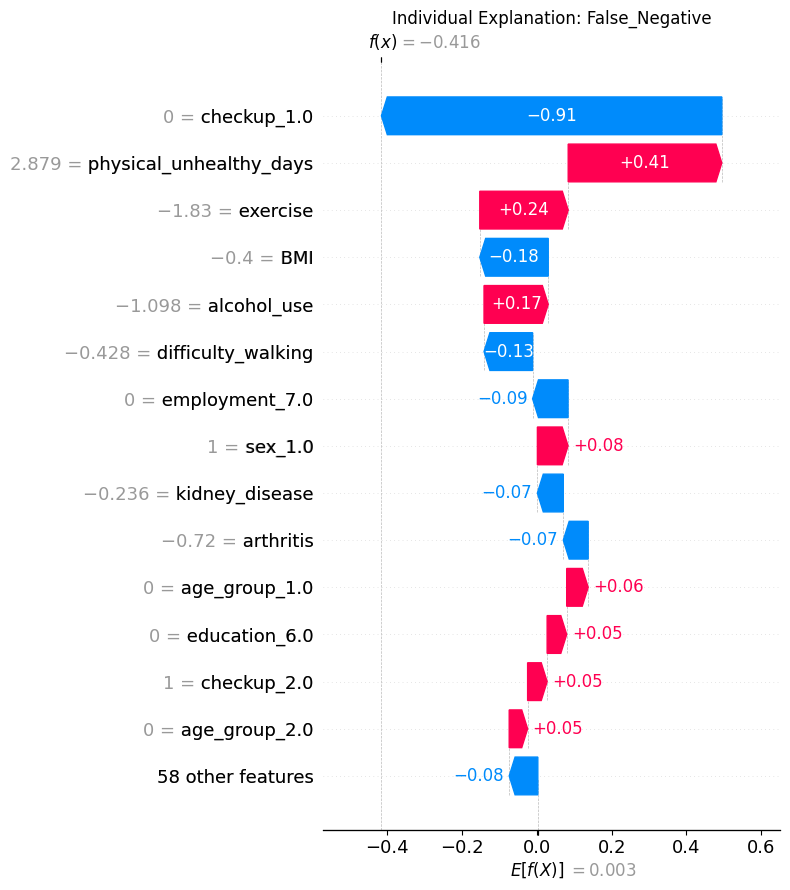


CASE: True_Negative
Actual: 0
Prediction: 0
Probability: 0.041


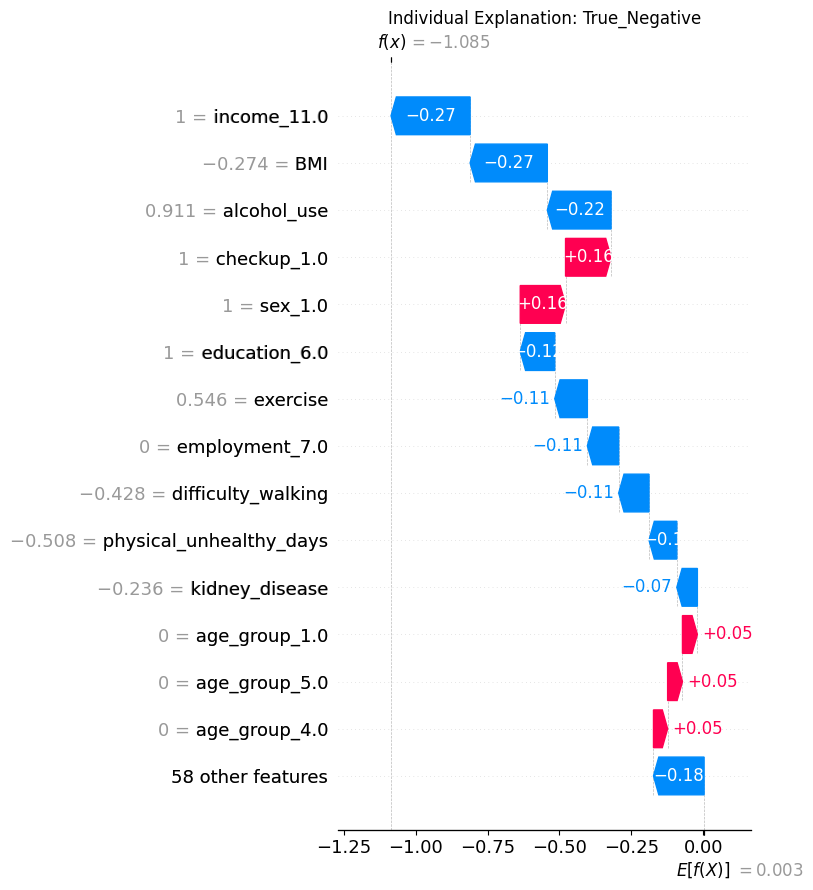


========== AGE GROUP FAIRNESS ==========
    n  positive_cases  negative_cases  accuracy  precision  recall_TPR  specificity_TNR      FPR      FNR       F1  positive_prediction_rate  observed_positive_rate  ROC_AUC   PR_AUC age_group
 7952             102            7850  0.986670   0.300000    0.029412         0.999108 0.000892 0.970588 0.053571                  0.001258                0.012827 0.693027 0.080729       1.0
 6223             125            6098  0.979431   0.285714    0.016000         0.999180 0.000820 0.984000 0.030303                  0.001125                0.020087 0.741564 0.075341       2.0
 6609             194            6415  0.968982   0.377778    0.087629         0.995635 0.004365 0.912371 0.142259                  0.006809                0.029354 0.804158 0.151677       3.0
 7360             328            7032  0.943478   0.255556    0.140244         0.980944 0.019056 0.859756 0.181102                  0.024457                0.044565 0.786929 0.181040    

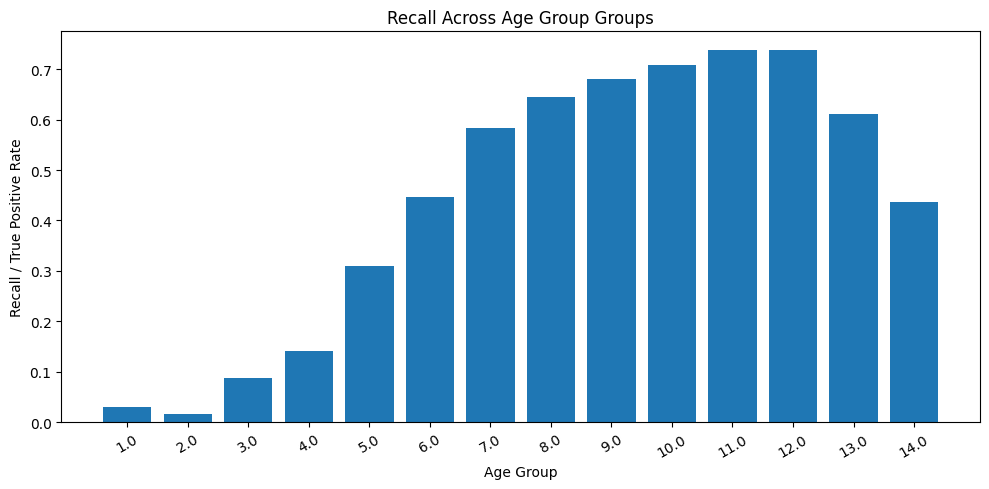

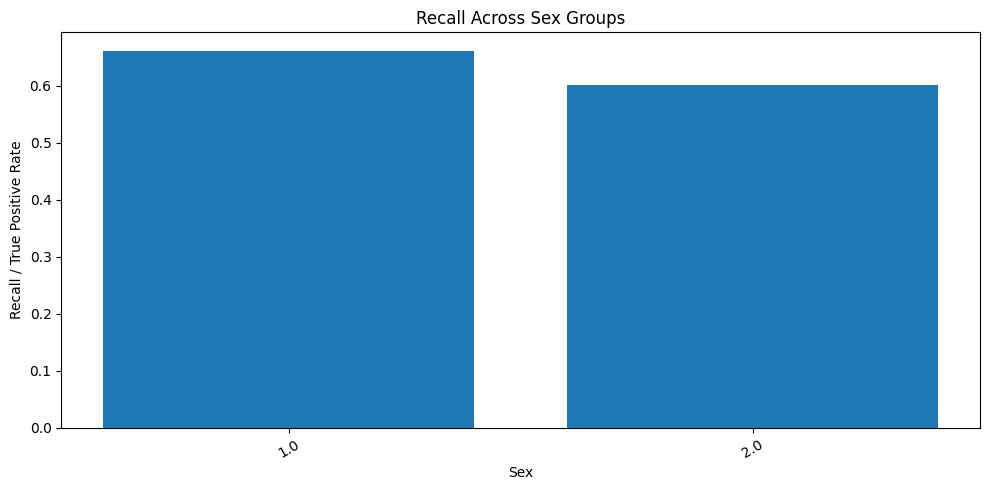


PHASE 6 INDIVIDUAL + FAIRNESS ANALYSIS DONE
Individual explanations: /content/drive/MyDrive/Diabetes_BigData_Project/results/explainability/individual_explanations
Fairness outputs: /content/drive/MyDrive/Diabetes_BigData_Project/results/fairness
All results saved to Google Drive.


In [ ]:

# ================================================================
# PHASE 6 FINAL: INDIVIDUAL SHAP + FAIRNESS ANALYSIS
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import json

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix
)

# ------------------------------------------------
# 1. CHECK REQUIRED OBJECTS
# ------------------------------------------------

required = [
    "final_xgb", "explainer", "shap_values",
    "X_shap", "sample_indices", "test_probability",
    "y_test", "test_pd", "best_threshold",
    "feature_names", "SHAP_DIR", "PROJECT_DIR"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise ValueError(
        f"Missing objects: {missing}. "
        "Run the earlier SHAP/model cells first."
    )

FAIRNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "fairness"
)

INDIVIDUAL_DIR = os.path.join(
    SHAP_DIR, "individual_explanations"
)

os.makedirs(FAIRNESS_DIR, exist_ok=True)
os.makedirs(INDIVIDUAL_DIR, exist_ok=True)

print("Starting Phase 6 final analysis...")
print("Test respondents:", len(y_test))
print("Threshold:", best_threshold)

# ------------------------------------------------
# 2. INDIVIDUAL SHAP CASE SELECTION
# ------------------------------------------------

sample_actual = y_test[sample_indices]
sample_probability = test_probability[sample_indices]

sample_prediction = (
    sample_probability >= best_threshold
).astype(int)

case_masks = {
    "True_Positive": (
        (sample_actual == 1) & (sample_prediction == 1)
    ),
    "False_Positive": (
        (sample_actual == 0) & (sample_prediction == 1)
    ),
    "False_Negative": (
        (sample_actual == 1) & (sample_prediction == 0)
    ),
    "True_Negative": (
        (sample_actual == 0) & (sample_prediction == 0)
    )
}

individual_records = []

base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[-1]

for case_name, mask in case_masks.items():

    candidates = np.where(mask)[0]

    if len(candidates) == 0:
        print("No example available:", case_name)
        continue

    # Select respondent closest to the median probability
    candidate_probabilities = sample_probability[candidates]

    median_probability = np.median(candidate_probabilities)

    selected_position = candidates[
        np.argmin(
            np.abs(candidate_probabilities - median_probability)
        )
    ]

    global_index = sample_indices[selected_position]

    row_values = shap_values[selected_position]
    row_data = X_shap[selected_position]

    actual = int(y_test[global_index])
    probability = float(test_probability[global_index])
    prediction = int(probability >= best_threshold)

    print("\n", "=" * 50)
    print("CASE:", case_name)
    print("Actual:", actual)
    print("Prediction:", prediction)
    print("Probability:", round(probability, 4))

    explanation = shap.Explanation(
        values=row_values,
        base_values=float(base_value),
        data=row_data,
        feature_names=feature_names
    )

    plt.figure(figsize=(11, 7))

    shap.plots.waterfall(
        explanation,
        max_display=15,
        show=False
    )

    plt.title(f"Individual Explanation: {case_name}")
    plt.tight_layout()

    plt.savefig(
        os.path.join(
            INDIVIDUAL_DIR,
            f"{case_name.lower()}_waterfall.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    top_indices = np.argsort(
        np.abs(row_values)
    )[::-1][:15]

    for rank, idx in enumerate(top_indices, start=1):

        individual_records.append({
            "case": case_name,
            "rank": rank,
            "transformed_feature": feature_names[idx],
            "shap_value": float(row_values[idx]),
            "actual": actual,
            "prediction": prediction,
            "probability": probability,
            "test_row_index": int(global_index)
        })

individual_df = pd.DataFrame(individual_records)

individual_df.to_csv(
    os.path.join(
        INDIVIDUAL_DIR,
        "individual_shap_cases.csv"
    ),
    index=False
)

# ------------------------------------------------
# 3. PREPARE FAIRNESS DATA
# ------------------------------------------------

fairness_data = test_pd.reset_index(drop=True).copy()

fairness_data["actual"] = y_test
fairness_data["probability"] = test_probability

fairness_data["prediction"] = (
    fairness_data["probability"] >= best_threshold
).astype(int)

# ------------------------------------------------
# 4. FAIRNESS METRICS
# ------------------------------------------------

def fairness_metrics(group):

    y_true = group["actual"].to_numpy()
    y_pred = group["prediction"].to_numpy()
    y_prob = group["probability"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    result = {
        "n": len(group),
        "positive_cases": int((y_true == 1).sum()),
        "negative_cases": int((y_true == 0).sum()),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "recall_TPR": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "specificity_TNR": (
            tn / (tn + fp) if tn + fp else np.nan
        ),
        "FPR": (
            fp / (fp + tn) if fp + tn else np.nan
        ),
        "FNR": (
            fn / (fn + tp) if fn + tp else np.nan
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "positive_prediction_rate": np.mean(y_pred),
        "observed_positive_rate": np.mean(y_true)
    }

    if len(np.unique(y_true)) == 2:
        result["ROC_AUC"] = roc_auc_score(y_true, y_prob)
        result["PR_AUC"] = average_precision_score(
            y_true, y_prob
        )
    else:
        result["ROC_AUC"] = np.nan
        result["PR_AUC"] = np.nan

    return result


def evaluate_groups(data, columns, min_size=100):

    records = []

    grouped = data.groupby(
        columns,
        dropna=False,
        observed=True
    )

    for group_key, group in grouped:

        if len(group) < min_size:
            continue

        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        record = fairness_metrics(group)

        for column, value in zip(columns, group_key):
            record[column] = str(value)

        records.append(record)

    return pd.DataFrame(records)


# ------------------------------------------------
# 5. AGE, SEX AND INTERSECTIONAL EVALUATION
# ------------------------------------------------

age_results = evaluate_groups(
    fairness_data, ["age_group"], min_size=100
)

sex_results = evaluate_groups(
    fairness_data, ["sex"], min_size=100
)

intersection_results = evaluate_groups(
    fairness_data,
    ["age_group", "sex"],
    min_size=500
)

print("\n========== AGE GROUP FAIRNESS ==========")
print(age_results.to_string(index=False))

print("\n========== SEX FAIRNESS ==========")
print(sex_results.to_string(index=False))

print("\n========== INTERSECTIONAL FAIRNESS ==========")
print(intersection_results.to_string(index=False))

# ------------------------------------------------
# 6. FAIRNESS GAP CALCULATION
# ------------------------------------------------

def fairness_gap_table(df, attribute):

    metrics = [
        "recall_TPR",
        "specificity_TNR",
        "FPR",
        "FNR",
        "positive_prediction_rate"
    ]

    records = []

    for metric in metrics:

        values = df[metric].dropna()

        if len(values) < 2:
            continue

        records.append({
            "attribute": attribute,
            "metric": metric,
            "minimum": values.min(),
            "maximum": values.max(),
            "absolute_gap": values.max() - values.min()
        })

    return pd.DataFrame(records)


gap_results = pd.concat(
    [
        fairness_gap_table(age_results, "age_group"),
        fairness_gap_table(sex_results, "sex")
    ],
    ignore_index=True
)

print("\n========== FAIRNESS GAPS ==========")
print(gap_results.to_string(index=False))

# ------------------------------------------------
# 7. VISUALIZE GROUP RECALL
# ------------------------------------------------

for df, attribute, filename in [
    (age_results, "Age Group", "recall_by_age.png"),
    (sex_results, "Sex", "recall_by_sex.png")
]:

    if df.empty:
        continue

    plt.figure(figsize=(10, 5))

    plt.bar(
        df[attribute.lower().replace(" ", "_")],
        df["recall_TPR"]
    )

    plt.ylabel("Recall / True Positive Rate")
    plt.xlabel(attribute)
    plt.title(f"Recall Across {attribute} Groups")

    plt.xticks(rotation=30)
    plt.tight_layout()

    plt.savefig(
        os.path.join(FAIRNESS_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------
# 8. SAVE ALL RESULTS
# ------------------------------------------------

age_results.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_by_age.csv"),
    index=False
)

sex_results.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_by_sex.csv"),
    index=False
)

intersection_results.to_csv(
    os.path.join(
        FAIRNESS_DIR,
        "intersectional_fairness.csv"
    ),
    index=False
)

gap_results.to_csv(
    os.path.join(FAIRNESS_DIR, "fairness_gaps.csv"),
    index=False
)

config = {
    "model": "XGBoost",
    "threshold": float(best_threshold),
    "test_sample_size": int(len(y_test)),
    "minimum_group_size": 100,
    "minimum_intersectional_group_size": 500,
    "group_attributes": ["age_group", "sex"],
    "metrics": [
        "ROC_AUC", "PR_AUC", "accuracy",
        "precision", "recall_TPR",
        "specificity_TNR", "FPR", "FNR", "F1"
    ]
}

with open(
    os.path.join(FAIRNESS_DIR, "evaluation_config.json"),
    "w"
) as file:
    json.dump(config, file, indent=4)

print("\n============================================")
print("PHASE 6 INDIVIDUAL + FAIRNESS ANALYSIS DONE")
print("============================================")

print("Individual explanations:", INDIVIDUAL_DIR)
print("Fairness outputs:", FAIRNESS_DIR)
print("All results saved to Google Drive.")


Warming up Spark...
Spark warm-up completed.

DATASET FRACTION: 25%
Spark rows: 196788
Spark time: 2.238 seconds
Pandas rows: 196788
Pandas time: 3.269 seconds
Pandas DataFrame memory: 18.77 MB
Aggregation consistency: PASSED

DATASET FRACTION: 50%
Spark rows: 392520
Spark time: 6.035 seconds
Pandas rows: 392520
Pandas time: 13.711 seconds
Pandas DataFrame memory: 37.43 MB
Aggregation consistency: PASSED

DATASET FRACTION: 75%
Spark rows: 588120
Spark time: 4.544 seconds
Pandas rows: 588120
Pandas time: 19.317 seconds
Pandas DataFrame memory: 56.09 MB
Aggregation consistency: PASSED

DATASET FRACTION: 100%
Spark rows: 784473
Spark time: 6.243 seconds
Pandas rows: 784473
Pandas time: 10.929 seconds
Pandas DataFrame memory: 74.81 MB
Aggregation consistency: PASSED


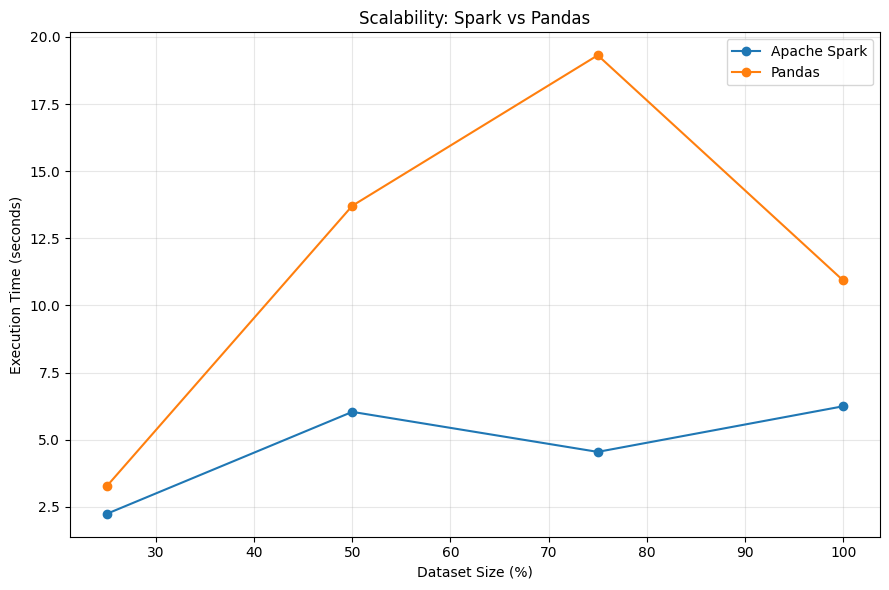

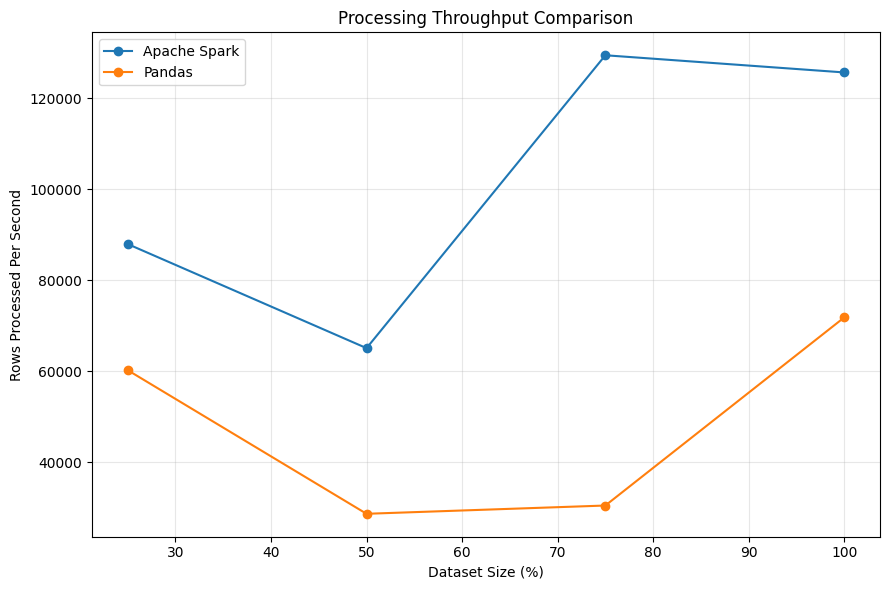


FINAL SCALABILITY BENCHMARK RESULTS
 dataset_percentage  rows_spark  execution_time_seconds_spark  execution_time_seconds_pandas  spark_rows_per_second  pandas_rows_per_second  spark_to_pandas_time_ratio
               25.0      196788                         2.238                          3.269              87919.041               60192.054                       0.685
               50.0      392520                         6.035                         13.711              65040.907               28627.186                       0.440
               75.0      588120                         4.544                         19.317             129422.287               30445.346                       0.235
              100.0      784473                         6.243                         10.929             125647.256               71780.873                       0.571

PHASE 7 BENCHMARKING COMPLETED
Results directory: /content/drive/MyDrive/Diabetes_BigData_Project/results/scalability


In [ ]:

# ================================================================
# PHASE 7 — BIG DATA SCALABILITY BENCHMARKING
# Spark vs Pandas | 25%, 50%, 75%, 100%
# ================================================================

import os
import gc
import time
import json
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import functions as F
from pyspark.storagelevel import StorageLevel

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

BENCH_DIR = os.path.join(
    PROJECT_DIR, "results", "scalability"
)

os.makedirs(BENCH_DIR, exist_ok=True)

assert "cleaned" in globals(), (
    "Cleaned Spark DataFrame not found. Recreate it first."
)

benchmark_columns = [
    "target_diabetes",
    "survey_year",
    "BMI",
    "general_health",
    "physical_unhealthy_days",
    "mental_unhealthy_days",
    "exercise",
    "alcohol_use",
    "smoking_status",
    "asthma",
    "kidney_disease",
    "stroke",
    "arthritis"
]

available_columns = cleaned.columns

missing_columns = [
    col for col in benchmark_columns
    if col not in available_columns
]

if missing_columns:
    raise ValueError(
        f"Missing benchmark columns: {missing_columns}"
    )

benchmark_df = cleaned.select(*benchmark_columns)

fractions = [0.25, 0.50, 0.75, 1.00]

process = psutil.Process(os.getpid())

# ------------------------------------------------
# 2. MEMORY MONITORING
# ------------------------------------------------

def python_memory_mb():
    return process.memory_info().rss / (1024 ** 2)


def spark_jvm_heap_mb():

    try:
        runtime = spark._jvm.java.lang.Runtime.getRuntime()

        used = (
            runtime.totalMemory() - runtime.freeMemory()
        )

        return used / (1024 ** 2)

    except Exception:
        return np.nan


# ------------------------------------------------
# 3. SPARK BENCHMARK
# ------------------------------------------------

spark_results = []
pandas_results = []

# Warm-up Spark before timing experiments
print("Warming up Spark...")

benchmark_df.groupBy(
    "target_diabetes"
).count().collect()

print("Spark warm-up completed.")

for fraction in fractions:

    print("\n" + "=" * 55)
    print(f"DATASET FRACTION: {fraction * 100:.0f}%")
    print("=" * 55)

    # ------------------------------------------------
    # Spark processing
    # ------------------------------------------------

    gc.collect()

    sample_df = benchmark_df.sample(
        withReplacement=False,
        fraction=fraction,
        seed=42
    ).persist(StorageLevel.MEMORY_AND_DISK)

    python_mem_before = python_memory_mb()
    jvm_mem_before = spark_jvm_heap_mb()

    start = time.perf_counter()

    # Materialize sample and run aggregations
    spark_count = sample_df.count()

    spark_summary = (
        sample_df
        .groupBy("survey_year", "target_diabetes")
        .agg(
            F.count("*").alias("respondent_count"),
            F.avg("BMI").alias("average_BMI"),
            F.avg("general_health").alias(
                "average_general_health"
            ),
            F.avg("exercise").alias(
                "exercise_percentage"
            )
        )
        .collect()
    )

    spark_time = time.perf_counter() - start

    python_mem_after = python_memory_mb()
    jvm_mem_after = spark_jvm_heap_mb()

    spark_results.append({
        "fraction": fraction,
        "dataset_percentage": fraction * 100,
        "rows": spark_count,
        "execution_time_seconds": spark_time,
        "python_memory_before_mb": python_mem_before,
        "python_memory_after_mb": python_mem_after,
        "python_memory_change_mb": (
            python_mem_after - python_mem_before
        ),
        "jvm_heap_before_mb": jvm_mem_before,
        "jvm_heap_after_mb": jvm_mem_after,
        "jvm_heap_change_mb": (
            jvm_mem_after - jvm_mem_before
            if np.isfinite(jvm_mem_before)
            and np.isfinite(jvm_mem_after)
            else np.nan
        )
    })

    print("Spark rows:", spark_count)
    print("Spark time:", round(spark_time, 3), "seconds")

    # ------------------------------------------------
    # Pandas processing
    # ------------------------------------------------

    gc.collect()

    pandas_mem_before = python_memory_mb()

    start = time.perf_counter()

    # Arrow is disabled because of the earlier JVM issue
    pandas_df = sample_df.toPandas()

    pandas_summary = (
        pandas_df
        .groupby(
            ["survey_year", "target_diabetes"],
            dropna=False
        )
        .agg(
            respondent_count=("target_diabetes", "size"),
            average_BMI=("BMI", "mean"),
            average_general_health=(
                "general_health", "mean"
            ),
            exercise_percentage=("exercise", "mean")
        )
        .reset_index()
    )

    pandas_time = time.perf_counter() - start

    pandas_mem_after = python_memory_mb()

    pandas_results.append({
        "fraction": fraction,
        "dataset_percentage": fraction * 100,
        "rows": len(pandas_df),
        "execution_time_seconds": pandas_time,
        "python_memory_before_mb": pandas_mem_before,
        "python_memory_after_mb": pandas_mem_after,
        "python_memory_change_mb": (
            pandas_mem_after - pandas_mem_before
        ),
        "dataframe_memory_mb": (
            pandas_df.memory_usage(deep=True).sum()
            / (1024 ** 2)
        )
    })

    print("Pandas rows:", len(pandas_df))
    print("Pandas time:", round(pandas_time, 3), "seconds")
    print(
        "Pandas DataFrame memory:",
        round(
            pandas_df.memory_usage(deep=True).sum()
            / (1024 ** 2), 2
        ),
        "MB"
    )

    # ------------------------------------------------
    # Validate output consistency
    # ------------------------------------------------

    spark_check = pd.DataFrame(
        [row.asDict() for row in spark_summary]
    )

    comparison = spark_check.merge(
        pandas_summary,
        on=["survey_year", "target_diabetes"],
        suffixes=("_spark", "_pandas")
    )

    assert (
        comparison["respondent_count_spark"]
        == comparison["respondent_count_pandas"]
    ).all(), "Spark and Pandas counts do not match."

    print("Aggregation consistency: PASSED")

    # Save each fraction immediately
    pd.DataFrame(spark_results).to_csv(
        os.path.join(BENCH_DIR, "spark_progress.csv"),
        index=False
    )

    pd.DataFrame(pandas_results).to_csv(
        os.path.join(BENCH_DIR, "pandas_progress.csv"),
        index=False
    )

    # Release memory
    del pandas_df, pandas_summary
    sample_df.unpersist()
    del sample_df, spark_summary, spark_check, comparison

    gc.collect()

# ------------------------------------------------
# 4. CONSOLIDATE RESULTS
# ------------------------------------------------

spark_benchmark = pd.DataFrame(spark_results)
pandas_benchmark = pd.DataFrame(pandas_results)

combined = spark_benchmark.merge(
    pandas_benchmark,
    on=["fraction", "dataset_percentage"],
    suffixes=("_spark", "_pandas")
)

combined["spark_to_pandas_time_ratio"] = (
    combined["execution_time_seconds_spark"]
    / combined["execution_time_seconds_pandas"]
)

combined["spark_rows_per_second"] = (
    combined["rows_spark"]
    / combined["execution_time_seconds_spark"]
)

combined["pandas_rows_per_second"] = (
    combined["rows_pandas"]
    / combined["execution_time_seconds_pandas"]
)

combined.to_csv(
    os.path.join(BENCH_DIR, "scalability_comparison.csv"),
    index=False
)

spark_benchmark.to_csv(
    os.path.join(BENCH_DIR, "spark_benchmark.csv"),
    index=False
)

pandas_benchmark.to_csv(
    os.path.join(BENCH_DIR, "pandas_benchmark.csv"),
    index=False
)

# ------------------------------------------------
# 5. EXECUTION TIME PLOT
# ------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    combined["dataset_percentage"],
    combined["execution_time_seconds_spark"],
    marker="o",
    label="Apache Spark"
)

plt.plot(
    combined["dataset_percentage"],
    combined["execution_time_seconds_pandas"],
    marker="o",
    label="Pandas"
)

plt.xlabel("Dataset Size (%)")
plt.ylabel("Execution Time (seconds)")
plt.title("Scalability: Spark vs Pandas")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(BENCH_DIR, "execution_time_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------
# 6. THROUGHPUT PLOT
# ------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    combined["dataset_percentage"],
    combined["spark_rows_per_second"],
    marker="o",
    label="Apache Spark"
)

plt.plot(
    combined["dataset_percentage"],
    combined["pandas_rows_per_second"],
    marker="o",
    label="Pandas"
)

plt.xlabel("Dataset Size (%)")
plt.ylabel("Rows Processed Per Second")
plt.title("Processing Throughput Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(BENCH_DIR, "throughput_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------
# 7. PRINT FINAL RESULTS
# ------------------------------------------------

print("\n" + "=" * 65)
print("FINAL SCALABILITY BENCHMARK RESULTS")
print("=" * 65)

print(
    combined[
        [
            "dataset_percentage",
            "rows_spark",
            "execution_time_seconds_spark",
            "execution_time_seconds_pandas",
            "spark_rows_per_second",
            "pandas_rows_per_second",
            "spark_to_pandas_time_ratio"
        ]
    ].round(3).to_string(index=False)
)

# ------------------------------------------------
# 8. EXPERIMENT METADATA
# ------------------------------------------------

metadata = {
    "dataset": "CDC BRFSS 2024-2025 harmonised data",
    "total_dataset_rows": int(benchmark_df.count()),
    "fractions_tested": fractions,
    "spark_version": spark.version,
    "spark_master": spark.sparkContext.master,
    "spark_default_parallelism": (
        spark.sparkContext.defaultParallelism
    ),
    "execution_environment": "Google Colab single machine",
    "comparison": "Spark vs Pandas",
    "benchmark_operation": (
        "Group-by aggregation by survey year and diabetes target"
    ),
    "note": (
        "Local Spark execution is not a multi-node distributed "
        "cluster benchmark. Memory readings are process/heap "
        "snapshots, not peak memory measurements."
    )
}

with open(
    os.path.join(BENCH_DIR, "benchmark_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\nPHASE 7 BENCHMARKING COMPLETED")
print("Results directory:", BENCH_DIR)


CONTROLLED SCALABILITY BENCHMARK

Warming up Spark...
Spark warm-up completed.

DATASET FRACTION: 25%
Aggregation consistency: PASSED
Rows: 196,788
Pandas conversion time: 1.483s
Run 1: Spark=0.3366s | Pandas=0.0234s
Run 2: Spark=0.5837s | Pandas=0.0376s
Run 3: Spark=0.6418s | Pandas=0.0325s
Run 4: Spark=0.3951s | Pandas=0.0379s
Run 5: Spark=0.3426s | Pandas=0.0254s

Median results:
Spark:  0.3951s
Pandas: 0.0325s
Result: Pandas faster

DATASET FRACTION: 50%
Aggregation consistency: PASSED
Rows: 392,520
Pandas conversion time: 3.353s
Run 1: Spark=0.6504s | Pandas=0.0536s
Run 2: Spark=0.4708s | Pandas=0.0573s
Run 3: Spark=0.3895s | Pandas=0.0536s
Run 4: Spark=0.4271s | Pandas=0.0999s
Run 5: Spark=0.4959s | Pandas=0.0655s

Median results:
Spark:  0.4708s
Pandas: 0.0573s
Result: Pandas faster

DATASET FRACTION: 75%
Aggregation consistency: PASSED
Rows: 588,120
Pandas conversion time: 5.324s
Run 1: Spark=0.3721s | Pandas=0.0545s
Run 2: Spark=0.2971s | Pandas=0.0510s
Run 3: Spark=0.3297s | 

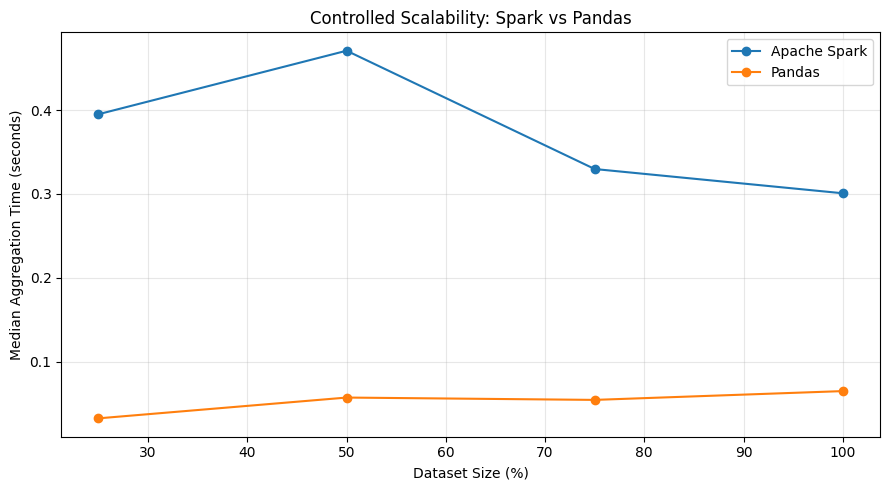

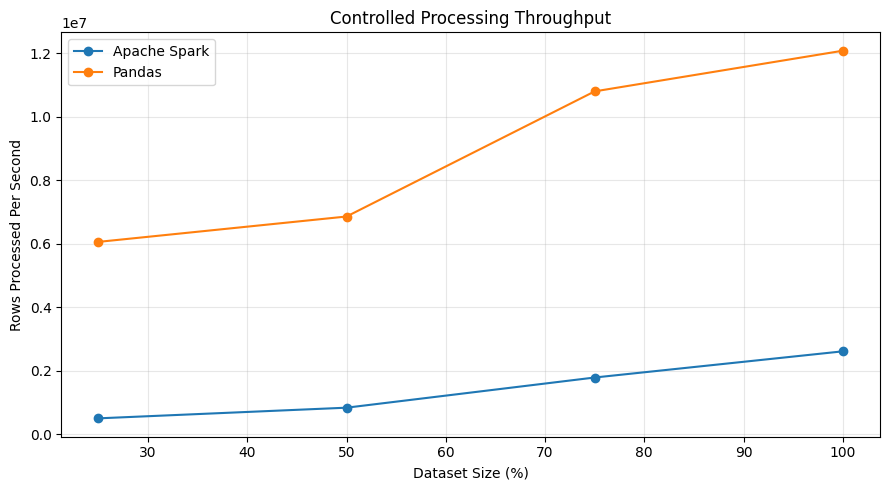


Saved: /content/drive/MyDrive/Diabetes_BigData_Project/results/scalability/controlled_scalability_benchmark.csv
PHASE 7.1 COMPLETED


In [ ]:

# ============================================================
# PHASE 7.1: CONTROLLED SPARK VS PANDAS BENCHMARK
# 5 repetitions | Median timing | Equivalent aggregations
# ============================================================

import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark import StorageLevel

# Output directory
SCALABILITY_DIR = (
    "/content/drive/MyDrive/Diabetes_BigData_Project/"
    "results/scalability"
)
os.makedirs(SCALABILITY_DIR, exist_ok=True)

# Configuration
FRACTIONS = [0.25, 0.50, 0.75, 1.00]
REPETITIONS = 5
SEED = 42

GROUP_COLS = ["survey_year", "target_diabetes"]
AGG_COLS = ["BMI", "general_health", "exercise"]

required_cols = GROUP_COLS + AGG_COLS
missing = [c for c in required_cols if c not in cleaned.columns]

if missing:
    raise ValueError(f"Missing columns in cleaned DataFrame: {missing}")

spark_results = []
pandas_results = []

print("=" * 65)
print("CONTROLLED SCALABILITY BENCHMARK")
print("=" * 65)

# Warm-up Spark
print("\nWarming up Spark...")
cleaned.select("target_diabetes").limit(1000).count()
print("Spark warm-up completed.")

for fraction in FRACTIONS:

    print(f"\n{'=' * 60}")
    print(f"DATASET FRACTION: {fraction * 100:.0f}%")
    print(f"{'=' * 60}")

    sample_df = (
        cleaned
        .sample(
            withReplacement=False,
            fraction=fraction,
            seed=SEED
        )
        .select(*required_cols)
        .persist(StorageLevel.MEMORY_AND_DISK)
    )

    try:
        row_count = sample_df.count()

        # Convert once, outside the aggregation timing.
        conversion_start = time.perf_counter()
        pdf = sample_df.toPandas()
        conversion_time = time.perf_counter() - conversion_start

        # ----------------------------------------------------
        # Equivalent Spark and Pandas aggregation
        # ----------------------------------------------------

        def run_spark_aggregation():
            return (
                sample_df
                .groupBy(*GROUP_COLS)
                .agg(
                    *[
                        __import__("pyspark").sql.functions.avg(c).alias(
                            f"avg_{c}"
                        )
                        for c in AGG_COLS
                    ],
                    __import__("pyspark").sql.functions.count("*").alias(
                        "record_count"
                    )
                )
                .orderBy(*GROUP_COLS)
                .toPandas()
            )

        def run_pandas_aggregation():
            result = (
                pdf.groupby(
                    GROUP_COLS,
                    dropna=False,
                    as_index=False
                )
                .agg(
                    avg_BMI=("BMI", "mean"),
                    avg_general_health=("general_health", "mean"),
                    avg_exercise=("exercise", "mean"),
                    record_count=("target_diabetes", "size")
                )
                .sort_values(GROUP_COLS)
                .reset_index(drop=True)
            )
            return result

        # Warm-up both aggregation operations
        spark_reference = run_spark_aggregation()
        pandas_reference = run_pandas_aggregation()

        # Verify consistency
        spark_reference = spark_reference.sort_values(
            GROUP_COLS
        ).reset_index(drop=True)

        pandas_reference = pandas_reference.sort_values(
            GROUP_COLS
        ).reset_index(drop=True)

        if len(spark_reference) != len(pandas_reference):
            raise AssertionError("Aggregation group counts differ.")

        for col in ["record_count"]:
            if not np.array_equal(
                spark_reference[col].to_numpy(),
                pandas_reference[col].to_numpy()
            ):
                raise AssertionError(f"Mismatch in {col}")

        for col in ["avg_BMI", "avg_general_health", "avg_exercise"]:
            if not np.allclose(
                spark_reference[col].to_numpy(dtype=float),
                pandas_reference[col].to_numpy(dtype=float),
                rtol=1e-5,
                atol=1e-5,
                equal_nan=True
            ):
                raise AssertionError(f"Mismatch in {col}")

        print("Aggregation consistency: PASSED")
        print(f"Rows: {row_count:,}")
        print(f"Pandas conversion time: {conversion_time:.3f}s")

        # ----------------------------------------------------
        # Repeated timings
        # ----------------------------------------------------

        spark_times = []
        pandas_times = []

        for repetition in range(REPETITIONS):

            start = time.perf_counter()
            run_spark_aggregation()
            spark_times.append(time.perf_counter() - start)

            start = time.perf_counter()
            run_pandas_aggregation()
            pandas_times.append(time.perf_counter() - start)

            print(
                f"Run {repetition + 1}: "
                f"Spark={spark_times[-1]:.4f}s | "
                f"Pandas={pandas_times[-1]:.4f}s"
            )

        spark_median = float(np.median(spark_times))
        pandas_median = float(np.median(pandas_times))

        spark_results.append({
            "dataset_percentage": fraction * 100,
            "rows": row_count,
            "spark_median_seconds": spark_median,
            "spark_std_seconds": float(np.std(spark_times)),
            "pandas_median_seconds": pandas_median,
            "pandas_std_seconds": float(np.std(pandas_times)),
            "pandas_conversion_seconds": conversion_time,
            "spark_rows_per_second": row_count / spark_median,
            "pandas_rows_per_second": row_count / pandas_median,
            "spark_to_pandas_time_ratio": spark_median / pandas_median
        })

        print("\nMedian results:")
        print(f"Spark:  {spark_median:.4f}s")
        print(f"Pandas: {pandas_median:.4f}s")

        if spark_median < pandas_median:
            print("Result: Spark faster")
        else:
            print("Result: Pandas faster")

        sample_df.unpersist()

    except Exception:
        sample_df.unpersist()
        raise

# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(spark_results)

csv_path = os.path.join(
    SCALABILITY_DIR,
    "controlled_scalability_benchmark.csv"
)
benchmark_df.to_csv(csv_path, index=False)

print("\n" + "=" * 65)
print("FINAL CONTROLLED BENCHMARK")
print("=" * 65)
print(benchmark_df.to_string(index=False))

# Execution time graph
plt.figure(figsize=(9, 5))
plt.plot(
    benchmark_df["dataset_percentage"],
    benchmark_df["spark_median_seconds"],
    marker="o",
    label="Apache Spark"
)
plt.plot(
    benchmark_df["dataset_percentage"],
    benchmark_df["pandas_median_seconds"],
    marker="o",
    label="Pandas"
)
plt.xlabel("Dataset Size (%)")
plt.ylabel("Median Aggregation Time (seconds)")
plt.title("Controlled Scalability: Spark vs Pandas")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SCALABILITY_DIR, "controlled_execution_time.png"),
    dpi=200
)
plt.show()

# Throughput graph
plt.figure(figsize=(9, 5))
plt.plot(
    benchmark_df["dataset_percentage"],
    benchmark_df["spark_rows_per_second"],
    marker="o",
    label="Apache Spark"
)
plt.plot(
    benchmark_df["dataset_percentage"],
    benchmark_df["pandas_rows_per_second"],
    marker="o",
    label="Pandas"
)
plt.xlabel("Dataset Size (%)")
plt.ylabel("Rows Processed Per Second")
plt.title("Controlled Processing Throughput")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SCALABILITY_DIR, "controlled_throughput.png"),
    dpi=200
)
plt.show()

print("\nSaved:", csv_path)
print("PHASE 7.1 COMPLETED")


In [ ]:

# ============================================================
# PHASE 8.1: FINAL HYBRID MODEL ARTIFACT AUDIT
# ============================================================

import os
import json
import joblib
import torch
import pandas as pd
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

STRICT_DIR = os.path.join(
    PROJECT_DIR, "results", "strict_oof"
)

EXPLAIN_DIR = os.path.join(
    PROJECT_DIR, "results", "explainability"
)

FAIRNESS_DIR = os.path.join(
    PROJECT_DIR, "results", "fairness"
)

SCALABILITY_DIR = os.path.join(
    PROJECT_DIR, "results", "scalability"
)

print("=" * 70)
print("PHASE 8.1 — FINAL MODEL ARTIFACT AUDIT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Check required files
# ------------------------------------------------------------

required_files = {
    "Hybrid model bundle": os.path.join(
        STRICT_DIR, "strict_oof_hybrid_models.joblib"
    ),
    "Final DNN weights": os.path.join(
        STRICT_DIR, "strict_oof_final_dnn.pt"
    ),
    "Hybrid test results": os.path.join(
        STRICT_DIR, "strict_oof_test_results.csv"
    ),
    "SHAP summary": os.path.join(
        EXPLAIN_DIR, "shap_summary_xgboost.png"
    ),
    "Fairness by age": os.path.join(
        FAIRNESS_DIR, "fairness_by_age.csv"
    ),
    "Fairness by sex": os.path.join(
        FAIRNESS_DIR, "fairness_by_sex.csv"
    ),
}

for name, path in required_files.items():
    status = "FOUND" if os.path.exists(path) else "MISSING"
    print(f"{name:25s}: {status}")

# ------------------------------------------------------------
# 2. Load hybrid model bundle
# ------------------------------------------------------------

bundle_path = required_files["Hybrid model bundle"]

if not os.path.exists(bundle_path):
    raise FileNotFoundError(bundle_path)

bundle = joblib.load(bundle_path)

print("\nMODEL BUNDLE CONTENTS")
print("-" * 50)

if isinstance(bundle, dict):
    for key, value in bundle.items():
        print(f"{key:25s}: {type(value).__name__}")
else:
    raise TypeError(
        "Expected a dictionary-like model bundle. "
        "Inspect the saved artifact before proceeding."
    )

# ------------------------------------------------------------
# 3. Inspect preprocessing and model components
# ------------------------------------------------------------

preprocessor = bundle.get("preprocessor")
xgb_model = bundle.get("final_xgb")
meta_model = bundle.get("meta_model")

print("\nMODEL COMPONENT CHECK")
print("-" * 50)

components = {
    "Preprocessor": preprocessor,
    "XGBoost": xgb_model,
    "Meta learner": meta_model
}

for name, component in components.items():
    print(
        f"{name:20s}: "
        f"{'AVAILABLE' if component is not None else 'MISSING'}"
    )

if preprocessor is not None:
    try:
        print(
            "Preprocessor output features:",
            len(preprocessor.get_feature_names_out())
        )
    except Exception as e:
        print("Could not inspect feature names:", str(e))

if xgb_model is not None:
    print("XGBoost estimators:", getattr(xgb_model, "n_estimators", "N/A"))
    print("XGBoost features:", getattr(xgb_model, "n_features_in_", "N/A"))

if meta_model is not None:
    print("Meta learner classes:", getattr(meta_model, "classes_", "N/A"))

# ------------------------------------------------------------
# 4. Inspect DNN state dictionary
# ------------------------------------------------------------

dnn_path = required_files["Final DNN weights"]

if os.path.exists(dnn_path):
    try:
        try:
            dnn_state = torch.load(
                dnn_path,
                map_location="cpu",
                weights_only=True
            )
        except TypeError:
            dnn_state = torch.load(
                dnn_path,
                map_location="cpu"
            )

        print("\nDNN WEIGHT AUDIT")
        print("-" * 50)

        print("Object type:", type(dnn_state).__name__)

        if isinstance(dnn_state, dict):
            print("Number of stored entries:", len(dnn_state))

            for key, value in list(dnn_state.items())[:12]:
                if hasattr(value, "shape"):
                    print(f"{key:35s}: {tuple(value.shape)}")
                else:
                    print(f"{key:35s}: {type(value).__name__}")

        else:
            print("DNN artifact is not a state dictionary.")

    except Exception as e:
        print("DNN loading error:", repr(e))

# ------------------------------------------------------------
# 5. Inspect test evaluation results
# ------------------------------------------------------------

results_path = required_files["Hybrid test results"]

if os.path.exists(results_path):
    results_df = pd.read_csv(results_path)

    print("\nHYBRID TEST RESULTS")
    print("-" * 50)
    print(results_df.to_string(index=False))

# ------------------------------------------------------------
# 6. Inspect saved benchmark and fairness outputs
# ------------------------------------------------------------

for filename in [
    "controlled_scalability_benchmark.csv",
    "scalability_comparison.csv"
]:
    path = os.path.join(SCALABILITY_DIR, filename)

    if os.path.exists(path):
        print(f"\n{filename}")
        print(pd.read_csv(path).to_string(index=False))

# ------------------------------------------------------------
# 7. Save audit report
# ------------------------------------------------------------

audit = {
    "project": "Big Data-Driven Explainable Hybrid Deep Learning Framework",
    "hybrid_bundle_found": os.path.exists(bundle_path),
    "dnn_weights_found": os.path.exists(dnn_path),
    "test_results_found": os.path.exists(results_path),
    "bundle_keys": list(bundle.keys()),
    "preprocessor_available": preprocessor is not None,
    "xgboost_available": xgb_model is not None,
    "meta_model_available": meta_model is not None,
}

audit_path = os.path.join(
    STRICT_DIR,
    "phase8_artifact_audit.json"
)

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4, default=str)

print("\n" + "=" * 70)
print("ARTIFACT AUDIT COMPLETED")
print("Audit saved to:", audit_path)
print("=" * 70)


PHASE 8.1 — FINAL MODEL ARTIFACT AUDIT
Hybrid model bundle      : FOUND
Final DNN weights        : FOUND
Hybrid test results      : FOUND
SHAP summary             : FOUND
Fairness by age          : FOUND
Fairness by sex          : FOUND

MODEL BUNDLE CONTENTS
--------------------------------------------------
preprocessor             : ColumnTransformer
xgb_model                : XGBClassifier
meta_model               : LogisticRegression
threshold                : float64
results                  : dict

MODEL COMPONENT CHECK
--------------------------------------------------
Preprocessor        : AVAILABLE
XGBoost             : MISSING
Meta learner        : AVAILABLE
Preprocessor output features: 72
Meta learner classes: [0 1]

DNN WEIGHT AUDIT
--------------------------------------------------
Object type: OrderedDict
Number of stored entries: 23
network.0.weight                   : (256, 72)
network.0.bias                     : (256,)
network.1.weight                   : (256,)
net

In [ ]:

# ============================================================
# PHASE 8.2: END-TO-END HYBRID INFERENCE VERIFICATION
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Paths and feature schema
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

STRICT_DIR = os.path.join(
    PROJECT_DIR, "results", "strict_oof"
)

bundle_path = os.path.join(
    STRICT_DIR, "strict_oof_hybrid_models.joblib"
)

dnn_path = os.path.join(
    STRICT_DIR, "strict_oof_final_dnn.pt"
)

# Original input features in the training order
feature_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup",
    "BMI", "physical_unhealthy_days", "mental_unhealthy_days",
    "exercise", "alcohol_use", "asthma", "kidney_disease",
    "heart_attack", "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

# ------------------------------------------------------------
# 2. Load model bundle
# ------------------------------------------------------------

bundle = joblib.load(bundle_path)

preprocessor = bundle["preprocessor"]
xgb_model = bundle["xgb_model"]
meta_model = bundle["meta_model"]
threshold = float(bundle["threshold"])

print("MODEL COMPONENTS LOADED")
print("Preprocessor:", type(preprocessor).__name__)
print("XGBoost:", type(xgb_model).__name__)
print("Meta learner:", type(meta_model).__name__)
print("Decision threshold:", threshold)

# ------------------------------------------------------------
# 3. Reconstruct DNN architecture
# ------------------------------------------------------------

class DiabetesDNN(nn.Module):

    def __init__(self, input_dim=72):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


device = torch.device("cpu")

dnn_model = DiabetesDNN(input_dim=72)

try:
    dnn_state = torch.load(
        dnn_path,
        map_location=device,
        weights_only=True
    )
except TypeError:
    dnn_state = torch.load(
        dnn_path,
        map_location=device
    )

dnn_model.load_state_dict(dnn_state)
dnn_model.to(device)
dnn_model.eval()

print("\nDNN architecture reconstructed successfully.")

# ------------------------------------------------------------
# 4. Prepare held-out test data
# ------------------------------------------------------------

if "test_df" not in globals():
    raise RuntimeError(
        "test_df is not available. Recreate the original test split first."
    )

test_pdf = test_df.select(
    *feature_cols, "target_diabetes"
).toPandas()

X_test = test_pdf[feature_cols]
y_test = test_pdf["target_diabetes"].astype(int).to_numpy()

print("\nTest dataset:", X_test.shape)
print("Positive cases:", int(y_test.sum()))

# ------------------------------------------------------------
# 5. Apply saved preprocessing
# ------------------------------------------------------------

X_test_transformed = preprocessor.transform(X_test)

X_test_transformed = np.asarray(
    X_test_transformed,
    dtype=np.float32
)

print("Transformed test shape:", X_test_transformed.shape)

if X_test_transformed.shape[1] != 72:
    raise ValueError("Unexpected transformed feature dimension.")

# ------------------------------------------------------------
# 6. Generate XGBoost probabilities
# ------------------------------------------------------------

xgb_prob = xgb_model.predict_proba(
    X_test_transformed
)[:, 1]

# ------------------------------------------------------------
# 7. Generate DNN probabilities in batches
# ------------------------------------------------------------

dnn_prob_batches = []

BATCH_SIZE = 4096

with torch.no_grad():

    for start in range(0, len(X_test_transformed), BATCH_SIZE):

        batch = torch.tensor(
            X_test_transformed[start:start + BATCH_SIZE],
            dtype=torch.float32,
            device=device
        )

        logits = dnn_model(batch).squeeze(1)

        probabilities = torch.sigmoid(logits)

        dnn_prob_batches.append(
            probabilities.cpu().numpy()
        )

dnn_prob = np.concatenate(dnn_prob_batches)

# ------------------------------------------------------------
# 8. Hybrid meta-learner prediction
# ------------------------------------------------------------

meta_features = np.column_stack([
    xgb_prob,
    dnn_prob
])

hybrid_prob = meta_model.predict_proba(
    meta_features
)[:, 1]

hybrid_pred = (
    hybrid_prob >= threshold
).astype(int)

# ------------------------------------------------------------
# 9. Calculate final metrics
# ------------------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    hybrid_pred,
    labels=[0, 1]
).ravel()

results = {
    "ROC_AUC": roc_auc_score(y_test, hybrid_prob),
    "PR_AUC": average_precision_score(y_test, hybrid_prob),
    "Accuracy": accuracy_score(y_test, hybrid_pred),
    "Precision": precision_score(
        y_test, hybrid_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, hybrid_pred, zero_division=0
    ),
    "Specificity": tn / (tn + fp),
    "F1": f1_score(
        y_test, hybrid_pred, zero_division=0
    ),
    "Threshold": threshold,
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
}

print("\n" + "=" * 65)
print("END-TO-END HYBRID TEST RESULTS")
print("=" * 65)

for metric, value in results.items():
    print(f"{metric:20s}: {value}")

# ------------------------------------------------------------
# 10. Compare against previously recorded results
# ------------------------------------------------------------

expected = {
    "ROC_AUC": 0.809606,
    "PR_AUC": 0.425311,
    "Accuracy": 0.776440,
    "Precision": 0.360016,
    "Recall": 0.631042,
    "Specificity": 0.802091,
    "F1": 0.458470,
    "TP": 11136,
    "FP": 19796,
    "FN": 6511,
    "TN": 80230
}

print("\n" + "=" * 65)
print("COMPARISON WITH RECORDED RESULTS")
print("=" * 65)

for metric, expected_value in expected.items():

    actual_value = results[metric]

    difference = abs(actual_value - expected_value)

    print(
        f"{metric:15s} | "
        f"Recorded: {expected_value:.6f} | "
        f"Reproduced: {actual_value:.6f} | "
        f"Difference: {difference:.6f}"
    )

# ------------------------------------------------------------
# 11. Save verification report
# ------------------------------------------------------------

report = {
    "verification": "end_to_end_hybrid_inference",
    "test_rows": len(y_test),
    "transformed_features": int(X_test_transformed.shape[1]),
    "model_components": [
        "ColumnTransformer",
        "XGBoost",
        "PyTorch DNN",
        "Logistic Regression meta-learner"
    ],
    "results": {
        key: float(value)
        for key, value in results.items()
    }
}

report_path = os.path.join(
    STRICT_DIR,
    "phase8_inference_verification.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nVerification report saved:", report_path)
print("\nPHASE 8.2 COMPLETED")


MODEL COMPONENTS LOADED
Preprocessor: ColumnTransformer
XGBoost: XGBClassifier
Meta learner: LogisticRegression
Decision threshold: 0.22999999999999995

DNN architecture reconstructed successfully.

Test dataset: (117673, 24)
Positive cases: 17647
Transformed test shape: (117673, 72)

END-TO-END HYBRID TEST RESULTS
ROC_AUC             : 0.8096057256654041
PR_AUC              : 0.42531140224114716
Accuracy            : 0.776439795025197
Precision           : 0.36001551791025477
Recall              : 0.6310421034736783
Specificity         : 0.8020914562213824
F1                  : 0.45846970913357626
Threshold           : 0.22999999999999995
TP                  : 11136
FP                  : 19796
FN                  : 6511
TN                  : 80230

COMPARISON WITH RECORDED RESULTS
ROC_AUC         | Recorded: 0.809606 | Reproduced: 0.809606 | Difference: 0.000000
PR_AUC          | Recorded: 0.425311 | Reproduced: 0.425311 | Difference: 0.000000
Accuracy        | Recorded: 0.776440 | Re

Generating validation probabilities...
Generating test probabilities...

VALIDATION CALIBRATION
Brier_Score         : 0.105483
Log_Loss            : 0.339539
ECE_10_bins         : 0.004587

TEST CALIBRATION
Brier_Score         : 0.105359
Log_Loss            : 0.339294
ECE_10_bins         : 0.006636


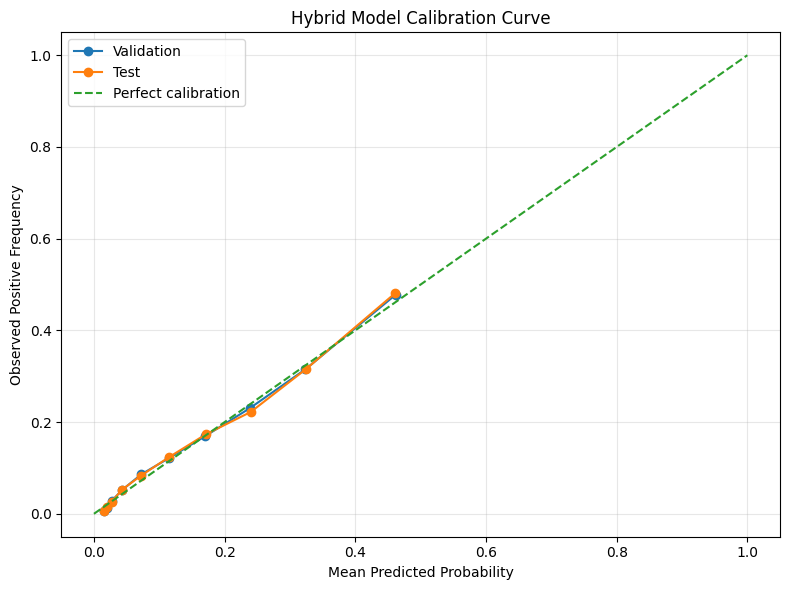


PHASE 8.3 CALIBRATION EVALUATION COMPLETED
Results: /content/drive/MyDrive/Diabetes_BigData_Project/results/calibration


In [ ]:

# ============================================================
# PHASE 8.3: HYBRID MODEL PROBABILITY CALIBRATION
# Validation and test evaluation — no test-set fitting
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.metrics import brier_score_loss, log_loss
from sklearn.calibration import calibration_curve

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
STRICT_DIR = os.path.join(PROJECT_DIR, "results", "strict_oof")
CAL_DIR = os.path.join(PROJECT_DIR, "results", "calibration")
os.makedirs(CAL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load saved components
# ------------------------------------------------------------

bundle = joblib.load(
    os.path.join(STRICT_DIR, "strict_oof_hybrid_models.joblib")
)

preprocessor = bundle["preprocessor"]
xgb_model = bundle["xgb_model"]
meta_model = bundle["meta_model"]

# ------------------------------------------------------------
# 2. Reconstruct DNN
# ------------------------------------------------------------

class DiabetesDNN(nn.Module):
    def __init__(self, input_dim=72):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


dnn_model = DiabetesDNN(72)

try:
    state = torch.load(
        os.path.join(STRICT_DIR, "strict_oof_final_dnn.pt"),
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    state = torch.load(
        os.path.join(STRICT_DIR, "strict_oof_final_dnn.pt"),
        map_location="cpu"
    )

dnn_model.load_state_dict(state)
dnn_model.eval()

# ------------------------------------------------------------
# 3. Feature schema
# ------------------------------------------------------------

feature_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup",
    "BMI", "physical_unhealthy_days", "mental_unhealthy_days",
    "exercise", "alcohol_use", "asthma", "kidney_disease",
    "heart_attack", "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

# ------------------------------------------------------------
# 4. Generate hybrid probabilities
# ------------------------------------------------------------

def generate_hybrid_probabilities(spark_df):

    pdf = spark_df.select(
        *feature_cols, "target_diabetes"
    ).toPandas()

    X = pdf[feature_cols]
    y = pdf["target_diabetes"].astype(int).to_numpy()

    transformed = np.asarray(
        preprocessor.transform(X),
        dtype=np.float32
    )

    xgb_prob = xgb_model.predict_proba(transformed)[:, 1]

    dnn_batches = []

    with torch.no_grad():
        for start in range(0, len(transformed), 4096):
            batch = torch.tensor(
                transformed[start:start + 4096],
                dtype=torch.float32
            )
            logits = dnn_model(batch).squeeze(1)
            probs = torch.sigmoid(logits).numpy()
            dnn_batches.append(probs)

    dnn_prob = np.concatenate(dnn_batches)

    meta_features = np.column_stack([xgb_prob, dnn_prob])
    hybrid_prob = meta_model.predict_proba(meta_features)[:, 1]

    return y, hybrid_prob


print("Generating validation probabilities...")
y_val_cal, p_val = generate_hybrid_probabilities(val_df)

print("Generating test probabilities...")
y_test_cal, p_test = generate_hybrid_probabilities(test_df)

# ------------------------------------------------------------
# 5. Calibration metrics
# ------------------------------------------------------------

def expected_calibration_error(y, probabilities, bins=10):

    bin_edges = np.linspace(0, 1, bins + 1)
    ece = 0.0

    for i in range(bins):
        if i == bins - 1:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities <= bin_edges[i + 1])
            )
        else:
            mask = (
                (probabilities >= bin_edges[i]) &
                (probabilities < bin_edges[i + 1])
            )

        if mask.sum() == 0:
            continue

        average_confidence = probabilities[mask].mean()
        observed_frequency = y[mask].mean()

        ece += (
            mask.mean() *
            abs(average_confidence - observed_frequency)
        )

    return float(ece)


def calibration_metrics(y, probabilities):

    probabilities = np.clip(
        probabilities, 1e-7, 1 - 1e-7
    )

    return {
        "Brier_Score": float(
            brier_score_loss(y, probabilities)
        ),
        "Log_Loss": float(
            log_loss(y, probabilities)
        ),
        "ECE_10_bins": expected_calibration_error(
            y, probabilities, bins=10
        )
    }


val_metrics = calibration_metrics(y_val_cal, p_val)
test_metrics = calibration_metrics(y_test_cal, p_test)

print("\nVALIDATION CALIBRATION")
for key, value in val_metrics.items():
    print(f"{key:20s}: {value:.6f}")

print("\nTEST CALIBRATION")
for key, value in test_metrics.items():
    print(f"{key:20s}: {value:.6f}")

# ------------------------------------------------------------
# 6. Reliability diagrams
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

for y, probabilities, label in [
    (y_val_cal, p_val, "Validation"),
    (y_test_cal, p_test, "Test")
]:
    observed, predicted = calibration_curve(
        y,
        probabilities,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        predicted,
        observed,
        marker="o",
        label=label
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Frequency")
plt.title("Hybrid Model Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(CAL_DIR, "hybrid_calibration_curve.png"),
    dpi=200
)
plt.show()

# ------------------------------------------------------------
# 7. Save calibration results
# ------------------------------------------------------------

calibration_results = pd.DataFrame([
    {"Dataset": "Validation", **val_metrics},
    {"Dataset": "Test", **test_metrics}
])

calibration_results.to_csv(
    os.path.join(CAL_DIR, "calibration_metrics.csv"),
    index=False
)

with open(
    os.path.join(CAL_DIR, "calibration_metrics.json"),
    "w"
) as f:
    json.dump(
        {
            "validation": val_metrics,
            "test": test_metrics,
            "method": "Uncalibrated hybrid probability evaluation",
            "bins": 10
        },
        f,
        indent=4
    )

print("\n" + "=" * 65)
print("PHASE 8.3 CALIBRATION EVALUATION COMPLETED")
print("Results:", CAL_DIR)
print("=" * 65)


In [ ]:

# ============================================================
# PHASE 8.4: HYBRID ROBUSTNESS + FAIRNESS EVALUATION
# Year | Age | Sex | Age x Sex
# ============================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
STRICT_DIR = os.path.join(PROJECT_DIR, "results", "strict_oof")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "results", "hybrid_robustness")

os.makedirs(OUTPUT_DIR, exist_ok=True)

THRESHOLD = 0.23
BATCH_SIZE = 4096

# ------------------------------------------------------------
# 1. Load final hybrid components
# ------------------------------------------------------------

bundle = joblib.load(
    os.path.join(STRICT_DIR, "strict_oof_hybrid_models.joblib")
)

preprocessor = bundle["preprocessor"]
xgb_model = bundle["xgb_model"]
meta_model = bundle["meta_model"]

# ------------------------------------------------------------
# 2. Reconstruct DNN
# ------------------------------------------------------------

class DiabetesDNN(nn.Module):

    def __init__(self, input_dim=72):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.30),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)


dnn_model = DiabetesDNN(72)

try:
    dnn_state = torch.load(
        os.path.join(STRICT_DIR, "strict_oof_final_dnn.pt"),
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    dnn_state = torch.load(
        os.path.join(STRICT_DIR, "strict_oof_final_dnn.pt"),
        map_location="cpu"
    )

dnn_model.load_state_dict(dnn_state)
dnn_model.eval()

# ------------------------------------------------------------
# 3. Feature schema
# ------------------------------------------------------------

feature_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup",
    "BMI", "physical_unhealthy_days", "mental_unhealthy_days",
    "exercise", "alcohol_use", "asthma", "kidney_disease",
    "heart_attack", "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

# ------------------------------------------------------------
# 4. Prepare test dataset with subgroup columns
# ------------------------------------------------------------

required_columns = (
    feature_cols +
    ["target_diabetes", "survey_year", "age_group", "sex"]
)

test_pdf = test_df.select(
    *list(dict.fromkeys(required_columns))
).toPandas()

X_test = test_pdf[feature_cols]
y = test_pdf["target_diabetes"].astype(int).to_numpy()

# ------------------------------------------------------------
# 5. Generate hybrid probabilities
# ------------------------------------------------------------

print("Transforming test data...")

X_transformed = np.asarray(
    preprocessor.transform(X_test),
    dtype=np.float32
)

print("Generating XGBoost probabilities...")

xgb_prob = xgb_model.predict_proba(
    X_transformed
)[:, 1]

print("Generating DNN probabilities...")

dnn_batches = []

with torch.no_grad():

    for start in range(0, len(X_transformed), BATCH_SIZE):

        batch = torch.tensor(
            X_transformed[start:start + BATCH_SIZE],
            dtype=torch.float32
        )

        logits = dnn_model(batch).squeeze(1)

        dnn_batches.append(
            torch.sigmoid(logits).numpy()
        )

dnn_prob = np.concatenate(dnn_batches)

meta_features = np.column_stack([
    xgb_prob,
    dnn_prob
])

hybrid_prob = meta_model.predict_proba(
    meta_features
)[:, 1]

hybrid_pred = (
    hybrid_prob >= THRESHOLD
).astype(int)

test_pdf["actual"] = y
test_pdf["probability"] = hybrid_prob
test_pdf["prediction"] = hybrid_pred

print("Hybrid predictions generated:", len(hybrid_prob))

# ------------------------------------------------------------
# 6. Reusable group evaluation
# ------------------------------------------------------------

def evaluate_group(group_df):

    actual = group_df["actual"].to_numpy()
    predicted = group_df["prediction"].to_numpy()
    probability = group_df["probability"].to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        actual,
        predicted,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0 else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0 else np.nan
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0 else np.nan
    )

    return {
        "n": len(group_df),
        "positive_cases": int(actual.sum()),
        "prevalence": actual.mean(),
        "accuracy": accuracy_score(actual, predicted),
        "precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "recall": recall,
        "specificity": specificity,
        "FPR": fpr,
        "FNR": fnr,
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC_AUC": (
            roc_auc_score(actual, probability)
            if len(np.unique(actual)) == 2 else np.nan
        ),
        "PR_AUC": (
            average_precision_score(actual, probability)
            if len(np.unique(actual)) == 2 else np.nan
        ),
        "positive_prediction_rate": predicted.mean()
    }


def evaluate_subgroups(df, group_columns, min_n=500, min_positive=30):

    records = []

    for group_values, group_df in df.groupby(
        group_columns,
        dropna=False
    ):

        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        positive_count = int(group_df["actual"].sum())

        if (
            len(group_df) < min_n or
            positive_count < min_positive
        ):
            continue

        row = {
            column: value
            for column, value in zip(
                group_columns, group_values
            )
        }

        row.update(evaluate_group(group_df))
        records.append(row)

    return pd.DataFrame(records)


# ------------------------------------------------------------
# 7. Evaluate by survey year
# ------------------------------------------------------------

year_results = evaluate_subgroups(
    test_pdf,
    ["survey_year"],
    min_n=100,
    min_positive=30
)

year_results.to_csv(
    os.path.join(OUTPUT_DIR, "hybrid_by_year.csv"),
    index=False
)

print("\nYEAR-WISE HYBRID PERFORMANCE")
print(year_results.to_string(index=False))

# ------------------------------------------------------------
# 8. Evaluate by age
# ------------------------------------------------------------

age_results = evaluate_subgroups(
    test_pdf,
    ["age_group"]
)

age_results.to_csv(
    os.path.join(OUTPUT_DIR, "hybrid_by_age.csv"),
    index=False
)

print("\nAGE-WISE HYBRID PERFORMANCE")
print(age_results.to_string(index=False))

# ------------------------------------------------------------
# 9. Evaluate by sex
# ------------------------------------------------------------

sex_results = evaluate_subgroups(
    test_pdf,
    ["sex"]
)

sex_results.to_csv(
    os.path.join(OUTPUT_DIR, "hybrid_by_sex.csv"),
    index=False
)

print("\nSEX-WISE HYBRID PERFORMANCE")
print(sex_results.to_string(index=False))

# ------------------------------------------------------------
# 10. Intersectional evaluation
# ------------------------------------------------------------

intersection_results = evaluate_subgroups(
    test_pdf,
    ["age_group", "sex"],
    min_n=500,
    min_positive=30
)

intersection_results.to_csv(
    os.path.join(OUTPUT_DIR, "hybrid_intersectional.csv"),
    index=False
)

print("\nINTERSECTIONAL HYBRID PERFORMANCE")
print(intersection_results.to_string(index=False))

# ------------------------------------------------------------
# 11. Calculate subgroup gaps
# ------------------------------------------------------------

def calculate_gaps(df, group_name):

    if df.empty:
        return {
            "group": group_name,
            "note": "No eligible groups"
        }

    result = {"group": group_name}

    for metric in [
        "recall",
        "specificity",
        "FPR",
        "FNR",
        "positive_prediction_rate"
    ]:

        values = df[metric].dropna()

        result[f"{metric}_gap"] = (
            float(values.max() - values.min())
            if len(values) >= 2 else np.nan
        )

    return result


gap_results = pd.DataFrame([
    calculate_gaps(age_results, "age"),
    calculate_gaps(sex_results, "sex")
])

gap_results.to_csv(
    os.path.join(OUTPUT_DIR, "hybrid_fairness_gaps.csv"),
    index=False
)

print("\nHYBRID FAIRNESS GAPS")
print(gap_results.to_string(index=False))

# ------------------------------------------------------------
# 12. Save evaluation metadata
# ------------------------------------------------------------

metadata = {
    "model": "Strict OOF Hybrid",
    "threshold": THRESHOLD,
    "test_rows": len(test_pdf),
    "survey_years": [
        str(x) for x in sorted(
            test_pdf["survey_year"].dropna().unique()
        )
    ],
    "minimum_subgroup_size": 500,
    "minimum_positive_cases": 30,
    "subgroup_metrics": [
        "accuracy", "precision", "recall",
        "specificity", "FPR", "FNR",
        "F1", "ROC_AUC", "PR_AUC"
    ],
    "interpretation_note": (
        "Subgroup differences are descriptive diagnostics, "
        "not proof of discriminatory bias."
    )
}

with open(
    os.path.join(OUTPUT_DIR, "evaluation_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\n" + "=" * 65)
print("PHASE 8.4 COMPLETED")
print("Results saved in:", OUTPUT_DIR)
print("=" * 65)


Transforming test data...
Generating XGBoost probabilities...
Generating DNN probabilities...
Hybrid predictions generated: 117673

YEAR-WISE HYBRID PERFORMANCE
 survey_year     n  positive_cases  prevalence  accuracy  precision   recall  specificity      FPR      FNR       F1  ROC_AUC   PR_AUC  positive_prediction_rate
        2024 66291            9872    0.148919  0.778839   0.361773 0.634826     0.804038 0.195962 0.365174 0.460894 0.812936 0.427720                  0.261318
        2025 51382            7775    0.151318  0.773345   0.357778 0.626238     0.799573 0.200427 0.373762 0.455387 0.805288 0.422295                  0.264859

AGE-WISE HYBRID PERFORMANCE
 age_group     n  positive_cases  prevalence  accuracy  precision   recall  specificity      FPR      FNR       F1  ROC_AUC   PR_AUC  positive_prediction_rate
       1.0  7952             102    0.012827  0.986670   0.300000 0.029412     0.999108 0.000892 0.970588 0.053571 0.693027 0.080729                  0.001258
       2.

FINAL MODEL COMPARISON
              Model  ROC_AUC  PR_AUC  Accuracy  Precision  Recall  Specificity     F1
Logistic Regression   0.8050  0.4111    0.7853     0.3676  0.5990       0.8182 0.4556
      Random Forest   0.7889  0.3945    0.7605     0.3376  0.6208       0.7851 0.4374
          Spark GBT   0.7910  0.3972    0.7732     0.3484  0.5883       0.8059 0.4376
            XGBoost   0.8091  0.4238    0.7846     0.3684  0.6105       0.8154 0.4595
                DNN   0.8096  0.4258    0.7777     0.3611  0.6272       0.8042 0.4583
    Hybrid Stacking   0.8096  0.4253    0.7764     0.3600  0.6310       0.8021 0.4585

METRIC LEADERS
ROC_AUC        : DNN (0.8096)
PR_AUC         : DNN (0.4258)
Accuracy       : Logistic Regression (0.7853)
Precision      : XGBoost (0.3684)
Recall         : Hybrid Stacking (0.6310)
Specificity    : Logistic Regression (0.8182)
F1             : XGBoost (0.4595)


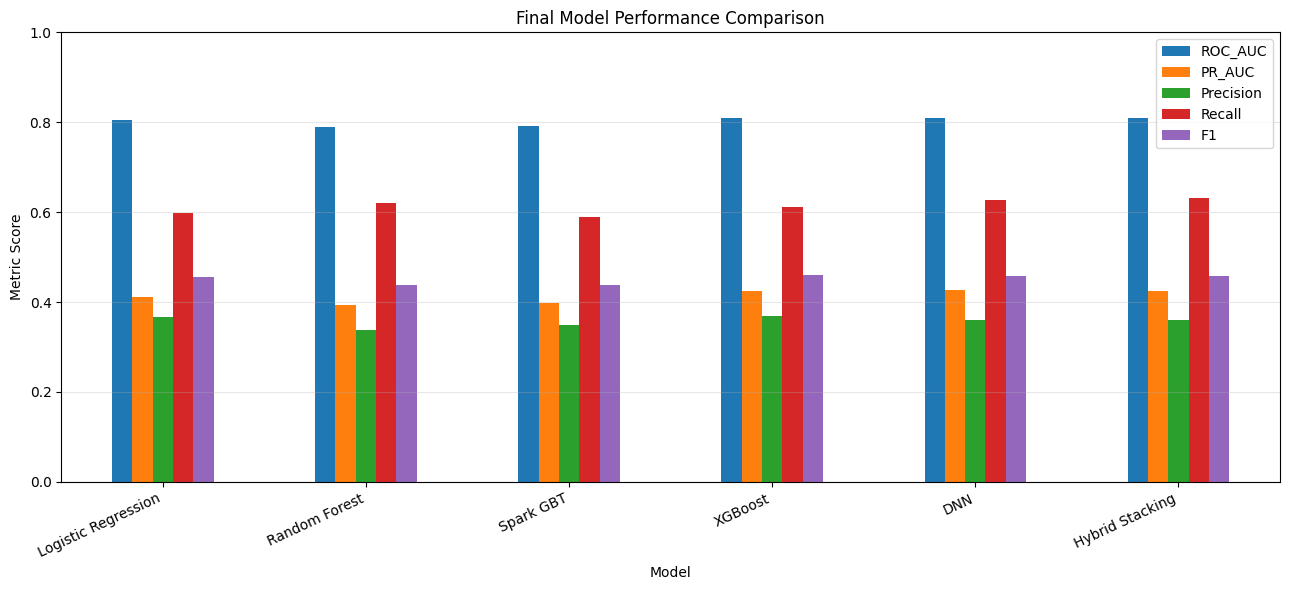


Saved results to: /content/drive/MyDrive/Diabetes_BigData_Project/results/final_evaluation
PHASE 8.5 COMPLETED


In [ ]:

# ============================================================
# PHASE 8.5: FINAL MODEL COMPARISON
# ============================================================

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results", "final_evaluation"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Previously evaluated held-out test results
model_results = [
    {
        "Model": "Logistic Regression",
        "ROC_AUC": 0.8050,
        "PR_AUC": 0.4111,
        "Accuracy": 0.7853,
        "Precision": 0.3676,
        "Recall": 0.5990,
        "Specificity": 0.8182,
        "F1": 0.4556
    },
    {
        "Model": "Random Forest",
        "ROC_AUC": 0.7889,
        "PR_AUC": 0.3945,
        "Accuracy": 0.7605,
        "Precision": 0.3376,
        "Recall": 0.6208,
        "Specificity": 0.7851,
        "F1": 0.4374
    },
    {
        "Model": "Spark GBT",
        "ROC_AUC": 0.7910,
        "PR_AUC": 0.3972,
        "Accuracy": 0.7732,
        "Precision": 0.3484,
        "Recall": 0.5883,
        "Specificity": 0.8059,
        "F1": 0.4376
    },
    {
        "Model": "XGBoost",
        "ROC_AUC": 0.8091,
        "PR_AUC": 0.4238,
        "Accuracy": 0.7846,
        "Precision": 0.3684,
        "Recall": 0.6105,
        "Specificity": 0.8154,
        "F1": 0.4595
    },
    {
        "Model": "DNN",
        "ROC_AUC": 0.8096,
        "PR_AUC": 0.4258,
        "Accuracy": 0.7777,
        "Precision": 0.3611,
        "Recall": 0.6272,
        "Specificity": 0.8042,
        "F1": 0.4583
    },
    {
        "Model": "Hybrid Stacking",
        "ROC_AUC": 0.8096,
        "PR_AUC": 0.4253,
        "Accuracy": 0.7764,
        "Precision": 0.3600,
        "Recall": 0.6310,
        "Specificity": 0.8021,
        "F1": 0.4585
    }
]

comparison = pd.DataFrame(model_results)

comparison.to_csv(
    os.path.join(OUTPUT_DIR, "final_model_comparison.csv"),
    index=False
)

print("=" * 75)
print("FINAL MODEL COMPARISON")
print("=" * 75)
print(comparison.round(4).to_string(index=False))

# ------------------------------------------------------------
# Identify metric leaders
# ------------------------------------------------------------

print("\nMETRIC LEADERS")
for metric in [
    "ROC_AUC", "PR_AUC", "Accuracy",
    "Precision", "Recall", "Specificity", "F1"
]:
    best_index = comparison[metric].idxmax()
    print(
        f"{metric:15s}: "
        f"{comparison.loc[best_index, 'Model']} "
        f"({comparison.loc[best_index, metric]:.4f})"
    )

# ------------------------------------------------------------
# Comparison chart
# ------------------------------------------------------------

metrics = [
    "ROC_AUC", "PR_AUC", "Precision", "Recall", "F1"
]

ax = comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("Final Model Performance Comparison")
ax.set_ylabel("Metric Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "final_model_comparison.png"),
    dpi=200
)

plt.show()

print("\nSaved results to:", OUTPUT_DIR)
print("PHASE 8.5 COMPLETED")


In [ ]:

# ============================================================
# PHASE 8.6: FREEZE AND PACKAGE VERIFIED HYBRID MODEL
# ============================================================

import os
import json
import shutil
import joblib
import torch
import pandas as pd
import sklearn
import xgboost
import numpy as np

from datetime import datetime, timezone

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

SOURCE_DIR = os.path.join(
    PROJECT_DIR, "results", "strict_oof"
)

FINAL_DIR = os.path.join(
    PROJECT_DIR, "deployment", "frozen_model"
)

os.makedirs(FINAL_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load verified model components
# ------------------------------------------------------------

source_bundle = joblib.load(
    os.path.join(
        SOURCE_DIR,
        "strict_oof_hybrid_models.joblib"
    )
)

required_keys = [
    "preprocessor",
    "xgb_model",
    "meta_model",
    "threshold",
    "results"
]

missing = [
    key for key in required_keys
    if key not in source_bundle
]

if missing:
    raise ValueError(f"Missing model components: {missing}")

preprocessor = source_bundle["preprocessor"]
xgb_model = source_bundle["xgb_model"]
meta_model = source_bundle["meta_model"]
threshold = float(source_bundle["threshold"])

# ------------------------------------------------------------
# 2. Define original feature schema
# ------------------------------------------------------------

feature_cols = [
    "age_group", "sex", "education", "employment",
    "income", "marital_status", "smoking_status", "checkup",
    "BMI", "physical_unhealthy_days", "mental_unhealthy_days",
    "exercise", "alcohol_use", "asthma", "kidney_disease",
    "heart_attack", "coronary_heart_disease", "stroke",
    "arthritis", "depression", "medical_cost_barrier",
    "difficulty_walking", "difficulty_dressing",
    "difficulty_errands"
]

# ------------------------------------------------------------
# 3. Load and validate DNN weights
# ------------------------------------------------------------

dnn_source = os.path.join(
    SOURCE_DIR,
    "strict_oof_final_dnn.pt"
)

if not os.path.exists(dnn_source):
    raise FileNotFoundError(dnn_source)

try:
    dnn_state = torch.load(
        dnn_source,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    dnn_state = torch.load(
        dnn_source,
        map_location="cpu"
    )

if not isinstance(dnn_state, dict):
    raise TypeError("Expected DNN state dictionary.")

# ------------------------------------------------------------
# 4. Save portable model components
# ------------------------------------------------------------

inference_bundle = {
    "preprocessor": preprocessor,
    "xgb_model": xgb_model,
    "meta_model": meta_model,
    "threshold": threshold,
    "feature_cols": feature_cols,
    "dnn_architecture": {
        "input_dim": 72,
        "hidden_layers": [256, 128, 64],
        "activation": "ReLU",
        "batch_norm": True,
        "dropout": [0.30, 0.25, 0.15],
        "output_dim": 1,
        "output_type": "logit"
    }
}

bundle_output = os.path.join(
    FINAL_DIR,
    "hybrid_inference_bundle.joblib"
)

joblib.dump(
    inference_bundle,
    bundle_output,
    compress=3
)

dnn_output = os.path.join(
    FINAL_DIR,
    "hybrid_dnn_state_dict.pt"
)

torch.save(
    dnn_state,
    dnn_output
)

# ------------------------------------------------------------
# 5. Save model evaluation metadata
# ------------------------------------------------------------

evaluation = {
    "ROC_AUC": 0.8096057256654041,
    "PR_AUC": 0.42531140224114716,
    "Accuracy": 0.776439795025197,
    "Precision": 0.36001551791025477,
    "Recall": 0.6310421034736783,
    "Specificity": 0.8020914562213824,
    "F1": 0.45846970913357626,
    "Threshold": threshold,
    "TP": 11136,
    "FP": 19796,
    "FN": 6511,
    "TN": 80230,
    "test_rows": 117673
}

with open(
    os.path.join(FINAL_DIR, "evaluation_metrics.json"),
    "w"
) as f:
    json.dump(evaluation, f, indent=4)

# ------------------------------------------------------------
# 6. Save model metadata / model card
# ------------------------------------------------------------

metadata = {
    "project": (
        "Big Data-Driven Explainable Hybrid "
        "Deep Learning Framework for Diabetes Classification"
    ),
    "model_name": "Hybrid Stacking",
    "model_version": "1.0.0",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": "CDC BRFSS 2024 and 2025",
    "dataset_rows": 784473,
    "test_rows": 117673,
    "target": (
        "Self-reported diagnosed diabetes classification "
        "using BRFSS indicators"
    ),
    "architecture": [
        "ColumnTransformer preprocessing",
        "XGBoost base learner",
        "PyTorch DNN base learner",
        "Logistic Regression meta-learner"
    ],
    "threshold": threshold,
    "transformed_features": 72,
    "original_features": feature_cols,
    "limitations": [
        "Not a clinical diagnostic tool.",
        "Does not predict future diabetes onset.",
        "BRFSS is repeated cross-sectional survey data.",
        "Survey-weighted population inference is not established.",
        "Age subgroup performance disparities require attention.",
        "Model evaluation does not establish causal relationships."
    ],
    "software_versions": {
        "python_torch": torch.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__
    }
}

with open(
    os.path.join(FINAL_DIR, "model_metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

# ------------------------------------------------------------
# 7. Reload package independently and verify
# ------------------------------------------------------------

reloaded = joblib.load(bundle_output)

reloaded_state = torch.load(
    dnn_output,
    map_location="cpu",
    weights_only=True
)

assert reloaded["threshold"] == threshold
assert len(reloaded["feature_cols"]) == 24
assert len(reloaded["preprocessor"].get_feature_names_out()) == 72
assert reloaded["xgb_model"] is not None
assert reloaded["meta_model"] is not None
assert len(reloaded_state) == len(dnn_state)

# Check XGBoost input dimension
assert reloaded["xgb_model"].n_features_in_ == 72

# ------------------------------------------------------------
# 8. Save package manifest
# ------------------------------------------------------------

manifest = {
    "files": [
        "hybrid_inference_bundle.joblib",
        "hybrid_dnn_state_dict.pt",
        "evaluation_metrics.json",
        "model_metadata.json"
    ],
    "package_status": "verified",
    "threshold": threshold,
    "feature_count": len(feature_cols),
    "transformed_feature_count": 72
}

with open(
    os.path.join(FINAL_DIR, "manifest.json"),
    "w"
) as f:
    json.dump(manifest, f, indent=4)

# ------------------------------------------------------------
# 9. Display package contents
# ------------------------------------------------------------

print("=" * 70)
print("FINAL HYBRID MODEL PACKAGE")
print("=" * 70)

for filename in os.listdir(FINAL_DIR):
    path = os.path.join(FINAL_DIR, filename)
    print(
        f"{filename:40s} "
        f"{os.path.getsize(path) / (1024 * 1024):.2f} MB"
    )

print("\nPACKAGE VALIDATION")
print("Preprocessor: PASSED")
print("XGBoost: PASSED")
print("DNN weights: PASSED")
print("Meta learner: PASSED")
print("Feature schema: PASSED")
print("Threshold: PASSED")
print("Reload test: PASSED")

print("\nFINAL PACKAGE LOCATION:")
print(FINAL_DIR)

print("\nPHASE 8.6 COMPLETED")


FINAL HYBRID MODEL PACKAGE
hybrid_inference_bundle.joblib           0.24 MB
hybrid_dnn_state_dict.pt                 0.24 MB
evaluation_metrics.json                  0.00 MB
model_metadata.json                      0.00 MB
manifest.json                            0.00 MB

PACKAGE VALIDATION
Preprocessor: PASSED
XGBoost: PASSED
DNN weights: PASSED
Meta learner: PASSED
Feature schema: PASSED
Threshold: PASSED
Reload test: PASSED

FINAL PACKAGE LOCATION:
/content/drive/MyDrive/Diabetes_BigData_Project/deployment/frozen_model

PHASE 8.6 COMPLETED


In [ ]:

# ================================================================
# FINAL RESEARCH REPORT GENERATOR
# Big Data-Driven Explainable Hybrid Deep Learning Framework
# ================================================================

!pip -q install reportlab

import os
import json
import pandas as pd
from datetime import datetime

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import inch, cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, PageBreak, KeepTogether
)

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

SHAP_DIR = os.path.join(RESULTS_DIR, "explainability")
STRICT_DIR = os.path.join(RESULTS_DIR, "strict_oof")
FAIRNESS_DIR = os.path.join(RESULTS_DIR, "fairness")
HYBRID_DIR = os.path.join(RESULTS_DIR, "hybrid_robustness")
CAL_DIR = os.path.join(RESULTS_DIR, "calibration")
SCALE_DIR = os.path.join(RESULTS_DIR, "scalability")
FINAL_EVAL_DIR = os.path.join(RESULTS_DIR, "final_evaluation")

REPORT_DIR = os.path.join(
    PROJECT_DIR, "reports", "final"
)

os.makedirs(REPORT_DIR, exist_ok=True)

PDF_PATH = os.path.join(
    REPORT_DIR,
    "Final_Diabetes_Research_Report.pdf"
)

# ------------------------------------------------
# 2. DOCUMENT CONFIGURATION
# ------------------------------------------------

doc = SimpleDocTemplate(
    PDF_PATH,
    pagesize=A4,
    rightMargin=1.7*cm,
    leftMargin=1.7*cm,
    topMargin=1.8*cm,
    bottomMargin=1.8*cm,
    title="Diabetes Research Report",
    author="Research Project"
)

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="ReportTitle",
    parent=styles["Title"],
    fontSize=23,
    leading=30,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=16
))

styles.add(ParagraphStyle(
    name="SubtitleCustom",
    parent=styles["Normal"],
    fontSize=12,
    leading=18,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#526477"),
    spaceAfter=12
))

styles.add(ParagraphStyle(
    name="SectionCustom",
    parent=styles["Heading1"],
    fontSize=16,
    leading=21,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=15,
    spaceAfter=9
))

styles.add(ParagraphStyle(
    name="SubsectionCustom",
    parent=styles["Heading2"],
    fontSize=12,
    leading=16,
    textColor=colors.HexColor("#2874A6"),
    spaceBefore=10,
    spaceAfter=6
))

styles.add(ParagraphStyle(
    name="BodyCustom",
    parent=styles["BodyText"],
    fontSize=9,
    leading=14,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="SmallCustom",
    parent=styles["BodyText"],
    fontSize=7.5,
    leading=10
))

story = []

# ------------------------------------------------
# 3. HELPER FUNCTIONS
# ------------------------------------------------

def add_heading(text, level=1):
    style = (
        styles["SectionCustom"]
        if level == 1
        else styles["SubsectionCustom"]
    )
    story.append(Paragraph(text, style))


def add_text(text):
    story.append(
        Paragraph(text, styles["BodyCustom"])
    )


def add_table(data, widths=None, font_size=7.5):

    converted = []

    for row in data:
        converted.append([
            Paragraph(
                str(value),
                styles["SmallCustom"]
            )
            for value in row
        ])

    table = Table(
        converted,
        colWidths=widths,
        repeatRows=1,
        hAlign="LEFT"
    )

    table.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0),
         colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.35,
         colors.HexColor("#D5DDE5")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F2F6FA")]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
        ("FONTSIZE", (0, 0), (-1, -1), font_size)
    ]))

    story.append(table)
    story.append(Spacer(1, 10))


def add_csv_table(path, columns=None, max_rows=15):

    if not os.path.exists(path):
        add_text(
            f"<i>Data file not available: {os.path.basename(path)}</i>"
        )
        return

    df = pd.read_csv(path)

    if columns:
        available = [c for c in columns if c in df.columns]
        if available:
            df = df[available]

    df = df.head(max_rows)

    data = [list(df.columns)]

    for _, row in df.iterrows():
        data.append([
            (
                f"{value:.4f}"
                if isinstance(value, float)
                else str(value)
            )
            for value in row
        ])

    add_table(data)


def add_image(path, width=16.5*cm):

    if not os.path.exists(path):
        return False

    try:
        img = Image(path)
        img._restrictSize(width, 10.5*cm)
        img.hAlign = "CENTER"

        story.append(img)
        story.append(Spacer(1, 10))
        return True

    except Exception as e:
        print("Image skipped:", path, str(e))
        return False


def new_page():
    story.append(PageBreak())


def footer(canvas, document):

    canvas.saveState()

    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#667788"))

    canvas.drawString(
        1.7*cm,
        1.0*cm,
        "Diabetes Research Project | BRFSS 2024–2025"
    )

    canvas.drawRightString(
        A4[0] - 1.7*cm,
        1.0*cm,
        f"Page {document.page}"
    )

    canvas.restoreState()


# ------------------------------------------------
# 4. TITLE PAGE
# ------------------------------------------------

story.append(Spacer(1, 3*cm))

story.append(Paragraph(
    "BIG DATA-DRIVEN EXPLAINABLE<br/>"
    "HYBRID DEEP LEARNING FRAMEWORK<br/>"
    "FOR DIABETES CLASSIFICATION",
    styles["ReportTitle"]
))

story.append(Spacer(1, 0.5*cm))

story.append(Paragraph(
    "A Research and Experimental Evaluation Report",
    styles["SubtitleCustom"]
))

story.append(Spacer(1, 1.5*cm))

story.append(Paragraph(
    "<b>Dataset:</b> CDC BRFSS 2024 and 2025",
    styles["SubtitleCustom"]
))

story.append(Paragraph(
    "<b>Framework:</b> Apache Spark, Machine Learning, "
    "Deep Learning and Explainable AI",
    styles["SubtitleCustom"]
))

story.append(Paragraph(
    "<b>Final classifier:</b> XGBoost–DNN Hybrid Stacking "
    "with Logistic Regression Meta-Learning",
    styles["SubtitleCustom"]
))

story.append(Spacer(1, 2*cm))

story.append(Paragraph(
    "Generated: " + datetime.now().strftime("%d %B %Y"),
    styles["SubtitleCustom"]
))

new_page()

# ------------------------------------------------
# 5. ABSTRACT
# ------------------------------------------------

add_heading("Abstract")

add_text(
    "This research investigates a big-data-driven framework for "
    "classifying self-reported diagnosed diabetes status using "
    "the 2024 and 2025 Behavioral Risk Factor Surveillance System "
    "(BRFSS) datasets. The workflow combines large-scale data "
    "preprocessing, conventional machine learning, deep learning, "
    "hybrid stacking, explainable AI, calibration, fairness "
    "evaluation and scalability benchmarking."
)

add_text(
    "The evaluated classification approaches include Logistic "
    "Regression, Random Forest, Spark Gradient-Boosted Trees, "
    "XGBoost, a Deep Neural Network and a hybrid stacking classifier. "
    "The hybrid architecture combines XGBoost and DNN predictions "
    "through a Logistic Regression meta-learner trained using "
    "three-fold out-of-fold predictions."
)

add_text(
    "The final hybrid model achieved a test ROC-AUC of 0.8096, "
    "PR-AUC of 0.4253 and recall of 0.6310 at a classification "
    "threshold of 0.23. Explainability, subgroup performance, "
    "temporal consistency and probability calibration were "
    "also examined."
)

# ------------------------------------------------
# 6. DATASET DESCRIPTION
# ------------------------------------------------

add_heading("1. Dataset and Research Objective")

add_text(
    "The study uses CDC BRFSS 2024 and 2025 survey datasets. "
    "BRFSS is a repeated cross-sectional survey. The analysis "
    "classifies self-reported diagnosed diabetes status and "
    "does not track the same individuals longitudinally."
)

dataset_data = [
    ["Dataset characteristic", "Value"],
    ["2024 raw records", "457,670"],
    ["2025 raw records", "356,158"],
    ["Combined raw records", "813,828"],
    ["Retained records", "784,473"],
    ["Positive class", "117,636"],
    ["Negative class", "666,837"],
    ["Original features", "24"],
    ["Transformed hybrid features", "72"]
]

add_table(dataset_data, [7*cm, 8*cm])

add_text(
    "The target variable was constructed from DIABETE4. "
    "Code 1 represented the positive class and code 3 represented "
    "the negative class. Pregnancy-only, prediabetes/borderline, "
    "unknown and missing target responses were excluded."
)

# ------------------------------------------------
# 7. MODEL METHODOLOGY
# ------------------------------------------------

add_heading("2. Classification Algorithms")

algorithm_data = [
    ["Algorithm", "Role"],
    ["Logistic Regression", "Linear baseline classifier"],
    ["Random Forest", "Bagging-based tree ensemble"],
    ["Spark GBT", "Distributed-framework tree boosting model"],
    ["XGBoost", "Gradient-boosted tree classifier"],
    ["DNN", "Fully connected neural network"],
    ["Hybrid Stacking", "XGBoost + DNN + Logistic Regression"]
]

add_table(algorithm_data, [6*cm, 9*cm])

add_heading("2.1 Hybrid Stacking Architecture", 2)

add_text(
    "The final hybrid classifier uses XGBoost and a Deep Neural "
    "Network as base learners. Their out-of-fold predicted "
    "probabilities are used to train a Logistic Regression "
    "meta-learner. Three-fold stratified cross-validation is used "
    "to generate the out-of-fold training predictions."
)

add_text(
    "At inference time, the final XGBoost and DNN models generate "
    "two probabilities. These probabilities are passed to the "
    "trained meta-learner, which generates the final hybrid "
    "probability. A threshold of 0.23 is used for binary "
    "classification."
)

add_text(
    "The model's output represents classification of self-reported "
    "diagnosed diabetes status, not a clinical diagnosis or "
    "prediction of future diabetes onset."
)

# ------------------------------------------------
# 8. FINAL MODEL COMPARISON
# ------------------------------------------------

new_page()
add_heading("3. Comparative Model Evaluation")

comparison_path = os.path.join(
    FINAL_EVAL_DIR,
    "final_model_comparison.csv"
)

if os.path.exists(comparison_path):

    comparison = pd.read_csv(comparison_path)

    add_table([
        list(comparison.columns)
    ] + [
        [
            (
                f"{value:.4f}"
                if isinstance(value, float)
                else str(value)
            )
            for value in row
        ]
        for row in comparison.values
    ])

add_image(
    os.path.join(
        FINAL_EVAL_DIR,
        "final_model_comparison.png"
    )
)

add_text(
    "The DNN achieved the highest ROC-AUC and PR-AUC among "
    "the reported models. Logistic Regression achieved the "
    "highest accuracy and specificity. XGBoost achieved the "
    "highest F1-score, while Hybrid Stacking achieved the "
    "highest recall. These results do not establish that the "
    "hybrid model is statistically superior to every baseline."
)

# ------------------------------------------------
# 9. HYBRID MODEL RESULTS
# ------------------------------------------------

add_heading("4. Final Hybrid Model Evaluation")

hybrid_results = [
    ["Metric", "Test result"],
    ["ROC-AUC", "0.809606"],
    ["PR-AUC", "0.425311"],
    ["Accuracy", "0.776440"],
    ["Precision", "0.360016"],
    ["Recall", "0.631042"],
    ["Specificity", "0.802091"],
    ["F1-score", "0.458470"],
    ["Threshold", "0.23"]
]

add_table(hybrid_results, [7*cm, 8*cm])

add_heading("4.1 Confusion Matrix", 2)

confusion_data = [
    ["", "Predicted negative", "Predicted positive"],
    ["Actual negative", "80,230 (TN)", "19,796 (FP)"],
    ["Actual positive", "6,511 (FN)", "11,136 (TP)"]
]

add_table(confusion_data, [5*cm, 5*cm, 5*cm])

add_text(
    "At the selected threshold, the model identifies approximately "
    "63.10% of positive test cases. Precision is approximately "
    "36.00%, indicating a substantial number of false-positive "
    "classifications. These trade-offs should be considered when "
    "interpreting the model."
)

# ------------------------------------------------
# 10. CALIBRATION
# ------------------------------------------------

new_page()
add_heading("5. Probability Calibration")

calibration_path = os.path.join(
    CAL_DIR, "calibration_metrics.csv"
)

add_csv_table(calibration_path, max_rows=5)

add_image(
    os.path.join(
        CAL_DIR,
        "hybrid_calibration_curve.png"
    )
)

add_text(
    "The calibration evaluation examines agreement between "
    "predicted probabilities and observed positive frequencies. "
    "The validation Brier score was 0.105483, with log loss "
    "0.339539 and ECE 0.004587. The test Brier score was "
    "0.105359, log loss 0.339294 and ECE 0.006636."
)

add_text(
    "These values indicate good observed calibration under the "
    "chosen ten-bin quantile evaluation. ECE is dependent on the "
    "binning procedure and should not be interpreted as proof "
    "of perfect calibration."
)

# ------------------------------------------------
# 11. EXPLAINABLE AI
# ------------------------------------------------

new_page()
add_heading("6. Explainable Artificial Intelligence")

add_text(
    "SHAP (SHapley Additive exPlanations) was used to examine "
    "the contribution of input features to the XGBoost classifier's "
    "outputs. The SHAP analysis in this experiment explains "
    "XGBoost, not the final hybrid meta-learner."
)

shap_images = [
    ("Global SHAP summary",
     "shap_summary_xgboost.png"),
    ("Corrected grouped feature importance",
     "corrected_grouped_shap.png"),
    ("BMI dependence analysis",
     "shap_bmi_dependence.png"),
    ("Age-group contribution analysis",
     "shap_age_group_distribution.png")
]

for caption, filename in shap_images:
    path = os.path.join(SHAP_DIR, filename)

    if os.path.exists(path):
        add_heading(caption, 2)
        add_image(path)

grouped_shap_path = os.path.join(
    SHAP_DIR, "corrected_grouped_shap.csv"
)

if os.path.exists(grouped_shap_path):
    add_heading("Grouped SHAP feature ranking", 2)
    add_csv_table(
        grouped_shap_path,
        max_rows=15
    )

# ------------------------------------------------
# 12. INDIVIDUAL EXPLANATIONS
# ------------------------------------------------

add_heading("6.1 Individual Explanations", 2)

individual_dir = os.path.join(
    SHAP_DIR, "individual_explanations"
)

for filename in [
    "true_positive_waterfall.png",
    "false_positive_waterfall.png",
    "false_negative_waterfall.png",
    "true_negative_waterfall.png"
]:

    path = os.path.join(individual_dir, filename)

    if os.path.exists(path):
        add_heading(
            filename.replace("_waterfall.png", "").replace("_", " "),
            2
        )
        add_image(path, width=15.5*cm)

# ------------------------------------------------
# 13. FAIRNESS ANALYSIS
# ------------------------------------------------

new_page()
add_heading("7. Fairness and Subgroup Evaluation")

add_text(
    "The final hybrid model was evaluated across age groups, "
    "sex groups and age-by-sex intersectional groups using "
    "a common classification threshold of 0.23. Subgroup "
    "metrics are descriptive diagnostics and do not by "
    "themselves establish discriminatory bias."
)

add_heading("7.1 Age-wise Hybrid Evaluation", 2)

add_csv_table(
    os.path.join(HYBRID_DIR, "hybrid_by_age.csv"),
    columns=[
        "age_group", "n", "positive_cases", "prevalence",
        "recall", "specificity", "FPR", "FNR", "F1"
    ],
    max_rows=20
)

add_heading("7.2 Sex-wise Hybrid Evaluation", 2)

add_csv_table(
    os.path.join(HYBRID_DIR, "hybrid_by_sex.csv"),
    max_rows=10
)

add_heading("7.3 Intersectional Evaluation", 2)

add_csv_table(
    os.path.join(HYBRID_DIR, "hybrid_intersectional.csv"),
    columns=[
        "age_group", "sex", "n", "positive_cases",
        "prevalence", "recall", "specificity", "FPR", "FNR"
    ],
    max_rows=30
)

add_heading("7.4 Fairness Gaps", 2)

add_csv_table(
    os.path.join(
        HYBRID_DIR,
        "hybrid_fairness_gaps.csv"
    ),
    max_rows=10
)

add_text(
    "The hybrid model showed an age-wise recall gap of "
    "approximately 72.23 percentage points and a sex-wise "
    "recall gap of approximately 5.99 percentage points. "
    "Low recall in some age groups requires careful attention. "
    "Differences may reflect prevalence, survey reporting "
    "patterns and other factors."
)

# ------------------------------------------------
# 14. TEMPORAL EVALUATION
# ------------------------------------------------

new_page()
add_heading("8. Temporal Evaluation: 2024 to 2025")

add_text(
    "A separate temporal experiment trained models using "
    "2024 data and evaluated them on 2025 data. This experiment "
    "provides an additional year-based robustness assessment "
    "for XGBoost and DNN; it is distinct from the random "
    "held-out hybrid test evaluation."
)

add_csv_table(
    os.path.join(HYBRID_DIR, "hybrid_by_year.csv"),
    max_rows=10
)

add_text(
    "The hybrid model's held-out test subgroup evaluation "
    "also showed similar results across the two survey years. "
    "Because only two years are included, this should not "
    "be interpreted as evidence of long-term generalisation."
)

# ------------------------------------------------
# 15. SCALABILITY
# ------------------------------------------------

new_page()
add_heading("9. Scalability Benchmarking")

add_text(
    "A controlled single-machine benchmark compared Spark "
    "and Pandas aggregation operations at four dataset sizes. "
    "Five repetitions were performed, and median execution "
    "times were recorded. Pandas aggregation was faster "
    "in this controlled aggregation-only experiment."
)

add_csv_table(
    os.path.join(
        SCALE_DIR,
        "controlled_scalability_benchmark.csv"
    ),
    max_rows=10
)

add_image(
    os.path.join(
        SCALE_DIR,
        "controlled_execution_time.png"
    )
)

add_image(
    os.path.join(
        SCALE_DIR,
        "controlled_throughput.png"
    )
)

add_text(
    "The benchmark was performed using Spark local mode on "
    "a single machine. It is not a multi-node distributed "
    "scalability experiment. Pandas conversion time is "
    "reported separately and should be considered when "
    "interpreting end-to-end processing costs."
)

# ------------------------------------------------
# 16. CONCLUSION AND LIMITATIONS
# ------------------------------------------------

new_page()
add_heading("10. Conclusion")

add_text(
    "The study developed and evaluated a hybrid classification "
    "framework combining XGBoost, a Deep Neural Network and "
    "a Logistic Regression meta-learner. The final hybrid model "
    "achieved a ROC-AUC of 0.8096, PR-AUC of 0.4253 and "
    "recall of 0.6310 on the held-out test set."
)

add_text(
    "The experiments also examined feature contributions "
    "using SHAP, subgroup performance across age and sex, "
    "probability calibration, year-wise consistency and "
    "single-machine Spark versus Pandas processing."
)

add_heading("10.1 Limitations", 2)

limitations = [
    "BRFSS is repeated cross-sectional survey data and does not "
    "provide longitudinal follow-up of the same respondents.",
    "The target represents self-reported diagnosed diabetes status, "
    "not future diabetes onset or a clinical diagnosis.",
    "The reported evaluation does not establish survey-weighted "
    "population-level performance.",
    "Subgroup performance differences require further investigation "
    "and uncertainty estimation.",
    "The SHAP analysis explains the XGBoost model, not the entire "
    "hybrid stacking architecture.",
    "The scalability benchmark was conducted in single-machine "
    "Spark local mode."
]

for item in limitations:
    add_text("• " + item)

add_heading("10.2 Future Work", 2)

add_text(
    "Future work may include survey-design-aware evaluation, "
    "additional years of BRFSS data, confidence intervals for "
    "subgroup metrics, statistical comparisons between models, "
    "hybrid-level explainability and external validation."
)

add_heading("Final Research Note")

add_text(
    "This report documents an experimental machine learning "
    "research framework. Its outputs should not be used as "
    "clinical diagnoses or individual medical advice."
)

# ------------------------------------------------
# 17. BUILD PDF
# ------------------------------------------------

print("Generating final PDF report...")

doc.build(
    story,
    onFirstPage=footer,
    onLaterPages=footer
)

print("\n" + "=" * 65)
print("FINAL RESEARCH REPORT GENERATED")
print("=" * 65)

print("PDF:", PDF_PATH)
print(
    "Size:",
    round(os.path.getsize(PDF_PATH) / (1024 * 1024), 2),
    "MB"
)

print("\nAll available graphs and result tables have been included.")


Generating final PDF report...

FINAL RESEARCH REPORT GENERATED
PDF: /content/drive/MyDrive/Diabetes_BigData_Project/reports/final/Final_Diabetes_Research_Report.pdf
Size: 2.25 MB

All available graphs and result tables have been included.


In [ ]:

# ============================================================
# PHASE 8.7: PAIRED BOOTSTRAP SIGNIFICANCE TESTING
# XGBoost vs DNN vs Hybrid Stacking
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Configuration
PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results", "statistical_significance"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_BOOTSTRAP = 2000
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# ------------------------------------------------------------
# 1. Retrieve previously generated predictions
# ------------------------------------------------------------

required_variables = [
    "xgb_prob",
    "dnn_prob",
    "hybrid_prob"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing predictions: {missing}. "
        "Run Phase 8.2 first and retain its probability arrays."
    )

if "y_test" in globals():
    y = np.asarray(y_test).astype(int)
elif "y" in globals():
    y = np.asarray(y).astype(int)
else:
    raise RuntimeError("Test labels y_test are unavailable.")

probabilities = {
    "XGBoost": np.asarray(xgb_prob),
    "DNN": np.asarray(dnn_prob),
    "Hybrid Stacking": np.asarray(hybrid_prob)
}

for name, p in probabilities.items():
    if len(p) != len(y):
        raise ValueError(
            f"{name} predictions have {len(p)} rows, "
            f"but labels have {len(y)}."
        )

    if not np.isfinite(p).all():
        raise ValueError(f"Non-finite probabilities in {name}.")

# ------------------------------------------------------------
# 2. Calculate observed metrics
# ------------------------------------------------------------

observed = []

for name, p in probabilities.items():

    observed.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y, p),
        "PR_AUC": average_precision_score(y, p)
    })

observed_df = pd.DataFrame(observed)

print("OBSERVED TEST METRICS")
print(observed_df.round(6).to_string(index=False))

# ------------------------------------------------------------
# 3. Paired bootstrap
# Same respondents sampled for all three models
# ------------------------------------------------------------

pairs = [
    ("XGBoost", "DNN"),
    ("XGBoost", "Hybrid Stacking"),
    ("DNN", "Hybrid Stacking")
]

bootstrap_results = []

for model_a, model_b in pairs:

    print(f"\nComparing {model_a} vs {model_b}")

    p_a = probabilities[model_a]
    p_b = probabilities[model_b]

    auc_differences = []
    ap_differences = []

    for iteration in range(N_BOOTSTRAP):

        indices = rng.integers(
            0, len(y), size=len(y)
        )

        y_sample = y[indices]

        # ROC-AUC and PR-AUC require both classes
        if len(np.unique(y_sample)) < 2:
            continue

        auc_a = roc_auc_score(
            y_sample, p_a[indices]
        )
        auc_b = roc_auc_score(
            y_sample, p_b[indices]
        )

        ap_a = average_precision_score(
            y_sample, p_a[indices]
        )
        ap_b = average_precision_score(
            y_sample, p_b[indices]
        )

        # Positive difference means model B is better
        auc_differences.append(auc_b - auc_a)
        ap_differences.append(ap_b - ap_a)

    auc_differences = np.asarray(auc_differences)
    ap_differences = np.asarray(ap_differences)

    def bootstrap_summary(values):

        lower, upper = np.percentile(
            values, [2.5, 97.5]
        )

        # Two-sided bootstrap sign-based p-value
        p_value = min(
            1.0,
            2 * min(
                np.mean(values <= 0),
                np.mean(values >= 0)
            )
        )

        return (
            float(values.mean()),
            float(lower),
            float(upper),
            float(p_value)
        )

    auc_mean, auc_low, auc_high, auc_p = (
        bootstrap_summary(auc_differences)
    )

    ap_mean, ap_low, ap_high, ap_p = (
        bootstrap_summary(ap_differences)
    )

    bootstrap_results.append({
        "Comparison": f"{model_b} - {model_a}",
        "ROC_AUC_Difference": auc_mean,
        "ROC_AUC_CI_Lower": auc_low,
        "ROC_AUC_CI_Upper": auc_high,
        "ROC_AUC_p_value": auc_p,
        "PR_AUC_Difference": ap_mean,
        "PR_AUC_CI_Lower": ap_low,
        "PR_AUC_CI_Upper": ap_high,
        "PR_AUC_p_value": ap_p,
        "Valid_Bootstrap_Replicates": len(auc_differences)
    })

results_df = pd.DataFrame(bootstrap_results)

# ------------------------------------------------------------
# 4. Multiple-comparison correction
# Holm correction for the three comparisons per metric
# ------------------------------------------------------------

def holm_adjust(p_values):

    p_values = np.asarray(p_values, dtype=float)
    m = len(p_values)

    order = np.argsort(p_values)
    adjusted = np.empty(m)

    running_max = 0.0

    for rank, index in enumerate(order):
        value = min(
            1.0,
            (m - rank) * p_values[index]
        )

        running_max = max(running_max, value)
        adjusted[index] = running_max

    return adjusted


results_df["ROC_AUC_p_Holm"] = holm_adjust(
    results_df["ROC_AUC_p_value"]
)

results_df["PR_AUC_p_Holm"] = holm_adjust(
    results_df["PR_AUC_p_value"]
)

results_df["ROC_AUC_significant_0.05"] = (
    results_df["ROC_AUC_p_Holm"] < 0.05
)

results_df["PR_AUC_significant_0.05"] = (
    results_df["PR_AUC_p_Holm"] < 0.05
)

# ------------------------------------------------------------
# 5. Save results
# ------------------------------------------------------------

observed_df.to_csv(
    os.path.join(OUTPUT_DIR, "observed_model_metrics.csv"),
    index=False
)

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "paired_bootstrap_comparisons.csv"),
    index=False
)

print("\n" + "=" * 75)
print("PAIRED BOOTSTRAP COMPARISON RESULTS")
print("=" * 75)

print(results_df.round(6).to_string(index=False))

print("\nInterpretation:")
print("- Difference = Model B metric minus Model A metric.")
print("- Positive difference favours Model B.")
print("- CI excluding zero suggests a difference at the 5% level.")
print("- Holm-adjusted p-values account for three comparisons.")
print("- These are paired bootstrap tests, not DeLong tests.")

print("\nSaved to:", OUTPUT_DIR)


OBSERVED TEST METRICS
          Model  ROC_AUC   PR_AUC
        XGBoost 0.808704 0.423773
            DNN 0.808982 0.423924
Hybrid Stacking 0.809606 0.425311

Comparing XGBoost vs DNN

Comparing XGBoost vs Hybrid Stacking

Comparing DNN vs Hybrid Stacking

PAIRED BOOTSTRAP COMPARISON RESULTS
               Comparison  ROC_AUC_Difference  ROC_AUC_CI_Lower  ROC_AUC_CI_Upper  ROC_AUC_p_value  PR_AUC_Difference  PR_AUC_CI_Lower  PR_AUC_CI_Upper  PR_AUC_p_value  Valid_Bootstrap_Replicates  ROC_AUC_p_Holm  PR_AUC_p_Holm  ROC_AUC_significant_0.05  PR_AUC_significant_0.05
            DNN - XGBoost            0.000274         -0.000321          0.000867            0.363           0.000133        -0.001434         0.001715           0.864                        2000           0.363          0.864                     False                    False
Hybrid Stacking - XGBoost            0.000904          0.000606          0.001204            0.000           0.001551         0.000692         0.002449

In [ ]:

# ============================================================
# PHASE 8.8: FAIRNESS METRICS WITH 95% WILSON CONFIDENCE INTERVALS
# ============================================================

import os
import numpy as np
import pandas as pd

from statsmodels.stats.proportion import proportion_confint

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

OUTPUT_DIR = os.path.join(
    PROJECT_DIR, "results", "fairness_confidence_intervals"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Retrieve test data and predictions
# ------------------------------------------------------------

if "test_pdf" not in globals():
    raise RuntimeError(
        "Run Phase 8.4 first to create test_pdf."
    )

required = [
    "actual", "prediction",
    "age_group", "sex"
]

missing = [
    col for col in required
    if col not in test_pdf.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

df = test_pdf.copy()

# ------------------------------------------------------------
# 2. Wilson confidence interval helper
# ------------------------------------------------------------

def wilson_ci(successes, total):

    if total == 0:
        return np.nan, np.nan

    lower, upper = proportion_confint(
        count=int(successes),
        nobs=int(total),
        alpha=0.05,
        method="wilson"
    )

    return float(lower), float(upper)


def calculate_group_metrics(group):

    actual = group["actual"].astype(int).to_numpy()
    predicted = group["prediction"].astype(int).to_numpy()

    tp = int(((actual == 1) & (predicted == 1)).sum())
    fn = int(((actual == 1) & (predicted == 0)).sum())
    tn = int(((actual == 0) & (predicted == 0)).sum())
    fp = int(((actual == 0) & (predicted == 1)).sum())

    positive_total = tp + fn
    negative_total = tn + fp

    recall = tp / positive_total if positive_total else np.nan
    specificity = tn / negative_total if negative_total else np.nan
    fpr = fp / negative_total if negative_total else np.nan
    fnr = fn / positive_total if positive_total else np.nan

    recall_low, recall_high = wilson_ci(
        tp, positive_total
    )

    specificity_low, specificity_high = wilson_ci(
        tn, negative_total
    )

    fpr_low, fpr_high = wilson_ci(
        fp, negative_total
    )

    fnr_low, fnr_high = wilson_ci(
        fn, positive_total
    )

    return {
        "n": len(group),
        "positive_cases": positive_total,
        "negative_cases": negative_total,
        "TP": tp,
        "FN": fn,
        "TN": tn,
        "FP": fp,
        "prevalence": actual.mean(),
        "recall": recall,
        "recall_CI_lower": recall_low,
        "recall_CI_upper": recall_high,
        "specificity": specificity,
        "specificity_CI_lower": specificity_low,
        "specificity_CI_upper": specificity_high,
        "FPR": fpr,
        "FPR_CI_lower": fpr_low,
        "FPR_CI_upper": fpr_high,
        "FNR": fnr,
        "FNR_CI_lower": fnr_low,
        "FNR_CI_upper": fnr_high
    }


# ------------------------------------------------------------
# 3. Evaluate subgroup dimensions
# ------------------------------------------------------------

def subgroup_confidence_table(
    data,
    group_columns,
    minimum_n=500,
    minimum_positive=30,
    minimum_negative=30
):

    rows = []

    for values, group in data.groupby(
        group_columns,
        dropna=False
    ):

        if not isinstance(values, tuple):
            values = (values,)

        metrics = calculate_group_metrics(group)

        if (
            metrics["n"] < minimum_n or
            metrics["positive_cases"] < minimum_positive or
            metrics["negative_cases"] < minimum_negative
        ):
            continue

        row = dict(zip(group_columns, values))
        row.update(metrics)
        rows.append(row)

    return pd.DataFrame(rows)


age_ci = subgroup_confidence_table(
    df, ["age_group"]
)

sex_ci = subgroup_confidence_table(
    df, ["sex"],
    minimum_n=100,
    minimum_positive=30,
    minimum_negative=30
)

intersection_ci = subgroup_confidence_table(
    df,
    ["age_group", "sex"],
    minimum_n=500,
    minimum_positive=30,
    minimum_negative=30
)

# ------------------------------------------------------------
# 4. Save tables
# ------------------------------------------------------------

age_ci.to_csv(
    os.path.join(OUTPUT_DIR, "age_fairness_CI.csv"),
    index=False
)

sex_ci.to_csv(
    os.path.join(OUTPUT_DIR, "sex_fairness_CI.csv"),
    index=False
)

intersection_ci.to_csv(
    os.path.join(OUTPUT_DIR, "intersectional_fairness_CI.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. Display selected results
# ------------------------------------------------------------

display_columns = [
    "n",
    "positive_cases",
    "recall",
    "recall_CI_lower",
    "recall_CI_upper",
    "specificity",
    "specificity_CI_lower",
    "specificity_CI_upper"
]

print("\nAGE-WISE FAIRNESS WITH 95% CIs")
print(age_ci[["age_group"] + display_columns].round(4).to_string(index=False))

print("\nSEX-WISE FAIRNESS WITH 95% CIs")
print(sex_ci[["sex"] + display_columns].round(4).to_string(index=False))

print("\nINTERSECTIONAL FAIRNESS WITH 95% CIs")
print(
    intersection_ci[
        ["age_group", "sex"] + display_columns
    ].round(4).to_string(index=False)
)

print("\nSaved confidence intervals to:", OUTPUT_DIR)

print(
    "\nIMPORTANT: These are respondent-level Wilson intervals. "
    "They do not account for BRFSS clustering, stratification "
    "or survey weights. Phase 8.9 addresses survey design."
)



AGE-WISE FAIRNESS WITH 95% CIs
 age_group     n  positive_cases  recall  recall_CI_lower  recall_CI_upper  specificity  specificity_CI_lower  specificity_CI_upper
       1.0  7952             102  0.0294           0.0101           0.0829       0.9991                0.9982                0.9996
       2.0  6223             125  0.0160           0.0044           0.0565       0.9992                0.9981                0.9996
       3.0  6609             194  0.0876           0.0554           0.1358       0.9956                0.9937                0.9970
       4.0  7360             328  0.1402           0.1068           0.1820       0.9809                0.9775                0.9839
       5.0  7690             578  0.3097           0.2734           0.3485       0.9457                0.9402                0.9508
       6.0  7251             772  0.4469           0.4122           0.4821       0.8866                0.8786                0.8941
       7.0  7902            1229  0.5834    

In [ ]:

# ============================================================
# CORRECTED PHASE 8.9: STRATIFIED PSU BOOTSTRAP
# PSU mapping is now unique within each stratum
# ============================================================

import numpy as np
import pandas as pd
import os

N_BOOTSTRAP = 500
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

survey_pdf = survey_pdf.reset_index(drop=True)
base_weights = survey_pdf["pooled_weight"].to_numpy(dtype=float)

# ------------------------------------------------------------
# 1. Build PSU-to-row mapping WITHIN EACH STRATUM
# ------------------------------------------------------------

stratum_psu_positions = {}

for stratum, group in survey_pdf.groupby("_design_stratum"):

    psu_positions = {}

    for psu, psu_group in group.groupby("_design_psu"):

        psu_positions[psu] = psu_group.index.to_numpy(
            dtype=int
        )

    stratum_psu_positions[stratum] = psu_positions

singleton_strata = [
    stratum
    for stratum, psus in stratum_psu_positions.items()
    if len(psus) == 1
]

print("Number of strata:", len(stratum_psu_positions))
print("Singleton strata:", len(singleton_strata))

# ------------------------------------------------------------
# 2. Stratified PSU bootstrap
# ------------------------------------------------------------

bootstrap_records = []

for iteration in range(N_BOOTSTRAP):

    multiplier = np.zeros(len(survey_pdf), dtype=float)

    for stratum, psu_positions in stratum_psu_positions.items():

        psus = list(psu_positions.keys())
        m = len(psus)

        # Singleton PSU: retained as a certainty PSU
        if m == 1:
            counts = np.array([1], dtype=int)

        else:
            selected = rng.integers(0, m, size=m)

            counts = np.bincount(
                selected,
                minlength=m
            )

        # Apply each PSU's multiplicity only to rows
        # belonging to that PSU within this stratum.
        for j, psu in enumerate(psus):

            if counts[j] > 0:

                positions = psu_positions[psu]

                multiplier[positions] = counts[j]

    replicate_weights = base_weights * multiplier

    if np.count_nonzero(replicate_weights) == 0:
        continue

    try:
        metrics = weighted_metrics(
            survey_pdf,
            replicate_weights
        )

        bootstrap_records.append(metrics)

    except ValueError:
        continue

    if (iteration + 1) % 50 == 0:
        print(
            f"Completed {iteration + 1}/{N_BOOTSTRAP} replicates"
        )

bootstrap_df = pd.DataFrame(bootstrap_records)

if len(bootstrap_df) < 100:
    raise RuntimeError(
        "Too few valid bootstrap replicates."
    )

print("\nValid bootstrap replicates:", len(bootstrap_df))

# ------------------------------------------------------------
# 3. Calculate percentile confidence intervals
# ------------------------------------------------------------

point_estimates = weighted_metrics(
    survey_pdf,
    base_weights
)

ci_rows = []

for metric, point_value in point_estimates.items():

    values = bootstrap_df[metric].dropna()

    lower, upper = np.percentile(
        values,
        [2.5, 97.5]
    )

    ci_rows.append({
        "Metric": metric,
        "Point_Estimate": point_value,
        "CI_95_Lower": float(lower),
        "CI_95_Upper": float(upper),
        "Valid_Bootstrap_Replicates": len(values)
    })

ci_df = pd.DataFrame(ci_rows)

# ------------------------------------------------------------
# 4. Diagnostic: compare bootstrap and point estimates
# ------------------------------------------------------------

print("\nBOOTSTRAP DIAGNOSTIC")

for metric in [
    "Weighted_TP",
    "Weighted_FP",
    "Weighted_FN",
    "Weighted_TN"
]:

    bootstrap_mean = bootstrap_df[metric].mean()
    point_value = point_estimates[metric]

    print(f"\n{metric}")
    print(f"Point estimate : {point_value:,.2f}")
    print(f"Bootstrap mean : {bootstrap_mean:,.2f}")
    print(
        "Mean / point ratio:",
        round(bootstrap_mean / point_value, 4)
        if point_value != 0 else np.nan
    )

# ------------------------------------------------------------
# 5. Save corrected outputs
# ------------------------------------------------------------

OUTPUT_DIR = os.path.join(
    PROJECT_DIR,
    "results",
    "survey_design"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

ci_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "survey_weighted_metrics_with_CI.csv"
    ),
    index=False
)

bootstrap_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "survey_psu_bootstrap_replicates.csv"
    ),
    index=False
)

print("\n" + "=" * 75)
print("CORRECTED SURVEY-DESIGN BOOTSTRAP RESULTS")
print("=" * 75)

print(ci_df.round(6).to_string(index=False))

print("\nSaved to:", OUTPUT_DIR)


Number of strata: 3879
Singleton strata: 415
Completed 50/500 replicates
Completed 100/500 replicates
Completed 150/500 replicates
Completed 200/500 replicates
Completed 250/500 replicates
Completed 300/500 replicates
Completed 350/500 replicates
Completed 400/500 replicates
Completed 450/500 replicates
Completed 500/500 replicates

Valid bootstrap replicates: 500

BOOTSTRAP DIAGNOSTIC

Weighted_TP
Point estimate : 2,736,532.20
Bootstrap mean : 2,732,690.60
Mean / point ratio: 0.9986

Weighted_FP
Point estimate : 4,698,955.14
Bootstrap mean : 4,698,799.42
Mean / point ratio: 1.0

Weighted_FN
Point estimate : 1,883,851.57
Bootstrap mean : 1,882,818.14
Mean / point ratio: 0.9995

Weighted_TN
Point estimate : 26,735,754.57
Bootstrap mean : 26,739,898.73
Mean / point ratio: 1.0002

CORRECTED SURVEY-DESIGN BOOTSTRAP RESULTS
              Metric  Point_Estimate  CI_95_Lower  CI_95_Upper  Valid_Bootstrap_Replicates
    Weighted_ROC_AUC    8.323920e-01 8.259980e-01 8.388400e-01                

PHASE 9: REPORT ASSET GENERATION

AUDITING EXISTING PROJECT RESULTS...
Files found: 70
                                File                                         Folder Extension  Size_KB
              fold_1_predictions.npz                             results/strict_oof      .npz  1561.46
              fold_2_predictions.npz                             results/strict_oof      .npz  1560.74
              fold_3_predictions.npz                             results/strict_oof      .npz  1562.42
      strict_oof_predictions.parquet                             results/strict_oof  .parquet  5386.23
     strict_oof_hybrid_models.joblib                             results/strict_oof   .joblib   822.28
             strict_oof_final_dnn.pt                             results/strict_oof       .pt   249.02
         strict_oof_test_results.csv                             results/strict_oof      .csv     0.25
          phase8_artifact_audit.json                             results/strict_oof     .

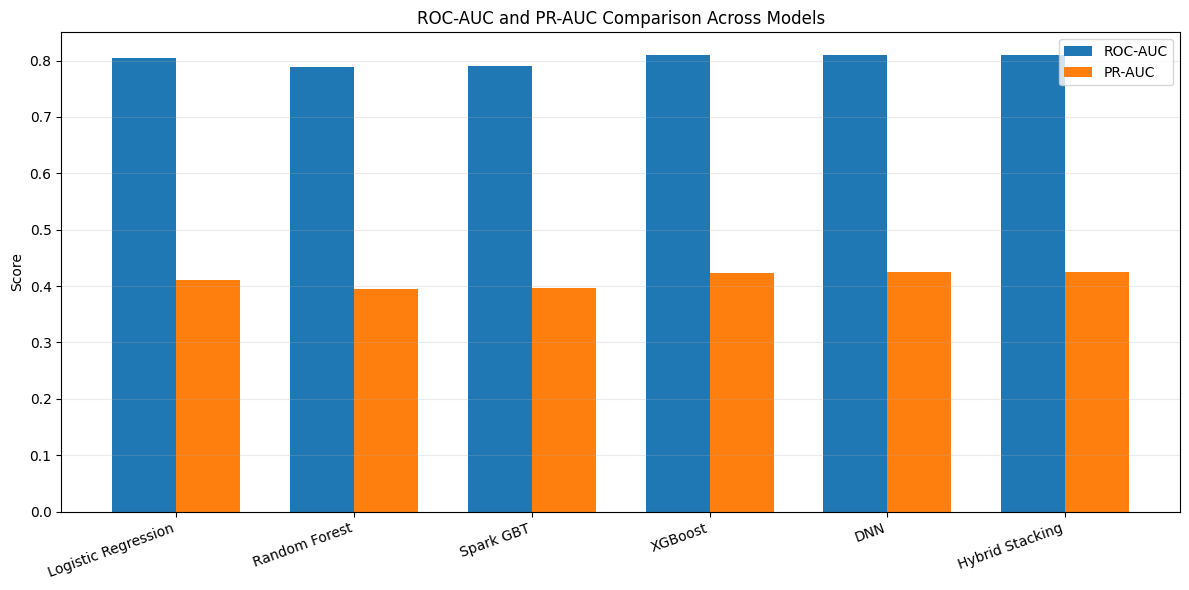

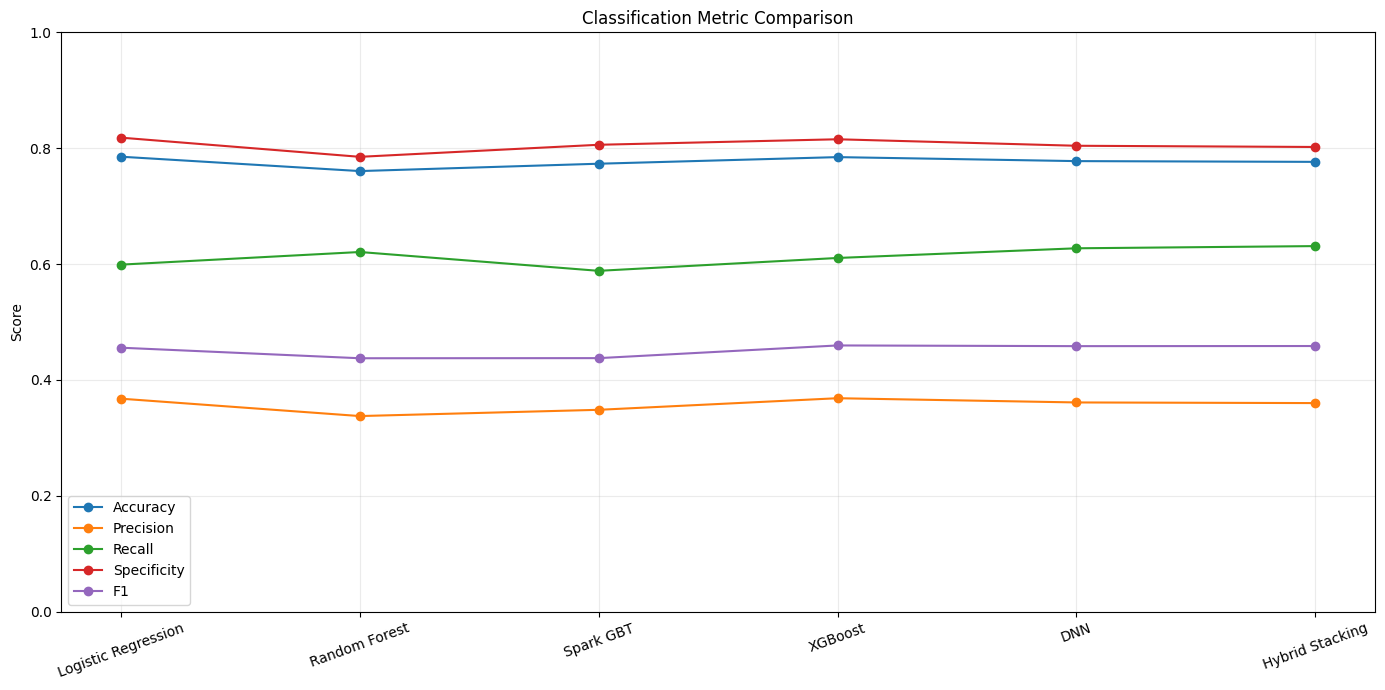

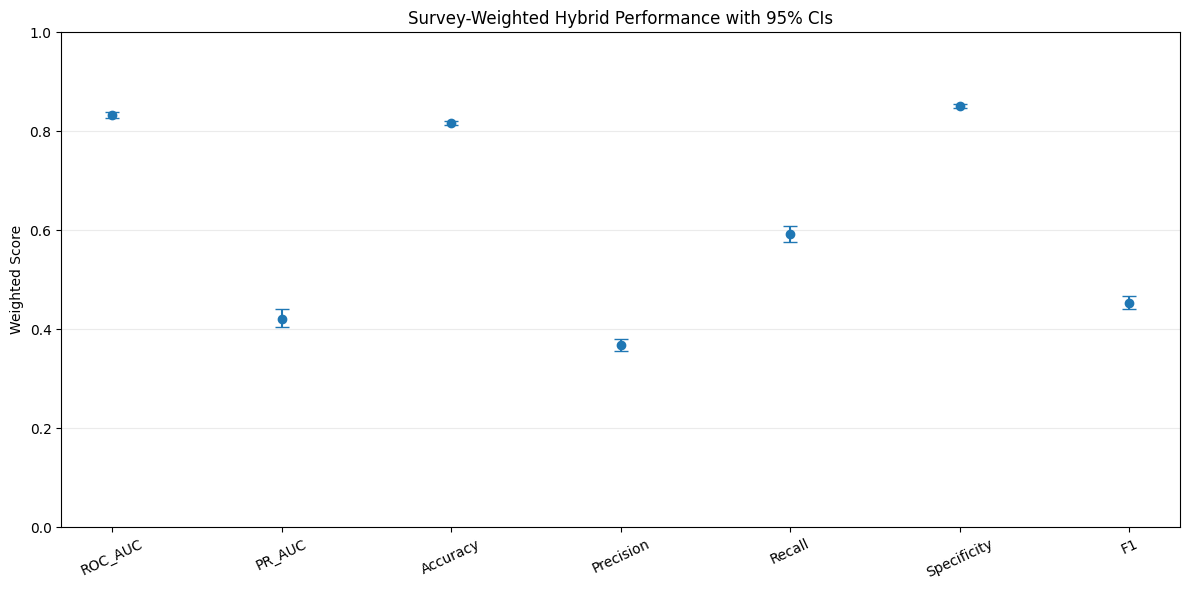


SURVEY-WEIGHTED RESULTS
              Metric  Point_Estimate  CI_95_Lower  CI_95_Upper  Valid_Bootstrap_Replicates
    Weighted_ROC_AUC    8.323920e-01 8.259980e-01 8.388400e-01                         500
     Weighted_PR_AUC    4.217090e-01 4.051400e-01 4.400710e-01                         500
   Weighted_Accuracy    8.174240e-01 8.131790e-01 8.218330e-01                         500
  Weighted_Precision    3.680370e-01 3.565800e-01 3.795690e-01                         500
     Weighted_Recall    5.922740e-01 5.760870e-01 6.092380e-01                         500
Weighted_Specificity    8.505170e-01 8.464980e-01 8.547880e-01                         500
         Weighted_F1    4.539750e-01 4.412710e-01 4.664530e-01                         500
 Weighted_Prevalence    1.281480e-01 1.243360e-01 1.319130e-01                         500
         Weighted_TP    2.736532e+06 2.628505e+06 2.845026e+06                         500
         Weighted_FP    4.698955e+06 4.558235e+06 4.823905e+06   

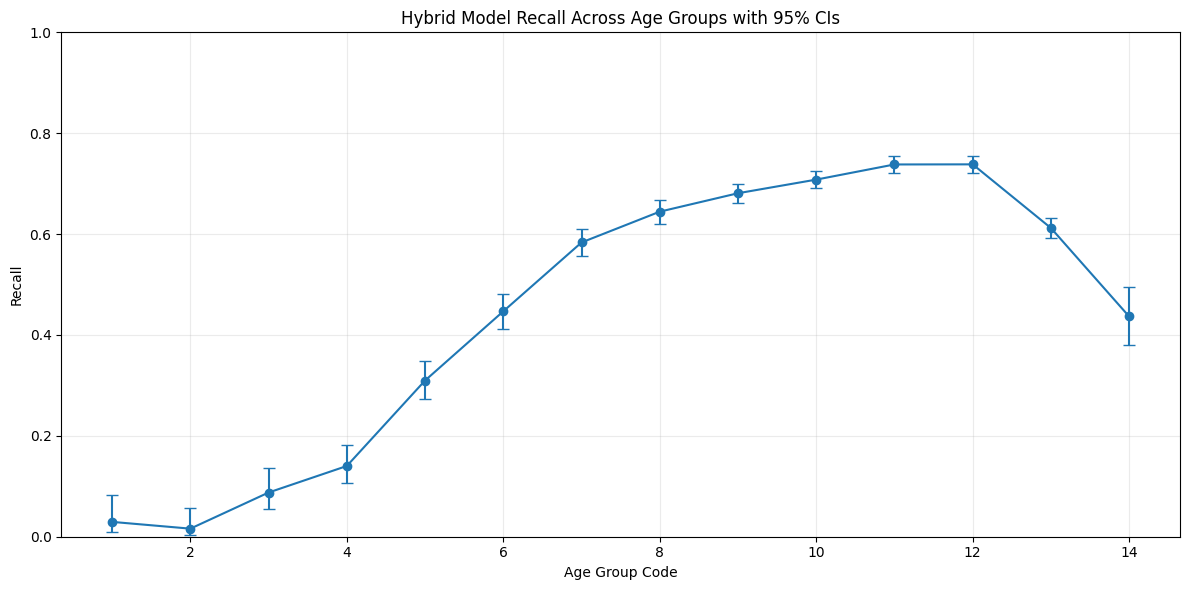

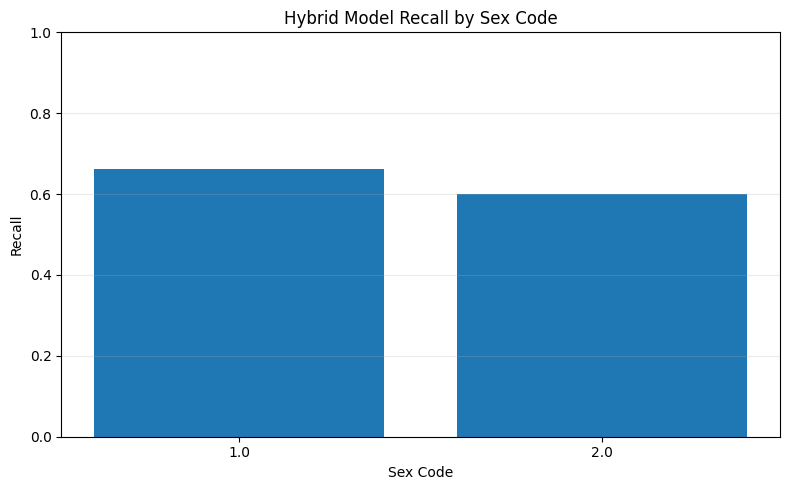


Intersectional fairness table saved.


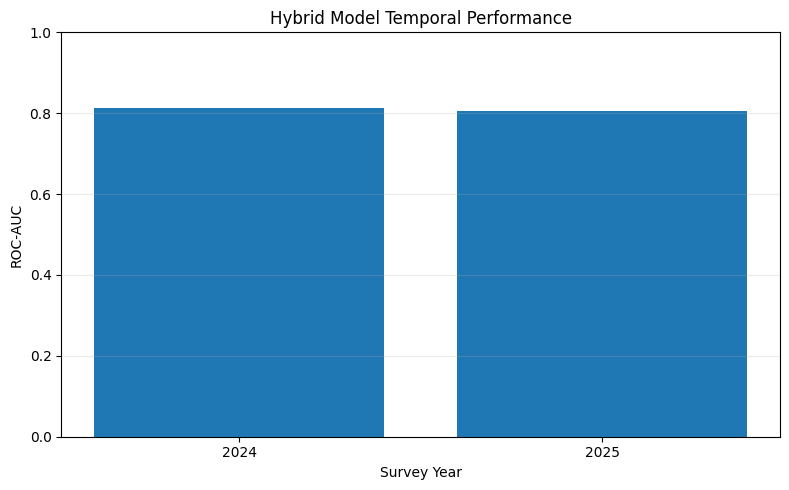


SCALABILITY RESULTS
 dataset_percentage   rows  spark_median_seconds  spark_std_seconds  pandas_median_seconds  pandas_std_seconds  pandas_conversion_seconds  spark_rows_per_second  pandas_rows_per_second  spark_to_pandas_time_ratio
               25.0 196788              0.395059           0.127729               0.032505            0.006028                   1.483188           4.981228e+05            6.053997e+06                   12.153623
               50.0 392520              0.470770           0.089574               0.057281            0.017520                   3.352978           8.337827e+05            6.852506e+06                    8.218576
               75.0 588120              0.329726           0.024736               0.054495            0.002756                   5.323534           1.783665e+06            1.079214e+07                    6.050543
              100.0 784473              0.300822           0.016352               0.064982            0.010809                 

In [ ]:

# ============================================================
# PHASE 9: FINAL RESEARCH VISUALIZATIONS & RESULT CONSOLIDATION
# Project: Big Data-Driven Explainable Hybrid Deep Learning
# ============================================================

import os
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")

REPORT_DIR = os.path.join(PROJECT_DIR, "final_report")
FIG_DIR = os.path.join(REPORT_DIR, "figures")
TABLE_DIR = os.path.join(REPORT_DIR, "tables")
SCREENSHOT_DIR = os.path.join(REPORT_DIR, "screenshots")

for folder in [REPORT_DIR, FIG_DIR, TABLE_DIR, SCREENSHOT_DIR]:
    os.makedirs(folder, exist_ok=True)

print("=" * 70)
print("PHASE 9: REPORT ASSET GENERATION")
print("=" * 70)

# ------------------------------------------------------------
# 2. AUDIT EXISTING RESULT FILES
# ------------------------------------------------------------

print("\nAUDITING EXISTING PROJECT RESULTS...")

inventory = []

for root, dirs, files in os.walk(RESULTS_DIR):
    for filename in files:
        full_path = os.path.join(root, filename)

        inventory.append({
            "File": filename,
            "Folder": os.path.relpath(root, PROJECT_DIR),
            "Extension": Path(filename).suffix.lower(),
            "Size_KB": round(os.path.getsize(full_path) / 1024, 2)
        })

inventory_df = pd.DataFrame(inventory)

inventory_df.to_csv(
    os.path.join(TABLE_DIR, "existing_result_inventory.csv"),
    index=False
)

print("Files found:", len(inventory_df))
print(inventory_df.to_string(index=False))

# ------------------------------------------------------------
# 3. FINAL MODEL COMPARISON TABLE
# Confirmed test results from completed experiments
# ------------------------------------------------------------

model_results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "ROC_AUC": 0.8050,
        "PR_AUC": 0.4111,
        "Accuracy": 0.7853,
        "Precision": 0.3676,
        "Recall": 0.5990,
        "Specificity": 0.8182,
        "F1": 0.4556
    },
    {
        "Model": "Random Forest",
        "ROC_AUC": 0.7889,
        "PR_AUC": 0.3945,
        "Accuracy": 0.7605,
        "Precision": 0.3376,
        "Recall": 0.6208,
        "Specificity": 0.7851,
        "F1": 0.4374
    },
    {
        "Model": "Spark GBT",
        "ROC_AUC": 0.7910,
        "PR_AUC": 0.3972,
        "Accuracy": 0.7732,
        "Precision": 0.3484,
        "Recall": 0.5883,
        "Specificity": 0.8059,
        "F1": 0.4376
    },
    {
        "Model": "XGBoost",
        "ROC_AUC": 0.8091,
        "PR_AUC": 0.4238,
        "Accuracy": 0.7846,
        "Precision": 0.3684,
        "Recall": 0.6105,
        "Specificity": 0.8154,
        "F1": 0.4595
    },
    {
        "Model": "DNN",
        "ROC_AUC": 0.8096,
        "PR_AUC": 0.4258,
        "Accuracy": 0.7777,
        "Precision": 0.3611,
        "Recall": 0.6272,
        "Specificity": 0.8042,
        "F1": 0.4583
    },
    {
        "Model": "Hybrid Stacking",
        "ROC_AUC": 0.8096,
        "PR_AUC": 0.4253,
        "Accuracy": 0.7764,
        "Precision": 0.3600,
        "Recall": 0.6310,
        "Specificity": 0.8021,
        "F1": 0.4585
    }
])

model_results.to_csv(
    os.path.join(TABLE_DIR, "final_model_comparison.csv"),
    index=False
)

print("\nFINAL MODEL COMPARISON")
print(model_results.round(4).to_string(index=False))

# ------------------------------------------------------------
# 4. GRAPH 1: ROC-AUC AND PR-AUC COMPARISON
# ------------------------------------------------------------

x = np.arange(len(model_results))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    x - width / 2,
    model_results["ROC_AUC"],
    width,
    label="ROC-AUC"
)

ax.bar(
    x + width / 2,
    model_results["PR_AUC"],
    width,
    label="PR-AUC"
)

ax.set_xticks(x)
ax.set_xticklabels(model_results["Model"], rotation=20, ha="right")
ax.set_ylabel("Score")
ax.set_title("ROC-AUC and PR-AUC Comparison Across Models")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "01_model_auc_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. GRAPH 2: ALL CLASSIFICATION METRICS
# ------------------------------------------------------------

metric_columns = [
    "Accuracy", "Precision", "Recall",
    "Specificity", "F1"
]

fig, ax = plt.subplots(figsize=(14, 7))

for metric in metric_columns:
    ax.plot(
        model_results["Model"],
        model_results[metric],
        marker="o",
        label=metric
    )

ax.set_ylabel("Score")
ax.set_title("Classification Metric Comparison")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    os.path.join(FIG_DIR, "02_classification_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 6. SURVEY-WEIGHTED RESULTS AND CONFIDENCE INTERVALS
# ------------------------------------------------------------

survey_file = os.path.join(
    RESULTS_DIR,
    "survey_design",
    "survey_weighted_metrics_with_CI.csv"
)

if os.path.exists(survey_file):

    survey_metrics = pd.read_csv(survey_file)

    survey_metrics.to_csv(
        os.path.join(TABLE_DIR, "survey_weighted_metrics.csv"),
        index=False
    )

    display_metrics = survey_metrics[
        survey_metrics["Metric"].isin([
            "Weighted_ROC_AUC",
            "Weighted_PR_AUC",
            "Weighted_Accuracy",
            "Weighted_Precision",
            "Weighted_Recall",
            "Weighted_Specificity",
            "Weighted_F1"
        ])
    ].copy()

    fig, ax = plt.subplots(figsize=(12, 6))

    labels = [
        x.replace("Weighted_", "")
        for x in display_metrics["Metric"]
    ]

    values = display_metrics["Point_Estimate"].to_numpy()

    lower = (
        values -
        display_metrics["CI_95_Lower"].to_numpy()
    )

    upper = (
        display_metrics["CI_95_Upper"].to_numpy() -
        values
    )

    ax.errorbar(
        labels,
        values,
        yerr=np.vstack([lower, upper]),
        fmt="o",
        capsize=5
    )

    ax.set_ylim(0, 1)
    ax.set_ylabel("Weighted Score")
    ax.set_title("Survey-Weighted Hybrid Performance with 95% CIs")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIG_DIR, "03_survey_weighted_performance.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print("\nSURVEY-WEIGHTED RESULTS")
    print(survey_metrics.round(6).to_string(index=False))

else:
    print("\nSurvey-weighted metrics file not found.")

# ------------------------------------------------------------
# 7. STATISTICAL SIGNIFICANCE TABLE
# ------------------------------------------------------------

significance_file = os.path.join(
    RESULTS_DIR,
    "statistical_significance",
    "paired_bootstrap_comparisons.csv"
)

if os.path.exists(significance_file):

    significance = pd.read_csv(significance_file)

    significance.to_csv(
        os.path.join(TABLE_DIR, "paired_bootstrap_comparisons.csv"),
        index=False
    )

    print("\nPAIRED BOOTSTRAP COMPARISONS")
    print(significance.to_string(index=False))

else:
    print("\nSignificance comparison file not found.")

# ------------------------------------------------------------
# 8. FAIRNESS TABLES AND GRAPHS
# ------------------------------------------------------------

fairness_dir = os.path.join(
    RESULTS_DIR,
    "fairness_confidence_intervals"
)

age_file = os.path.join(fairness_dir, "age_fairness_CI.csv")
sex_file = os.path.join(fairness_dir, "sex_fairness_CI.csv")
intersection_file = os.path.join(
    fairness_dir,
    "intersectional_fairness_CI.csv"
)

if os.path.exists(age_file):

    age_df = pd.read_csv(age_file)

    age_df.to_csv(
        os.path.join(TABLE_DIR, "age_fairness_CI.csv"),
        index=False
    )

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.errorbar(
        age_df["age_group"],
        age_df["recall"],
        yerr=np.vstack([
            age_df["recall"] - age_df["recall_CI_lower"],
            age_df["recall_CI_upper"] - age_df["recall"]
        ]),
        fmt="o-",
        capsize=4
    )

    ax.set_xlabel("Age Group Code")
    ax.set_ylabel("Recall")
    ax.set_title("Hybrid Model Recall Across Age Groups with 95% CIs")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIG_DIR, "04_age_wise_fairness.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

if os.path.exists(sex_file):

    sex_df = pd.read_csv(sex_file)

    sex_df.to_csv(
        os.path.join(TABLE_DIR, "sex_fairness_CI.csv"),
        index=False
    )

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(
        sex_df["sex"].astype(str),
        sex_df["recall"]
    )

    ax.set_xlabel("Sex Code")
    ax.set_ylabel("Recall")
    ax.set_title("Hybrid Model Recall by Sex Code")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.savefig(
        os.path.join(FIG_DIR, "05_sex_wise_fairness.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

if os.path.exists(intersection_file):

    intersection_df = pd.read_csv(intersection_file)

    intersection_df.to_csv(
        os.path.join(TABLE_DIR, "intersectional_fairness_CI.csv"),
        index=False
    )

    print("\nIntersectional fairness table saved.")

# ------------------------------------------------------------
# 9. TEMPORAL VALIDATION TABLE
# ------------------------------------------------------------

temporal_file = os.path.join(
    RESULTS_DIR,
    "hybrid_robustness",
    "hybrid_by_year.csv"
)

if os.path.exists(temporal_file):

    temporal_df = pd.read_csv(temporal_file)

    temporal_df.to_csv(
        os.path.join(TABLE_DIR, "temporal_validation.csv"),
        index=False
    )

    if "year" in temporal_df.columns:
        year_col = "year"
    elif "survey_year" in temporal_df.columns:
        year_col = "survey_year"
    else:
        year_col = None

    if year_col and "ROC_AUC" in temporal_df.columns:

        fig, ax = plt.subplots(figsize=(8, 5))

        ax.bar(
            temporal_df[year_col].astype(str),
            temporal_df["ROC_AUC"]
        )

        ax.set_xlabel("Survey Year")
        ax.set_ylabel("ROC-AUC")
        ax.set_title("Hybrid Model Temporal Performance")
        ax.set_ylim(0, 1)
        ax.grid(axis="y", alpha=0.25)

        plt.tight_layout()
        plt.savefig(
            os.path.join(FIG_DIR, "06_temporal_validation.png"),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

else:
    print("\nTemporal validation file not found.")

# ------------------------------------------------------------
# 10. SCALABILITY RESULTS
# ------------------------------------------------------------

scalability_file = os.path.join(
    RESULTS_DIR,
    "scalability",
    "controlled_scalability_benchmark.csv"
)

if os.path.exists(scalability_file):

    scalability_df = pd.read_csv(scalability_file)

    scalability_df.to_csv(
        os.path.join(TABLE_DIR, "scalability_comparison.csv"),
        index=False
    )

    print("\nSCALABILITY RESULTS")
    print(scalability_df.to_string(index=False))

    fraction_col = next(
        (c for c in scalability_df.columns if "fraction" in c.lower()),
        None
    )

    spark_col = next(
        (c for c in scalability_df.columns
         if "spark" in c.lower() and "median" in c.lower()),
        None
    )

    pandas_col = next(
        (c for c in scalability_df.columns
         if "pandas" in c.lower() and "median" in c.lower()),
        None
    )

    if fraction_col and spark_col and pandas_col:

        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(
            scalability_df[fraction_col],
            scalability_df[spark_col],
            marker="o",
            label="Spark"
        )

        ax.plot(
            scalability_df[fraction_col],
            scalability_df[pandas_col],
            marker="o",
            label="Pandas"
        )

        ax.set_xlabel("Dataset Fraction")
        ax.set_ylabel("Median Aggregation Time (seconds)")
        ax.set_title("Spark vs Pandas: Controlled Scalability Benchmark")
        ax.legend()
        ax.grid(alpha=0.25)

        plt.tight_layout()
        plt.savefig(
            os.path.join(FIG_DIR, "07_scalability_comparison.png"),
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

else:
    print("\nControlled scalability benchmark not found.")

# ------------------------------------------------------------
# 11. COPY EXISTING SHAP AND CALIBRATION FIGURES
# ------------------------------------------------------------

def copy_if_exists(source, destination_name):

    if os.path.exists(source):

        shutil.copy2(
            source,
            os.path.join(FIG_DIR, destination_name)
        )

        print("Copied:", destination_name)
        return True

    print("Not found:", source)
    return False


explain_dir = os.path.join(
    RESULTS_DIR,
    "explainability"
)

copy_if_exists(
    os.path.join(explain_dir, "shap_summary_xgboost.png"),
    "08_shap_summary.png"
)

copy_if_exists(
    os.path.join(explain_dir, "shap_bmi_dependence.png"),
    "09_shap_bmi_dependence.png"
)

copy_if_exists(
    os.path.join(explain_dir, "shap_age_group_distribution.png"),
    "10_shap_age_group_distribution.png"
)

copy_if_exists(
    os.path.join(explain_dir, "corrected_grouped_shap.png"),
    "11_corrected_grouped_shap.png"
)

# Copy calibration images if present
calibration_dir = os.path.join(RESULTS_DIR, "calibration")

if os.path.isdir(calibration_dir):

    for filename in os.listdir(calibration_dir):

        if filename.lower().endswith(".png"):

            copy_if_exists(
                os.path.join(calibration_dir, filename),
                filename
            )

# ------------------------------------------------------------
# 12. CREATE FIGURE AND TABLE INDEX
# ------------------------------------------------------------

figure_files = sorted([
    f for f in os.listdir(FIG_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

table_files = sorted([
    f for f in os.listdir(TABLE_DIR)
    if f.lower().endswith(".csv")
])

pd.DataFrame({
    "Figure_Number": range(1, len(figure_files) + 1),
    "Figure_File": figure_files
}).to_csv(
    os.path.join(TABLE_DIR, "figure_index.csv"),
    index=False
)

pd.DataFrame({
    "Table_Number": range(1, len(table_files) + 1),
    "Table_File": table_files
}).to_csv(
    os.path.join(TABLE_DIR, "table_index.csv"),
    index=False
)

# ------------------------------------------------------------
# 13. FINAL PHASE 9 SUMMARY
# ------------------------------------------------------------

summary = {
    "project": "Big Data-Driven Explainable Hybrid Deep Learning Framework for Diabetes Classification",
    "phase": "Phase 9",
    "models_compared": len(model_results),
    "figures_generated_or_copied": len(figure_files),
    "tables_generated": len(table_files),
    "figure_directory": FIG_DIR,
    "table_directory": TABLE_DIR,
    "report_directory": REPORT_DIR,
    "notes": [
        "Model comparison values use previously recorded test results.",
        "Survey-weighted confidence intervals use the corrected PSU mapping bootstrap.",
        "Fairness confidence intervals are respondent-level Wilson intervals.",
        "Scalability experiment uses local Spark and a single Colab machine.",
        "Missing source figures are not fabricated."
    ]
}

with open(
    os.path.join(REPORT_DIR, "phase9_summary.json"),
    "w"
) as f:
    json.dump(summary, f, indent=4)

print("\n" + "=" * 70)
print("PHASE 9 COMPLETED")
print("=" * 70)

print("Figures:", len(figure_files))
print("Tables:", len(table_files))
print("\nFIGURES:")
for item in figure_files:
    print(" -", item)

print("\nTABLES:")
for item in table_files:
    print(" -", item)

print("\nREPORT ASSET FOLDER:")
print(REPORT_DIR)


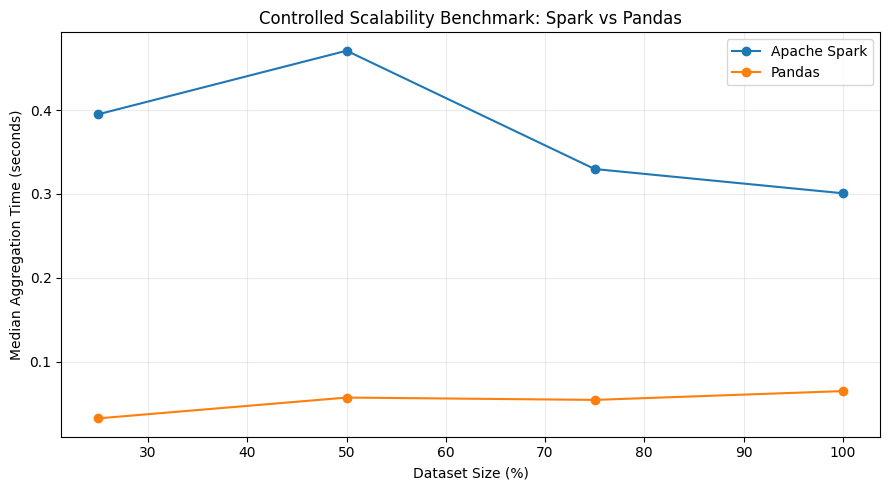

Saved: /content/drive/MyDrive/Diabetes_BigData_Project/final_report/figures/07_scalability_comparison.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/Diabetes_BigData_Project"

source = os.path.join(
    PROJECT_DIR,
    "results/scalability/controlled_scalability_benchmark.csv"
)

output = os.path.join(
    PROJECT_DIR,
    "final_report/figures/07_scalability_comparison.png"
)

df = pd.read_csv(source)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    df["dataset_percentage"],
    df["spark_median_seconds"],
    marker="o",
    label="Apache Spark"
)

ax.plot(
    df["dataset_percentage"],
    df["pandas_median_seconds"],
    marker="o",
    label="Pandas"
)

ax.set_xlabel("Dataset Size (%)")
ax.set_ylabel("Median Aggregation Time (seconds)")
ax.set_title("Controlled Scalability Benchmark: Spark vs Pandas")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(output, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", output)
